In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import time

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.optimize import minimize

In [2]:
# Load data
prices = pd.read_csv("/kaggle/input/datasets/cheryleugene/stok-saham/historical_prices.csv")
prices["date"] = pd.to_datetime(prices["date"])

In [3]:
# DATA OVERVIEW
print("Jumlah baris:", len(prices))
print("Jumlah ticker:", prices["ticker"].nunique())
print("Tanggal awal:", prices["date"].min())
print("Tanggal akhir:", prices["date"].max())

Jumlah baris: 51244
Jumlah ticker: 50
Tanggal awal: 2022-01-03 00:00:00
Tanggal akhir: 2026-08-31 00:00:00


Dataset mencakup 50 saham selama periode Januari 2022 hingga Agustus 2026. Jumlah observasi yang cukup besar memungkinkan analisis historis lintas saham dan lintas waktu.

Namun, tidak semua saham memiliki periode observasi yang sama. Saham yang baru tercatat atau baru tersedia dalam dataset, seperti EMAS.JK dan CDIA.JK, memiliki data historis lebih pendek dibandingkan saham yang sudah tersedia sejak awal 2022.

### Missing Values
Pemeriksaan missing values dilakukan untuk mengetahui apakah terdapat nilai kosong pada kolom tanggal, ticker, harga penutupan, dan volume. Nilai kosong dapat memengaruhi perhitungan return dan analisis risiko.


### Duplicate Records
Pemeriksaan duplikasi dilakukan berdasarkan kombinasi tanggal dan ticker. Setiap kombinasi seharusnya hanya memiliki satu observasi harga saham pada tanggal yang sama.

In [4]:
# MISSING VALUES
print(prices.isnull().sum())

# DUPLICATE CHECK
duplicate_count = prices.duplicated(
    ["date", "ticker"]
).sum()

print("Duplicate date-ticker rows:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate date-ticker combinations found. "
    )

date              0
ticker            0
adjusted_close    0
volume            0
dtype: int64
Duplicate date-ticker rows: 0


Tidak terdapat missing values pada empat kolom dataset. Meskipun demikian, hasil ini tidak berarti semua saham memiliki data untuk setiap tanggal perdagangan, karena tanggal awal pencatatan dan jumlah observasi berbeda antar-saham.

Tidak ditemukan baris duplikat berdasarkan kombinasi date dan ticker. Dengan demikian, tidak terdapat observasi tanggal–saham yang tercatat lebih dari sekali.

In [5]:
# OBSERVATIONS PER STOCK
observations = prices.groupby("ticker").agg(
    observations=("adjusted_close", "count"),
    first_date=("date", "min"),
    last_date=("date", "max")
)

print(observations.sort_values("observations").head(10))

         observations first_date  last_date
ticker                                     
EMAS.JK           223 2025-09-23 2026-08-31
CDIA.JK           275 2025-07-09 2026-08-31
AADI.JK           406 2024-12-05 2026-08-31
BREN.JK           685 2023-10-09 2026-08-31
AMMN.JK           748 2023-07-07 2026-08-31
MBMA.JK           794 2023-04-18 2026-08-31
NCKL.JK           798 2023-04-12 2026-08-31
CUAN.JK           820 2023-03-08 2026-08-31
MORA.JK           970 2022-08-08 2026-08-31
GOTO.JK          1045 2022-04-11 2026-08-31


Periode observasi berbeda karena beberapa saham mulai tersedia setelah Januari 2022. Hal ini penting ketika membandingkan return kumulatif, CAGR, volatilitas, dan drawdown. Saham dengan periode observasi pendek tidak boleh langsung dianggap lebih baik hanya karena return historisnya tinggi.

### Pemeriksaan Tanggal yang Hilang
Pemeriksaan tanggal digunakan untuk mengetahui apakah terdapat tanggal observasi yang hilang di antara tanggal pertama dan terakhir setiap saham.

Pemeriksaan ini harus menggunakan kalender perdagangan yang sesuai. Membandingkan data hanya terhadap tanggal yang muncul dalam dataset gabungan belum cukup untuk membuktikan bahwa semua hari perdagangan resmi BEI sudah tercakup.

In [6]:
# CHECK MISSING DATES WITHIN EACH STOCK'S AVAILABLE PERIOD
all_dates = pd.Index(sorted(prices["date"].dropna().unique()))
gap_results = []

for ticker, group in prices.groupby("ticker"):
    first_date = group["date"].min()
    last_date = group["date"].max()

    # Tanggal yang tersedia pada dataset secara keseluruhan
    # di antara tanggal pertama dan terakhir saham
    expected_dates = all_dates[
        (all_dates >= first_date) &
        (all_dates <= last_date)
    ]

    actual_dates = pd.Index(group["date"].dropna().unique())

    missing_dates = expected_dates.difference(actual_dates)

    gap_results.append({
        "ticker": ticker,
        "first_date": first_date,
        "last_date": last_date,
        "actual_rows": len(actual_dates),
        "expected_dates": len(expected_dates),
        "missing_dates": len(missing_dates),
        "missing_pct": (
            len(missing_dates) / len(expected_dates) * 100
            if len(expected_dates) > 0 else 0
        )
    })

gap_check = pd.DataFrame(gap_results)

print("\nSaham dengan tanggal yang hilang terbanyak:")
print(
    gap_check.sort_values(
        "missing_dates", ascending=False
    ).head(15).to_string(index=False)
)


Saham dengan tanggal yang hilang terbanyak:
 ticker first_date  last_date  actual_rows  expected_dates  missing_dates  missing_pct
AADI.JK 2024-12-05 2026-08-31          406             406              0          0.0
ADMR.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ADRO.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
AMMN.JK 2023-07-07 2026-08-31          748             748              0          0.0
AMRT.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ANTM.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ASII.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBCA.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBNI.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBRI.JK 2022-01-03 2026-08-31         1112            1112              0          0.

- Hasil pemeriksaan terhadap tanggal yang muncul dalam dataset gabungan menunjukkan 0 tanggal hilang pada saham-saham yang ditampilkan, termasuk ADMR.JK, ADRO.JK, AMRT.JK, ANTM.JK, ASII.JK, BBCA.JK, BBNI.JK, BBRI.JK, dan BMRI.JK.
- Tidak ditemukan tanggal hilang relatif terhadap kalender tanggal yang digunakan dalam pemeriksaan. Akan tetapi, hasil ini bukan bukti bahwa seluruh tanggal perdagangan resmi BEI telah tercakup. Untuk memverifikasi kelengkapan kalender perdagangan, dataset perlu dibandingkan dengan kalender resmi BEI.

### Transformasi Data ke Format Pivot
Data awal berbentuk long format, yaitu setiap baris merepresentasikan satu saham pada satu tanggal. Untuk analisis return dan korelasi antar-saham, data diubah menjadi wide format sehingga setiap ticker menjadi kolom dan setiap tanggal menjadi baris.

In [7]:
# Ubah ke bentuk tabel harga
price_table = prices.pivot(
    index="date",
    columns="ticker",
    values="adjusted_close"
).sort_index()

In [8]:
# Return harian
daily_returns = price_table.pct_change(fill_method=None)

In [9]:
print("Total trading dates:", len(price_table))
print("Total stock columns:", len(daily_returns.columns))
print("Missing daily returns:", int(daily_returns.isna().sum().sum()))

display(price_table.head())
display(daily_returns.head())

Total trading dates: 1112
Total stock columns: 50
Missing daily returns: 4406


ticker,AADI.JK,ADMR.JK,ADRO.JK,AMMN.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,...,PANI.JK,PGUN.JK,PTRO.JK,SMMA.JK,SRAJ.JK,SUPR.JK,TLKM.JK,TPIA.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,NaN,125.224693,801.114624,NaN,1130.200073,1812.000854,3831.252441,6253.108398,2551.722900,2973.502686,...,152.520157,394.052399,167.402664,11775.0,314.0,15600.0,3125.690674,1797.421509,12746.706055,3298.706543
2022-01-04,NaN,168.821426,777.453003,NaN,1098.040039,1781.026489,3864.712646,6317.133301,2665.554199,2959.275391,...,141.879211,388.081909,172.904175,11775.0,312.0,15600.0,3118.212891,1791.223633,12805.113281,3314.303223
2022-01-05,NaN,226.332031,757.171631,NaN,1102.634277,1757.795532,3730.869873,6359.816895,2637.096436,2994.843750,...,131.947678,392.062225,174.476028,11775.0,308.0,15600.0,3028.479980,1803.619507,12819.713867,3283.110352
2022-01-06,NaN,281.987427,777.453003,NaN,1061.285522,1726.821167,3797.790771,6381.159180,2637.096436,2959.275391,...,131.238266,382.111420,170.546387,11775.0,318.0,15600.0,3080.824219,1785.025513,12688.303711,3298.706543
2022-01-07,NaN,352.484314,821.395996,NaN,1061.285522,1726.821167,3814.521729,6530.550293,2684.526123,2980.616455,...,128.755402,392.062225,176.833817,11775.0,314.0,15600.0,3118.212891,1797.421509,12951.122070,3290.908691


ticker,AADI.JK,ADMR.JK,ADRO.JK,AMMN.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,...,PANI.JK,PGUN.JK,PTRO.JK,SMMA.JK,SRAJ.JK,SUPR.JK,TLKM.JK,TPIA.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,NaN,0.348148,-0.029536,NaN,-0.028455,-0.017094,0.008733,0.010239,0.044610,-0.004785,...,-0.069767,-0.015152,0.032864,0.0,-0.006369,0.0,-0.002392,-0.003448,0.004582,0.004728
2022-01-05,NaN,0.340659,-0.026087,NaN,0.004184,-0.013044,-0.034632,0.006757,-0.010676,0.012019,...,-0.070000,0.010256,0.009091,0.0,-0.012821,0.0,-0.028777,0.006920,0.001140,-0.009412
2022-01-06,NaN,0.245902,0.026786,NaN,-0.037500,-0.017621,0.017937,0.003356,0.000000,-0.011877,...,-0.005376,-0.025381,-0.022523,0.0,0.032468,0.0,0.017284,-0.010309,-0.010251,0.004750
2022-01-07,NaN,0.250000,0.056522,NaN,0.000000,0.000000,0.004405,0.023411,0.017986,0.007212,...,-0.018919,0.026042,0.036866,0.0,-0.012579,0.0,0.012136,0.006944,0.020713,-0.002364


Tabel harga menjadi matriks dengan 1.112 tanggal dan 50 kolom saham. Nilai harga yang tidak tersedia sebelum awal periode observasi suatu saham tetap menjadi NaN.

---

Jumlah 4.406 missing daily returns bukan berarti semuanya merupakan kesalahan data. Nilai tersebut dapat muncul karena:
- Return pada tanggal pertama observasi belum dapat dihitung.
- Harga saham belum tersedia pada sebagian periode historis.
- Terdapat nilai harga yang tidak tersedia pada tanggal tertentu.
Karena itu, missing return perlu dibedakan dari return nol. Return nol berarti harga tidak berubah menurut data yang tersedia, sedangkan NaN berarti return tidak dapat dihitung.

### Statistik Deskriptif Return dan Risiko
Analisis statistik deskriptif dilakukan untuk memahami karakteristik return dan risiko masing-masing saham selama periode pengamatan.

Metrik yang dihitung:
- Mean daily return: rata-rata return harian.
- Median daily return: nilai tengah return harian.
- Daily return standard deviation: tingkat penyebaran return harian.
- Annualized return: rata-rata return harian yang disetahunkan menggunakan pendekatan aritmetika.
- Annualized volatility: volatilitas harian yang disetahunkan.
- Total return: perubahan harga kumulatif sepanjang periode observasi.
- CAGR: tingkat pertumbuhan tahunan majemuk.
- Sharpe ratio: return berlebih terhadap tingkat bebas risiko relatif terhadap volatilitas.
- Maximum drawdown: penurunan terbesar dari puncak nilai historis ke titik terendah berikutnya.

In [10]:
# Statistik return dan risiko
daily_mean = daily_returns.mean()
daily_std = daily_returns.std()

annual_return = daily_mean * 252
annual_volatility = daily_std * np.sqrt(252)

In [11]:
# Return kumulatif berdasarkan harga pertama dan terakhir
first_price = price_table.apply(
    lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
)
last_price = price_table.apply(
    lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan
)

total_return = last_price / first_price - 1

In [12]:
# CAGR menggunakan durasi kalender masing-masing saham
first_date = price_table.apply(
    lambda s: s.first_valid_index()
)

last_date = price_table.apply(
    lambda s: s.last_valid_index()
)

years = (
    (last_date - first_date).dt.days / 365.25
).replace(0, np.nan)

cagr = (last_price / first_price) ** (1 / years) - 1

In [13]:
# Drawdown setiap saham
drawdown = price_table.div(
    price_table.cummax()
).sub(1)

max_drawdown = drawdown.min()

In [14]:
summary = pd.DataFrame({
    "observations": daily_returns.count(),
    "mean_daily_return": daily_mean,
    "median_daily_return": daily_returns.median(),
    "daily_return_std": daily_std,
    "annualized_return": annual_return,
    "annualized_volatility": annual_volatility,
    "total_return": total_return,
    "CAGR": cagr,
    "sharpe_ratio_simple": (
        annual_return / annual_volatility.replace(0, np.nan)
    ),
    "max_drawdown": max_drawdown
})

# DESCRIPTIVE STATISTICS
print(summary.describe().round(4))

       observations  mean_daily_return  median_daily_return  daily_return_std  \
count       50.0000            50.0000              50.0000           50.0000   
mean      1023.8800             0.0017              -0.0000            0.0337   
std        213.5365             0.0017               0.0005            0.0125   
min        222.0000            -0.0012              -0.0033            0.0150   
25%       1111.0000             0.0004               0.0000            0.0238   
50%       1111.0000             0.0011               0.0000            0.0320   
75%       1111.0000             0.0025               0.0000            0.0427   
max       1111.0000             0.0059               0.0008            0.0650   

       annualized_return  annualized_volatility  total_return     CAGR  \
count            50.0000                50.0000       50.0000  50.0000   
mean              0.4220                 0.5352        5.1009   0.3536   
std               0.4254                 0.1985 

1. Return rata-rata: rata-rata annualized return antar-saham sebesar 42,20%, tetapi penyebarannya lebar. Nilai rata-rata ini tidak berarti seluruh saham menghasilkan return positif.
2. Volatilitas: rata-rata annualized volatility sebesar 53,52%, menunjukkan bahwa saham-saham dalam sampel memiliki variasi return yang cukup besar.
3. Total return: rata-rata total return tercatat 510,09%, tetapi nilai maksimum yang tinggi menunjukkan bahwa distribusi performa saham sangat tidak merata.
4. CAGR: rata-rata CAGR sebesar 35,36%, lebih rendah daripada rata-rata annualized return aritmetika.
5. Sharpe ratio: rata-rata Sharpe ratio sederhana sebesar 0,6705. Angka ini harus ditafsirkan sesuai asumsi tingkat bebas risiko yang digunakan.
6. Maximum drawdown: rata-rata maximum drawdown sebesar -61,65%. Sebagian saham mengalami penurunan historis yang sangat dalam.
Penting: hasil return yang sangat tinggi tidak otomatis menunjukkan investasi yang lebih baik. Return perlu dinilai bersama volatilitas, drawdown, likuiditas, dan panjang periode observasi.

### Perbandingan Performa dan Risiko Saham

Analisis ini mengidentifikasi 10 saham teratas berdasarkan total return dan CAGR, serta 10 saham dengan volatilitas tahunan dan maximum drawdown tertinggi. Tujuannya adalah membandingkan saham berdasarkan pertumbuhan investasi dan tingkat risikonya selama periode pengamatan.

In [15]:
# TOP 10 TOTAL RETURN
print(
    summary.sort_values("total_return", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
SRAJ.JK          1111             0.0042                  0.0   
PANI.JK          1111             0.0044                  0.0   
PTRO.JK          1111             0.0041                  0.0   
CUAN.JK           819             0.0059                  0.0   
PGUN.JK          1111             0.0043                  0.0   
ADMR.JK          1111             0.0032                  0.0   
MPRO.JK          1111             0.0034                  0.0   
MORA.JK           969             0.0035                  0.0   
MLPT.JK          1111             0.0035                  0.0   
BRMS.JK          1111             0.0026                  0.0   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
SRAJ.JK            0.0417             1.0650                 0.6621   
PANI.J

In [16]:
# TOP 10 CAGR
print(
    summary.sort_values("CAGR", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
EMAS.JK           222             0.0055               0.0000   
CUAN.JK           819             0.0059               0.0000   
CDIA.JK           274             0.0055              -0.0033   
SRAJ.JK          1111             0.0042               0.0000   
PANI.JK          1111             0.0044               0.0000   
PTRO.JK          1111             0.0041               0.0000   
PGUN.JK          1111             0.0043               0.0000   
MORA.JK           969             0.0035               0.0000   
ADMR.JK          1111             0.0032               0.0000   
MPRO.JK          1111             0.0034               0.0000   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
EMAS.JK            0.0477             1.3924                 0.7569   
CUAN.J

In [17]:
# TOP 10 VOLATILITY
print(
    summary.sort_values("annualized_volatility", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
CDIA.JK           274             0.0055              -0.0033   
CUAN.JK           819             0.0059               0.0000   
MLPT.JK          1111             0.0035               0.0000   
BREN.JK           684             0.0032               0.0000   
PGUN.JK          1111             0.0043               0.0000   
PANI.JK          1111             0.0044               0.0000   
MPRO.JK          1111             0.0034               0.0000   
EMAS.JK           222             0.0055               0.0000   
MORA.JK           969             0.0035               0.0000   
PTRO.JK          1111             0.0041               0.0000   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
CDIA.JK            0.0650             1.3852                 1.0316   
CUAN.J

In [18]:
# TOP 10 DEEPEST DRAWDOWN
print(
    summary.sort_values("max_drawdown")
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
MLPT.JK          1111             0.0035                  0.0   
DSSA.JK          1111             0.0024                  0.0   
TPIA.JK          1111             0.0009                  0.0   
GOTO.JK          1044            -0.0012                  0.0   
CUAN.JK           819             0.0059                  0.0   
MDKA.JK          1111             0.0003                  0.0   
PGUN.JK          1111             0.0043                  0.0   
BREN.JK           684             0.0032                  0.0   
UNVR.JK          1111            -0.0002                  0.0   
INCO.JK          1111             0.0006                  0.0   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
MLPT.JK            0.0542             0.8906                 0.8604   
DSSA.J

Total return dan CAGR menunjukkan pertumbuhan investasi historis, sedangkan volatilitas mengukur fluktuasi return dan maximum drawdown menunjukkan penurunan terbesar dari puncak ke titik terendah.

Saham dengan return tertinggi belum tentu memiliki risiko terendah. Oleh karena itu, keempat metrik perlu dipertimbangkan bersama untuk mengidentifikasi karakteristik saham dan mendukung keputusan diversifikasi dalam Smart Portfolio Optimizer.

### Pemeriksaan Return Ekstrem
Return harian dengan perubahan lebih dari 20% secara absolut diperiksa untuk mengidentifikasi observasi yang perlu ditinjau lebih lanjut.

Pemeriksaan ini tidak bertujuan menghapus return ekstrem secara otomatis. Perubahan besar dapat disebabkan oleh pergerakan pasar yang benar-benar terjadi, tetapi juga dapat menunjukkan efek corporate action atau anomali pada data harga.

In [19]:
# Periksa return harian ekstrem
returns_long = daily_returns.stack().rename("daily_return").reset_index()
returns_long.columns = ["date", "ticker", "daily_return"]

extreme_returns = returns_long[
    returns_long["daily_return"].abs() > 0.20
].sort_values("daily_return", ascending=False)

print("Jumlah return harian dengan perubahan lebih dari 20%:",
      len(extreme_returns))

print(extreme_returns.head(20).round(4))

Jumlah return harian dengan perubahan lebih dari 20%: 159
            date   ticker  daily_return
7135  2022-09-23  SRAJ.JK        0.3500
14234 2023-05-31  GOTO.JK        0.3486
0     2022-01-04  ADMR.JK        0.3481
40    2022-01-05  ADMR.JK        0.3407
41810 2025-11-11  BUMI.JK        0.3200
49830 2026-07-21  MLPT.JK        0.2524
20163 2023-12-07  TPIA.JK        0.2500
120   2022-01-07  ADMR.JK        0.2500
37712 2025-07-15  CDIA.JK        0.2500
48056 2026-05-29  BREN.JK        0.2500
1430  2022-02-23  PANI.JK        0.2500
20250 2023-12-11  PANI.JK        0.2500
37565 2025-07-10  CDIA.JK        0.2500
20064 2023-12-05  PTRO.JK        0.2500
8180  2022-10-28  MPRO.JK        0.2500
17995 2023-10-04  MPRO.JK        0.2500
12244 2023-03-15  CUAN.JK        0.2500
8311  2022-11-02  SRAJ.JK        0.2500
20771 2023-12-28  SRAJ.JK        0.2500
26452 2024-07-12  MPRO.JK        0.2500


Terdapat 159 observasi return dengan perubahan absolut lebih dari 20%. Beberapa saham memiliki lonjakan harga berulang pada periode tertentu.

Sebagai contoh, ADMR.JK pada awal 2022 dan CDIA.JK pada Juli 2025 menunjukkan beberapa perubahan harga besar. Pola seperti ini perlu ditinjau menggunakan data harga sumber, informasi corporate action, dan kalender perdagangan.

**Keputusan pengolahan data:** observasi ekstrem tidak boleh dihapus hanya karena melewati ambang 20%. Jika datanya valid, return tersebut merupakan bagian dari karakteristik historis saham.

### Analisis Return Nol dan Harga Stagnan
Return nol menunjukkan bahwa harga pada dua observasi berurutan tidak berubah menurut data yang tersedia. Frekuensi return nol yang tinggi dapat berkaitan dengan harga yang jarang berubah, aktivitas perdagangan yang rendah, atau karakteristik data sumber. Analisis ini menghitung persentase return nol untuk setiap saham.

In [20]:
# Hitung berapa banyak return harian yang nol
zero_return_pct = (
    daily_returns.eq(0).sum() /
    daily_returns.notna().sum() * 100
).sort_values(ascending=False)

print("Saham dengan persentase return nol tertinggi:")
print(zero_return_pct.head(10).round(2))

Saham dengan persentase return nol tertinggi:
ticker
SUPR.JK    91.99
SMMA.JK    66.34
DSSA.JK    38.88
MPRO.JK    37.26
SRAJ.JK    36.09
DCII.JK    34.83
CASA.JK    34.65
PGUN.JK    28.80
GOTO.JK    27.39
DNET.JK    27.27
dtype: float64


SUPR.JK memiliki persentase return nol tertinggi, yaitu 91,99%. SMMA.JK berada di posisi kedua dengan 66,34%.

Return nol yang sangat sering dapat membuat volatilitas historis terlihat lebih rendah daripada risiko ekonomi yang sebenarnya. Kondisi ini juga berpotensi memengaruhi korelasi dan hasil optimisasi portofolio.

Akan tetapi, return nol tidak selalu menandakan kesalahan. Interpretasi harus mempertimbangkan volume perdagangan dan kualitas harga.

### Validasi Return Ekstrem

Analisis ini mengidentifikasi return harian ekstrem dengan perubahan lebih dari 20%, memeriksa harga sebelum dan sesudah kejadian, serta memvalidasi beberapa observasi menggunakan data historis dari Yahoo Finance. Tujuannya adalah mengetahui apakah perubahan harga tersebut mencerminkan pergerakan pasar yang sebenarnya atau kemungkinan anomali data sebelum digunakan dalam analisis portofolio.

In [21]:
# Gabungkan harga dengan return harian
price_long = price_table.stack().rename(
    "adjusted_close"
).reset_index()

price_long.columns = ["date", "ticker", "adjusted_close"]

returns_long = daily_returns.stack().rename(
    "daily_return"
).reset_index()

returns_long.columns = ["date", "ticker", "daily_return"]

In [22]:
# Ambil return ekstrem
extreme_returns = returns_long[
    returns_long["daily_return"].abs() > 0.20
].copy()

# Gabungkan dengan harga
extreme_check = extreme_returns.merge(
    price_long,
    on=["date", "ticker"],
    how="left"
)

In [23]:
# Cari harga sebelumnya dan sesudahnya
extreme_check["previous_price"] = extreme_check.apply(
    lambda r: price_table.loc[
        price_table.index < r["date"], r["ticker"]
    ].dropna().iloc[-1]
    if (
        (price_table.index < r["date"]).any()
        and price_table.loc[
            price_table.index < r["date"], r["ticker"]
        ].notna().any()
    ) else np.nan,
    axis=1
)

extreme_check["next_price"] = extreme_check.apply(
    lambda r: price_table.loc[
        price_table.index > r["date"], r["ticker"]
    ].dropna().iloc[0]
    if (
        (price_table.index > r["date"]).any()
        and price_table.loc[
            price_table.index > r["date"], r["ticker"]
        ].notna().any()
    ) else np.nan,
    axis=1
)

print(
    extreme_check[
        [
            "date", "ticker", "previous_price",
            "adjusted_close", "next_price", "daily_return"
        ]
    ].sort_values("daily_return", ascending=False).head(30).round(4)
)

          date   ticker  previous_price  adjusted_close  next_price  \
23  2022-09-23  SRAJ.JK        100.0000        135.0000    141.0000   
42  2023-05-31  GOTO.JK        109.0000        147.0000    125.0000   
0   2022-01-04  ADMR.JK        125.2247        168.8214    226.3320   
1   2022-01-05  ADMR.JK        168.8214        226.3320    281.9874   
130 2025-11-11  BUMI.JK        150.0000        198.0000    192.0000   
155 2026-07-21  MLPT.JK       1038.0000       1300.0000   1625.0000   
67  2023-12-07  TPIA.JK       3461.9807       4327.4766   4675.6641   
3   2022-01-07  ADMR.JK        281.9874        352.4843    439.6778   
105 2025-07-15  CDIA.JK        494.8207        618.5259    771.9203   
141 2026-05-29  BREN.JK       2636.6748       3295.8438   4114.8110   
10  2022-02-23  PANI.JK        249.7074        312.1343    353.9886   
69  2023-12-11  PANI.JK       4692.9224       5866.1533   5067.3574   
101 2025-07-10  CDIA.JK        253.3482        316.6853    395.8566   
64  20

In [24]:
# Pilih 10 observasi ekstrem teratas
extreme_dates = extreme_check.sort_values(
    "daily_return", ascending=False
).head(10)

for _, row in extreme_dates.iterrows():
    ticker = row["ticker"]
    date = pd.Timestamp(row["date"])

    series = price_table[ticker].dropna()

    # Ambil 3 observasi sebelum dan sesudah tanggal ekstrem
    window = series.loc[
        (series.index >= date - pd.Timedelta(days=7)) &
        (series.index <= date + pd.Timedelta(days=7))
    ]

    print(f"\n=== {ticker} | {date.date()} ===")
    print(window)


=== SRAJ.JK | 2022-09-23 ===
date
2022-09-16    132.0
2022-09-19    123.0
2022-09-20    115.0
2022-09-21    107.0
2022-09-22    100.0
2022-09-23    135.0
2022-09-26    141.0
2022-09-27    163.0
2022-09-28    152.0
2022-09-29    169.0
2022-09-30    158.0
Name: SRAJ.JK, dtype: float64

=== GOTO.JK | 2023-05-31 ===
date
2023-05-24    114.0
2023-05-25    111.0
2023-05-26    104.0
2023-05-29    108.0
2023-05-30    109.0
2023-05-31    147.0
2023-06-05    125.0
2023-06-06    119.0
2023-06-07    116.0
Name: GOTO.JK, dtype: float64

=== ADMR.JK | 2022-01-04 ===
date
2022-01-03    125.224693
2022-01-04    168.821426
2022-01-05    226.332031
2022-01-06    281.987427
2022-01-07    352.484314
2022-01-10    439.677795
2022-01-11    547.278259
Name: ADMR.JK, dtype: float64

=== ADMR.JK | 2022-01-05 ===
date
2022-01-03    125.224693
2022-01-04    168.821426
2022-01-05    226.332031
2022-01-06    281.987427
2022-01-07    352.484314
2022-01-10    439.677795
2022-01-11    547.278259
2022-01-12    681.77

### Validasi Data Historis Saham

Kode ini mengambil data historis saham ADMR.JK, CDIA.JK, GOTO.JK, dan SRAJ.JK dari Yahoo Finance menggunakan library `yfinance`. Data yang diperiksa meliputi harga penutupan (*Close*), harga penutupan yang disesuaikan (*Adjusted Close*), dan volume perdagangan.

Pemeriksaan dilakukan pada periode tertentu untuk membandingkan data eksternal dengan dataset utama, khususnya pada tanggal yang menunjukkan return ekstrem.

In [25]:
check_tickers = ["ADMR.JK", "CDIA.JK", "GOTO.JK", "SRAJ.JK"]

for ticker in check_tickers:
    raw = yf.download(
        ticker,
        start="2022-01-01",
        end="2026-09-01",
        auto_adjust=False,
        progress=False
    )

    if raw.empty:
        print(f"\n{ticker}: data tidak tersedia")
        continue

    print(f"\n=== {ticker} ===")

    # Tangani format kolom MultiIndex dari yfinance
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    cols = [c for c in ["Close", "Adj Close", "Volume"] if c in raw.columns]
    print(raw[cols].loc["2022-01-01":"2022-01-15"].tail(10))


=== ADMR.JK ===
Price       Close   Adj Close     Volume
Date                                    
2022-01-03  135.0  125.224686   34289600
2022-01-04  182.0  168.821442   22170900
2022-01-05  244.0  226.332031   43203600
2022-01-06  304.0  281.987457   52097500
2022-01-07  380.0  352.484314   19248600
2022-01-10  474.0  439.677795   17843500
2022-01-11  590.0  547.278259  685732700
2022-01-12  735.0  681.778870  457330400
2022-01-13  735.0  681.778870          0
2022-01-14  790.0  732.796326  378668200

=== CDIA.JK ===
Empty DataFrame
Columns: [Close, Adj Close, Volume]
Index: []

=== GOTO.JK ===
Empty DataFrame
Columns: [Close, Adj Close, Volume]
Index: []

=== SRAJ.JK ===
Price       Close  Adj Close   Volume
Date                                 
2022-01-03  314.0      314.0  1102000
2022-01-04  312.0      312.0  1263300
2022-01-05  308.0      308.0   615300
2022-01-06  318.0      318.0   903000
2022-01-07  314.0      314.0   772900
2022-01-10  316.0      316.0   978100
2022-01-11  

Data historis dari Yahoo Finance digunakan sebagai pembanding untuk memvalidasi pergerakan harga ekstrem pada dataset utama. Perbandingan harga dan volume membantu mengidentifikasi apakah perubahan tersebut sesuai dengan data eksternal.

Namun, beberapa periode mungkin tidak memiliki data yang tersedia. Selain itu, perbedaan antara *Close* dan *Adjusted Close* perlu diperhatikan karena keduanya dapat menghasilkan perhitungan return yang berbeda.

In [26]:
check_periods = {
    "ADMR.JK": ("2022-01-03", "2022-01-15"),
    "SRAJ.JK": ("2022-09-19", "2022-10-01"),
    "GOTO.JK": ("2023-05-24", "2023-06-10"),
    "CDIA.JK": ("2025-07-09", "2025-07-25")
}

for ticker, (start, end) in check_periods.items():
    raw = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=False,
        progress=False
    )

    print(f"\n=== {ticker} ===")

    if raw.empty:
        print("Tidak ada data pada periode ini.")
        continue

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    cols = [
        c for c in ["Close", "Adj Close", "Volume"]
        if c in raw.columns
    ]

    print(raw[cols])


=== ADMR.JK ===
Price       Close   Adj Close     Volume
Date                                    
2022-01-03  135.0  125.224693   34289600
2022-01-04  182.0  168.821426   22170900
2022-01-05  244.0  226.332031   43203600
2022-01-06  304.0  281.987427   52097500
2022-01-07  380.0  352.484314   19248600
2022-01-10  474.0  439.677795   17843500
2022-01-11  590.0  547.278259  685732700
2022-01-12  735.0  681.778870  457330400
2022-01-13  735.0  681.778870          0
2022-01-14  790.0  732.796265  378668200

=== SRAJ.JK ===
Price       Close  Adj Close     Volume
Date                                   
2022-09-19  123.0      123.0   17570000
2022-09-20  115.0      115.0    7627200
2022-09-21  107.0      107.0    4987400
2022-09-22  100.0      100.0   10720000
2022-09-23  135.0      135.0   62259400
2022-09-26  141.0      141.0  163713900
2022-09-27  163.0      163.0   80275100
2022-09-28  152.0      152.0  108151600
2022-09-29  169.0      169.0   56420900
2022-09-30  158.0      158.0   168

Hasil menunjukkan adanya pergerakan harga ekstrem pada beberapa saham, seperti ADMR.JK, SRAJ.JK, GOTO.JK, dan CDIA.JK. Perbandingan harga historis dan volume perdagangan membantu memeriksa apakah perubahan tersebut didukung oleh data pasar yang tersedia.

Validasi ini penting karena return ekstrem dapat memengaruhi estimasi return, volatilitas, dan hasil optimasi portofolio. Observasi yang belum dapat diverifikasi perlu diperiksa lebih lanjut dan tidak langsung dihapus dari dataset.

### Analisis Volume Nol

Analisis ini memeriksa observasi dengan volume perdagangan nol untuk mengidentifikasi saham dan tanggal yang memerlukan pemeriksaan lebih lanjut. Pemeriksaan mencakup jumlah dan persentase volume nol per saham, perubahan harga pada tanggal terkait, serta periode volume nol berturut-turut. Tujuannya adalah mengevaluasi kualitas data dan mengidentifikasi potensi keterbatasan aktivitas perdagangan sebelum analisis portofolio.

In [27]:
# Periksa volume nol
zero_volume = prices[prices["volume"] == 0]

print("Jumlah baris dengan volume nol:", len(zero_volume))

print("\nSaham dengan volume nol terbanyak:")
print(
    zero_volume.groupby("ticker")
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nContoh observasi volume nol:")
print(
    zero_volume[
        ["date", "ticker", "adjusted_close", "volume"]
    ].head(20)
)

Jumlah baris dengan volume nol: 2297

Saham dengan volume nol terbanyak:
ticker
SUPR.JK    970
SMMA.JK    309
DSSA.JK    301
MPRO.JK    189
DCII.JK    145
PGUN.JK    137
SRAJ.JK     89
MLPT.JK     30
CUAN.JK     28
MORA.JK     22
CASA.JK     21
IMPC.JK      9
ADMR.JK      8
PANI.JK      8
BREN.JK      7
dtype: int64

Contoh observasi volume nol:
            date   ticker  adjusted_close  volume
414   2022-01-13  ADMR.JK      681.778870       0
422   2022-01-25  ADMR.JK      973.969788       0
423   2022-01-26  ADMR.JK      973.969788       0
424   2022-01-27  ADMR.JK      973.969788       0
453   2022-03-14  ADMR.JK     1553.713745       0
900   2024-01-15  ADMR.JK     1256.884888       0
945   2024-03-25  ADMR.JK     1205.867310       0
946   2024-03-26  ADMR.JK     1205.867310       0
2760  2024-01-15  AMMN.JK     7325.000000       0
2805  2024-03-25  AMMN.JK     8775.000000       0
2806  2024-03-26  AMMN.JK     8775.000000       0
12056 2025-09-30  BNLI.JK     5888.569336       0
12

Pemeriksaan ini menunjukkan jumlah dan distribusi observasi dengan volume perdagangan nol. Saham dengan jumlah observasi tertinggi menjadi prioritas untuk diperiksa lebih lanjut karena kondisi tersebut dapat memengaruhi evaluasi aktivitas perdagangan.

In [28]:
# Jumlah saham dengan volume nol pada setiap tanggal
zero_volume_by_date = (
    prices[prices["volume"] == 0]
    .groupby("date")["ticker"]
    .nunique()
    .sort_values(ascending=False)
)

print("Tanggal dengan saham volume nol terbanyak:")
print(zero_volume_by_date.head(20))

# Tampilkan tanggal yang memiliki setidaknya 10 saham volume nol
print("\nTanggal dengan >= 10 saham volume nol:")
print(zero_volume_by_date[zero_volume_by_date >= 10])

Tanggal dengan saham volume nol terbanyak:
date
2024-03-26    11
2024-03-25    11
2024-01-15    11
2022-11-18     7
2022-11-04     6
2022-11-03     6
2022-11-08     6
2024-05-15     6
2022-11-17     6
2023-04-05     5
2023-04-13     5
2022-07-25     5
2022-07-21     5
2022-11-21     5
2023-11-10     5
2023-01-27     5
2023-12-21     5
2023-02-20     5
2023-12-22     5
2024-01-10     5
Name: ticker, dtype: int64

Tanggal dengan >= 10 saham volume nol:
date
2024-03-26    11
2024-03-25    11
2024-01-15    11
Name: ticker, dtype: int64


Analisis ini mengidentifikasi tanggal ketika banyak saham tercatat memiliki volume perdagangan nol secara bersamaan. Pola tersebut perlu diperiksa untuk mengetahui apakah berkaitan dengan kondisi perdagangan tertentu atau masalah pada pencatatan data.

In [29]:
# Tanggal dengan jumlah saham bervolume nol terbanyak
check_dates = [
    "2024-01-15",
    "2024-03-25",
    "2024-03-26"
]

zero_volume_details = prices[
    (prices["date"].astype(str).isin(check_dates)) &
    (prices["volume"] == 0)
].sort_values(["date", "ticker"])

print(
    zero_volume_details[
        ["date", "ticker", "adjusted_close", "volume"]
    ].to_string(index=False)
)

      date  ticker  adjusted_close  volume
2024-01-15 ADMR.JK     1256.884888       0
2024-01-15 AMMN.JK     7325.000000       0
2024-01-15 BREN.JK     4690.542480       0
2024-01-15 CUAN.JK     1342.500000       0
2024-01-15 DCII.JK    40000.000000       0
2024-01-15 GOTO.JK       91.000000       0
2024-01-15 MBMA.JK      575.000000       0
2024-01-15 MORA.JK      454.000000       0
2024-01-15 NCKL.JK      836.192932       0
2024-01-15 SMMA.JK    14500.000000       0
2024-01-15 SUPR.JK    39900.000000       0
2024-03-25 ADMR.JK     1205.867310       0
2024-03-25 AMMN.JK     8775.000000       0
2024-03-25 BREN.JK     5339.234375       0
2024-03-25 CUAN.JK      494.000000       0
2024-03-25 DCII.JK    35825.000000       0
2024-03-25 GOTO.JK       68.000000       0
2024-03-25 MBMA.JK      488.000000       0
2024-03-25 MORA.JK      460.000000       0
2024-03-25 NCKL.JK      796.583740       0
2024-03-25 SRAJ.JK     1715.000000       0
2024-03-25 SUPR.JK    39900.000000       0
2024-03-26 

Pemeriksaan pada tanggal terpilih membantu mengidentifikasi saham yang mengalami volume nol secara bersamaan. Hasil ini dapat digunakan untuk menelusuri apakah observasi tersebut merupakan kondisi perdagangan yang sebenarnya atau memerlukan validasi lebih lanjut.

In [30]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["daily_return"] = (
    prices.groupby("ticker")["adjusted_close"].pct_change(fill_method=None)
)

check = prices[
    (prices["date"].astype(str).isin(check_dates)) &
    (prices["volume"] == 0)
]

print(
    check[
        [
            "date", "ticker", "previous_price",
            "adjusted_close", "daily_return", "volume"
        ]
    ].to_string(index=False)
)

      date  ticker  previous_price  adjusted_close  daily_return  volume
2024-01-15 ADMR.JK     1256.884888     1256.884888           0.0       0
2024-03-25 ADMR.JK     1205.867310     1205.867310           0.0       0
2024-03-26 ADMR.JK     1205.867310     1205.867310           0.0       0
2024-01-15 AMMN.JK     7325.000000     7325.000000           0.0       0
2024-03-25 AMMN.JK     8775.000000     8775.000000           0.0       0
2024-03-26 AMMN.JK     8775.000000     8775.000000           0.0       0
2024-01-15 BREN.JK     4690.542480     4690.542480           0.0       0
2024-03-25 BREN.JK     5339.234375     5339.234375           0.0       0
2024-03-26 BREN.JK     5339.234375     5339.234375           0.0       0
2024-01-15 CUAN.JK     1342.500000     1342.500000           0.0       0
2024-03-25 CUAN.JK      494.000000      494.000000           0.0       0
2024-03-26 CUAN.JK      494.000000      494.000000           0.0       0
2024-01-15 DCII.JK    40000.000000    40000.000000 

Analisis ini membandingkan volume perdagangan nol dengan perubahan harga dan return harian. Tujuannya adalah mengetahui apakah harga tetap tidak berubah atau justru mengalami perubahan meskipun volume tercatat nol.

In [31]:
check_dates = [
    "2024-01-15",
    "2024-03-25",
    "2024-03-26"
]

tickers_to_check = [
    "ADMR.JK", "AMMN.JK", "BREN.JK", "CUAN.JK",
    "DCII.JK", "GOTO.JK", "MBMA.JK", "MORA.JK",
    "NCKL.JK", "SRAJ.JK", "SUPR.JK"
]

prices["date"] = pd.to_datetime(prices["date"])

check = prices[
    prices["ticker"].isin(tickers_to_check)
    & prices["date"].between(
        "2024-01-11", "2024-03-28"
    )
].copy()

check["daily_return"] = (
    check.groupby("ticker")["adjusted_close"].pct_change()
)

for date in pd.to_datetime(check_dates):
    print(f"\n=== {date.date()} ===")
    print(
        check[
            check["date"].between(
                date - pd.Timedelta(days=2),
                date + pd.Timedelta(days=2)
            )
        ][
            ["date", "ticker", "adjusted_close",
             "volume", "daily_return"]
        ].to_string(index=False)
    )


=== 2024-01-15 ===
      date  ticker  adjusted_close     volume  daily_return
2024-01-15 ADMR.JK     1256.884888          0      0.000000
2024-01-16 ADMR.JK     1219.781250   11688000     -0.029520
2024-01-17 ADMR.JK     1191.953491   30140200     -0.022814
2024-01-15 AMMN.JK     7325.000000          0      0.000000
2024-01-16 AMMN.JK     7425.000000   28214800      0.013652
2024-01-17 AMMN.JK     7200.000000   35689900     -0.030303
2024-01-15 BREN.JK     4690.542480          0      0.000000
2024-01-16 BREN.JK     4870.180176   70243100      0.038298
2024-01-17 BREN.JK     5139.636719   65649600      0.055328
2024-01-15 CUAN.JK     1342.500000          0      0.000000
2024-01-16 CUAN.JK     1210.000000   13305000     -0.098696
2024-01-17 CUAN.JK     1090.000000    5624000     -0.099174
2024-01-15 DCII.JK    40000.000000          0      0.000000
2024-01-16 DCII.JK    39875.000000        400     -0.003125
2024-01-17 DCII.JK    39875.000000        100      0.000000
2024-01-15 GOTO.JK  

Pemeriksaan beberapa hari sebelum dan sesudah tanggal terpilih membantu memberikan konteks terhadap observasi volume nol. Dengan demikian, perubahan harga dapat dievaluasi berdasarkan pergerakan historis di sekitarnya, bukan hanya berdasarkan satu tanggal.

In [32]:
# Cari periode volume nol berturut-turut per saham
prices = prices.sort_values(["ticker", "date"]).copy()

prices["zero_volume"] = prices["volume"].eq(0)

prices["zero_group"] = (
    prices.groupby("ticker")["zero_volume"]
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

zero_periods = (
    prices[prices["zero_volume"]]
    .groupby(["ticker", "zero_group"])
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        days=("date", "size"),
        first_price=("adjusted_close", "first"),
        last_price=("adjusted_close", "last")
    )
    .reset_index()
)

print(
    zero_periods[zero_periods["days"] >= 3]
    .sort_values("days", ascending=False)
    .head(20)
)

      ticker  zero_group start_date   end_date  days  first_price  last_price
598  SUPR.JK         128 2025-04-15 2026-08-31   327      43850.0     43850.0
594  SUPR.JK         120 2024-09-03 2025-02-20   114      43875.0     43875.0
585  SUPR.JK         102 2023-07-24 2023-11-02    72      34000.0     34000.0
589  SUPR.JK         110 2024-01-05 2024-04-05    60      39900.0     39900.0
591  SUPR.JK         114 2024-04-22 2024-07-22    59      39125.0     39125.0
523  SRAJ.JK          10 2024-03-20 2024-05-27    37       1715.0      1715.0
584  SUPR.JK         100 2023-05-30 2023-07-20    32      34000.0     34000.0
588  SUPR.JK         108 2023-11-29 2024-01-03    23      39900.0     39900.0
593  SUPR.JK         118 2024-08-01 2024-08-30    22      43875.0     43875.0
276  MPRO.JK          28 2022-11-03 2022-11-30    20       1755.0      1755.0
13   CASA.JK           2 2023-12-01 2023-12-29    19        620.0       620.0
482  SMMA.JK         180 2023-08-31 2023-09-22    17      12900.

Analisis ini membantu mengidentifikasi saham yang mengalami volume nol selama beberapa observasi berurutan. Periode yang panjang memerlukan perhatian lebih lanjut karena dapat menunjukkan keterbatasan aktivitas perdagangan atau masalah pencatatan data.

In [33]:
# Hitung proporsi volume nol per saham
quality_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("volume", "size"),
        zero_volume_rows=("volume", lambda x: (x == 0).sum()),
        zero_volume_ratio=("volume", lambda x: (x == 0).mean()),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

quality_check["zero_volume_pct"] = (
    quality_check["zero_volume_ratio"] * 100
)

quality_check = quality_check.sort_values(
    "zero_volume_pct", ascending=False
)

print(
    quality_check[
        [
            "ticker", "total_rows", "zero_volume_rows",
            "zero_volume_pct", "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  zero_volume_rows  zero_volume_pct  unique_prices
SUPR.JK        1112               970        87.230216             85
SMMA.JK        1112               309        27.787770            187
DSSA.JK        1112               301        27.068345            565
MPRO.JK        1112               189        16.996403            343
DCII.JK        1112               145        13.039568            519
PGUN.JK        1112               137        12.320144            372
SRAJ.JK        1112                89         8.003597            370
CUAN.JK         820                28         3.414634            425
MLPT.JK        1112                30         2.697842            642
MORA.JK         970                22         2.268041            234
CASA.JK        1112                21         1.888489            208
CDIA.JK         275                 3         1.090909            180
BREN.JK         685                 7         1.021898            423
IMPC.JK        1112 

Persentase volume nol digunakan untuk membandingkan tingkat kemunculan volume nol antar-saham, sedangkan jumlah harga unik memberikan gambaran variasi harga yang tercatat. Saham dengan persentase volume nol tinggi dan variasi harga terbatas perlu diperiksa lebih lanjut sebelum digunakan dalam analisis portofolio.

In [34]:
activity_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("volume", "size"),
        positive_volume_days=("volume", lambda x: (x > 0).sum()),
        zero_volume_days=("volume", lambda x: (x == 0).sum()),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

activity_check["positive_volume_pct"] = (
    activity_check["positive_volume_days"]
    / activity_check["total_rows"] * 100
)

print(
    activity_check.sort_values("positive_volume_pct")[
        [
            "ticker", "total_rows",
            "positive_volume_days", "zero_volume_days",
            "positive_volume_pct", "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  positive_volume_days  zero_volume_days  positive_volume_pct  unique_prices
SUPR.JK        1112                   142               970            12.769784             85
SMMA.JK        1112                   803               309            72.212230            187
DSSA.JK        1112                   811               301            72.931655            565
MPRO.JK        1112                   923               189            83.003597            343
DCII.JK        1112                   967               145            86.960432            519
PGUN.JK        1112                   975               137            87.679856            372
SRAJ.JK        1112                  1023                89            91.996403            370
CUAN.JK         820                   792                28            96.585366            425
MLPT.JK        1112                  1082                30            97.302158            642
MORA.JK         970                   94

Persentase hari dengan volume positif memberikan gambaran seberapa sering aktivitas perdagangan tercatat pada setiap saham. Saham dengan persentase yang lebih rendah mungkin memerlukan pemeriksaan likuiditas tambahan. Namun, indikator ini bukan ukuran likuiditas yang lengkap karena belum mempertimbangkan nilai transaksi atau bid-ask spread.

In [35]:
# Tandai saham dengan volume nol >= 10%
quality_check["needs_review"] = (
    quality_check["zero_volume_pct"] >= 10
)

# Urutkan saham dari persentase volume nol tertinggi
review_list = quality_check[
    quality_check["needs_review"]
].sort_values(
    "zero_volume_pct",
    ascending=False
)

# Tampilkan hasil pemeriksaan
print(
    review_list[
        [
            "ticker",
            "total_rows",
            "zero_volume_rows",
            "zero_volume_pct",
            "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  zero_volume_rows  zero_volume_pct  unique_prices
SUPR.JK        1112               970        87.230216             85
SMMA.JK        1112               309        27.787770            187
DSSA.JK        1112               301        27.068345            565
MPRO.JK        1112               189        16.996403            343
DCII.JK        1112               145        13.039568            519
PGUN.JK        1112               137        12.320144            372


Saham dengan persentase volume nol minimal 10% ditandai untuk pemeriksaan lebih lanjut. Penanda ini berfungsi sebagai alat penyaringan awal, bukan keputusan untuk langsung menghapus saham. Data dan riwayat perdagangannya tetap perlu diperiksa sebelum digunakan dalam optimasi portofolio.

In [36]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["price_unchanged"] = (
    prices["adjusted_close"].eq(prices["previous_price"])
)

zero_volume_check = (
    prices.groupby("ticker")
    .apply(
        lambda g: pd.Series({
            "zero_volume_rows": (g["volume"] == 0).sum(),
            "zero_volume_price_unchanged": (
                (g["volume"] == 0) &
                g["price_unchanged"]
            ).sum()
        }),
        include_groups=False
    )
    .reset_index()
)

zero_volume_check["unchanged_pct_of_zero_volume"] = (
    zero_volume_check["zero_volume_price_unchanged"] /
    zero_volume_check["zero_volume_rows"].replace(0, np.nan) * 100
)

print(
    zero_volume_check.sort_values(
        "unchanged_pct_of_zero_volume",
        ascending=False
    ).to_string(index=False)
)

 ticker  zero_volume_rows  zero_volume_price_unchanged  unchanged_pct_of_zero_volume
ADMR.JK                 8                            8                         100.0
AMMN.JK                 3                            3                         100.0
BNLI.JK                 1                            1                         100.0
BREN.JK                 7                            7                         100.0
CASA.JK                21                           21                         100.0
CDIA.JK                 3                            3                         100.0
CUAN.JK                28                           28                         100.0
DCII.JK               145                          145                         100.0
DNET.JK                 4                            4                         100.0
DSSA.JK               301                          301                         100.0
PANI.JK                 8                            8           

**Kesimpulan:**

- Sebanyak 2.297 observasi memiliki volume nol. SUPR.JK merupakan kasus paling menonjol, dengan 970 dari 1.112 observasi atau 87,23%.

- SMMA.JK, DSSA.JK, MPRO.JK, DCII.JK, dan PGUN.JK juga memiliki persentase volume nol yang relatif tinggi.

Observasi ini perlu diperiksa sebelum analisis risiko dan optimisasi. Volume nol tidak otomatis membuktikan harga salah, tetapi dapat menunjukkan bahwa harga yang tercatat belum tentu merepresentasikan harga yang dapat diperdagangkan pada hari tersebut.

### Pemeriksaan Harga Tidak Berubah Saat Volume Nol
Pemeriksaan lanjutan dilakukan untuk mengetahui apakah observasi dengan volume nol juga memiliki harga yang sama dengan observasi sebelumnya.

Jika harga tidak berubah dan volume nol, return yang dihitung dari harga tersebut menjadi nol. Rangkaian kondisi seperti ini dapat memengaruhi estimasi volatilitas dan korelasi.

In [37]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["price_unchanged"] = (
    prices["adjusted_close"] == prices["previous_price"]
)

stagnation_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("adjusted_close", "size"),
        unchanged_price_days=("price_unchanged", "sum"),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

stagnation_check["unchanged_price_pct"] = (
    stagnation_check["unchanged_price_days"]
    / (stagnation_check["total_rows"] - 1).clip(lower=1)
    * 100
)

print(
    stagnation_check.sort_values(
        "unchanged_price_pct", ascending=False
    ).to_string(index=False)
)

 ticker  total_rows  unchanged_price_days  unique_prices  unchanged_price_pct
SUPR.JK        1112                  1022             85            91.989199
SMMA.JK        1112                   737            187            66.336634
DSSA.JK        1112                   432            565            38.883888
MPRO.JK        1112                   414            343            37.263726
SRAJ.JK        1112                   401            370            36.093609
DCII.JK        1112                   387            519            34.833483
CASA.JK        1112                   385            208            34.653465
PGUN.JK        1112                   320            372            28.802880
GOTO.JK        1045                   286            173            27.394636
DNET.JK        1112                   303            241            27.272727
MORA.JK         970                   208            234            21.465428
BNLI.JK        1112                   226            426        

Untuk saham-saham tersebut, volume nol bertepatan dengan harga yang tidak berubah pada observasi yang diperiksa. Kondisi ini konsisten dengan terbentuknya return nol.

Sebelum menggunakan data untuk portfolio optimization, sebaiknya dilakukan pemeriksaan tambahan terhadap sumber data dan status perdagangan saham. Jangan langsung mengganti harga, menghapus observasi, atau menganggap semua volume nol sebagai data error tanpa validasi.

In [38]:
summary.to_csv("descriptive_summary.csv")

### Visualisasi Annualized Return vs Risk
Scatter plot ini membandingkan annualized return dan annualized volatility setiap saham.
- Sumbu X menunjukkan risiko yang diukur dengan annualized volatility.
- Sumbu Y menunjukkan annualized return.
- Setiap titik merepresentasikan satu saham.
- Beberapa saham dengan return atau risiko tinggi diberi label agar lebih mudah diidentifikasi.
Visualisasi ini membantu membandingkan trade-off antara potensi return historis dan risiko fluktuasi harga.

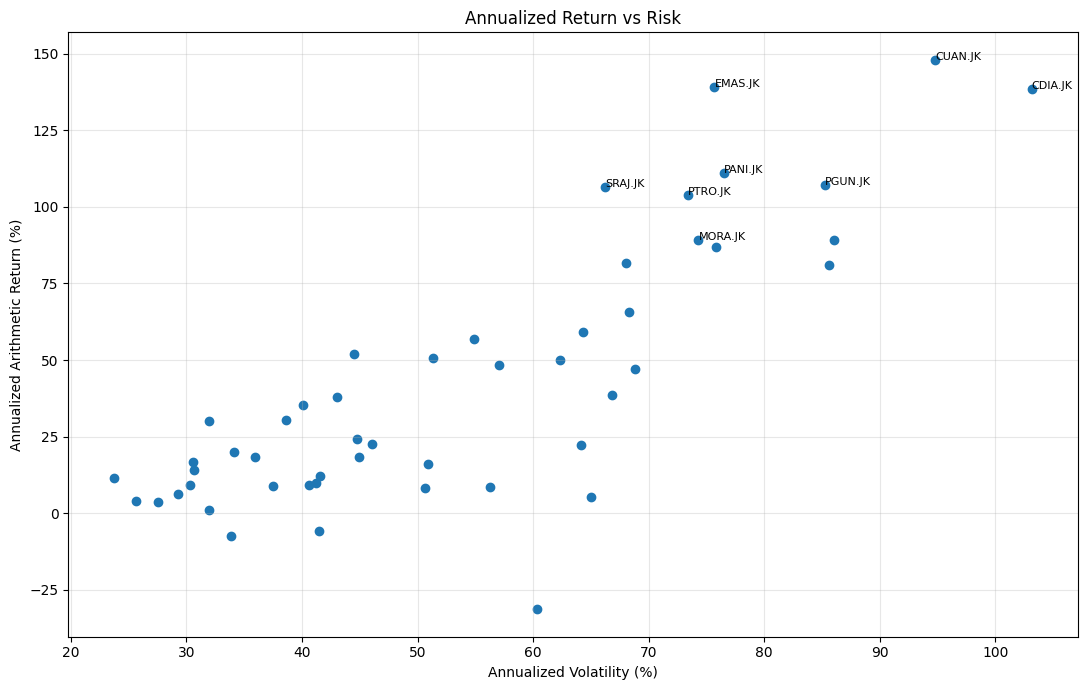

In [39]:
# Return vs Risk
plot_data = summary.dropna(
    subset=["annualized_return", "annualized_volatility"]
)

plt.figure(figsize=(11, 7))
plt.scatter(
    plot_data["annualized_volatility"] * 100,
    plot_data["annualized_return"] * 100
)

for ticker in plot_data.nlargest(8, "annualized_return").index:
    plt.annotate(
        ticker,
        (
            plot_data.loc[ticker, "annualized_volatility"] * 100,
            plot_data.loc[ticker, "annualized_return"] * 100
        ),
        fontsize=8
    )

plt.title("Annualized Return vs Risk")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Arithmetic Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- CUAN.JK memiliki annualized return tertinggi di antara saham yang ditampilkan pada tabel, tetapi volatilitasnya juga sangat tinggi.
- EMAS.JK menunjukkan return tinggi dengan volatilitas lebih rendah daripada CUAN.JK dan CDIA.JK dalam hasil historis ini.
- CDIA.JK memiliki volatilitas tertinggi pada sampel tersebut.
- Saham dengan return lebih rendah tidak selalu memiliki risiko yang rendah, sehingga kedua dimensi perlu diperiksa bersamaan.  

Grafik ini merupakan gambaran historis, bukan jaminan bahwa saham dengan return historis tertinggi akan memberikan return tertinggi pada masa depan.

### Distribusi Daily Returns
Histogram digunakan untuk melihat distribusi return harian seluruh saham. Distribusi ini membantu mengidentifikasi konsentrasi return di sekitar nol, kemencengan distribusi, serta keberadaan return ekstrem.

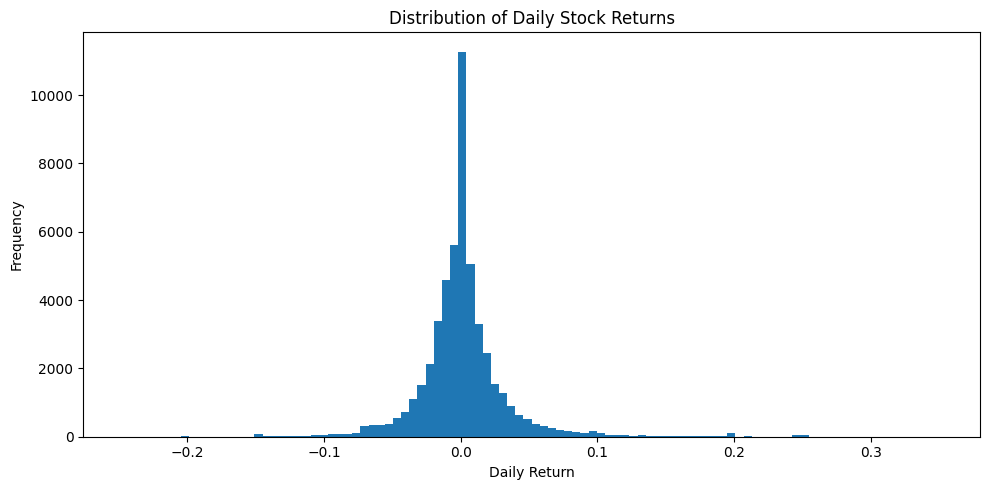

In [40]:
# Distribusi return harian
daily_returns.stack().dropna().plot(
    kind="hist", bins=100, figsize=(10, 5)
)
plt.title("Distribution of Daily Stock Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Grafik histogram yang kamu berikan menunjukkan:
- Sebagian besar return harian terkonsentrasi di sekitar nol.
- Terdapat ekor distribusi di sisi negatif dan positif.
- Sejumlah kecil return berada jauh dari pusat distribusi, termasuk return positif di atas 20% dan return negatif di bawah -20%.

---

Distribusi return menunjukkan bahwa pergerakan harian saham tidak selalu kecil. Return ekstrem dapat memengaruhi mean, volatilitas, korelasi, dan estimasi risiko portofolio.

Karena itu, observasi ekstrem sebaiknya diperiksa berdasarkan data harga dan corporate action. Jangan langsung menghapusnya hanya karena nilainya besar, sebab pergerakan tersebut mungkin benar-benar terjadi.

### Normalized Stock Price Trends
Harga saham memiliki skala nominal yang berbeda-beda. Untuk membandingkan perkembangan harga, setiap saham dinormalisasi menggunakan harga pada observasi pertamanya sebagai nilai indeks 100. Dengan cara ini, grafik menunjukkan perubahan relatif harga dari titik awal observasi masing-masing saham, bukan perbedaan harga nominal.

In [41]:
# Analisis tren harga saham
# Karena harga nominal saham berbeda", kita normalisasi harga awal setiap saham menjadi 100 agar pergerakannya dapat dibandingkan.

# Normalisasi harga menjadi indeks 100
normalized_prices = price_table.divide(
    price_table.apply(
        lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
    ),
    axis=1
) * 100

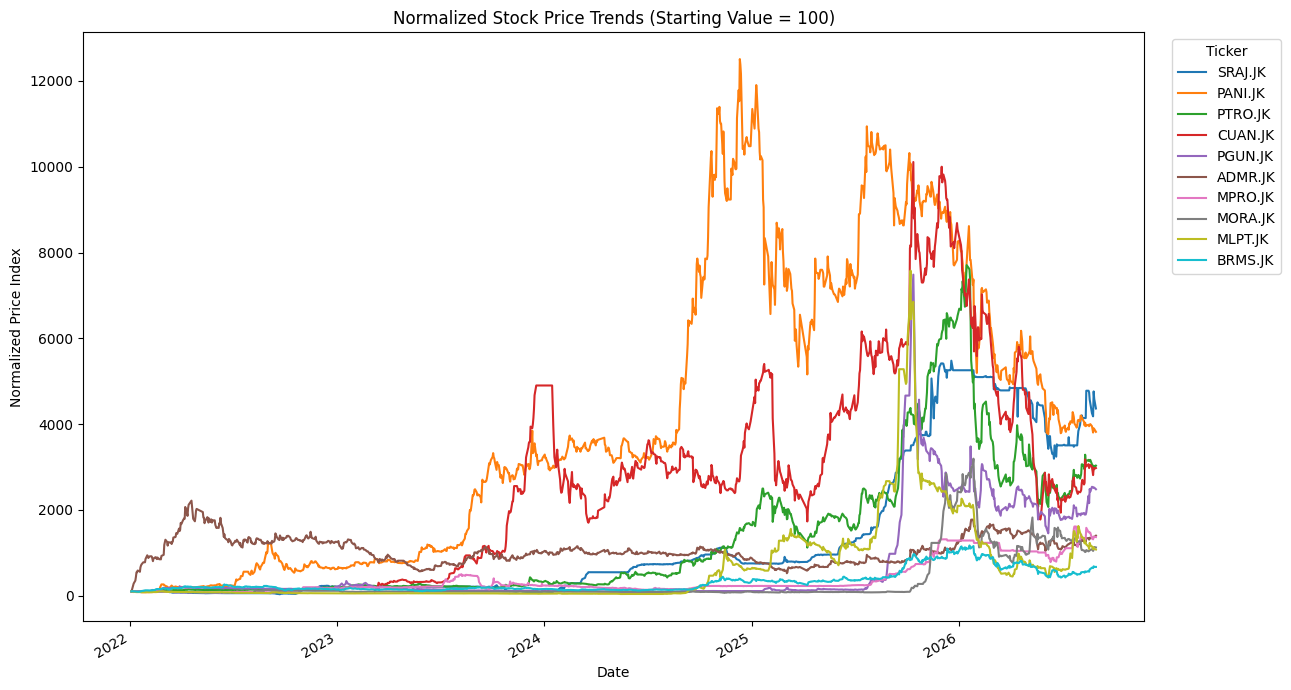

In [42]:
# Tampilkan 10 saham dengan total return tertinggi
top_tickers = summary.nlargest(10, "total_return").index

normalized_prices[top_tickers].plot(
    figsize=(13, 7)
)

plt.title("Normalized Stock Price Trends (Starting Value = 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Price Index")
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Diperlihatkan bahwa sejumlah saham mengalami kenaikan indeks harga yang sangat besar selama periode historis, sementara saham lainnya bergerak lebih terbatas atau mengalami penurunan.

Beberapa pola yang terlihat:
- PANI.JK mengalami lonjakan indeks yang sangat tinggi pada periode tertentu.
- CUAN.JK dan PTRO.JK menunjukkan kenaikan tajam pada sebagian periode, diikuti perubahan harga yang besar.
- SRAJ.JK juga memperlihatkan kenaikan yang besar dibandingkan titik awalnya.
- Saham-saham lain memiliki skala perubahan yang lebih kecil pada grafik tersebut.

---

Performa harga sangat bervariasi antar-saham dan antar-periode. Normalisasi membuat perbandingan pertumbuhan relatif lebih mudah, tetapi tidak menghilangkan perbedaan panjang periode historis.

Saham yang baru tersedia pada 2025, misalnya EMAS.JK, tidak memiliki periode observasi yang sama dengan saham yang sudah tersedia sejak 2022. Oleh sebab itu, perbandingan indeks harga perlu dibaca bersama informasi tanggal awal observasi.

### Correlation Matrix of Stock Daily Returns
Correlation analysis digunakan untuk mengukur hubungan linear antara return harian dua saham.

Koefisien korelasi Pearson berada pada rentang -1 sampai +1:
- Mendekati +1: return kedua saham cenderung bergerak searah.
- Mendekati 0: hubungan linear relatif lemah.
- Mendekati -1: return kedua saham cenderung bergerak berlawanan arah.

Informasi korelasi penting dalam portfolio optimization karena saham yang memiliki korelasi lebih rendah berpotensi membantu diversifikasi risiko.

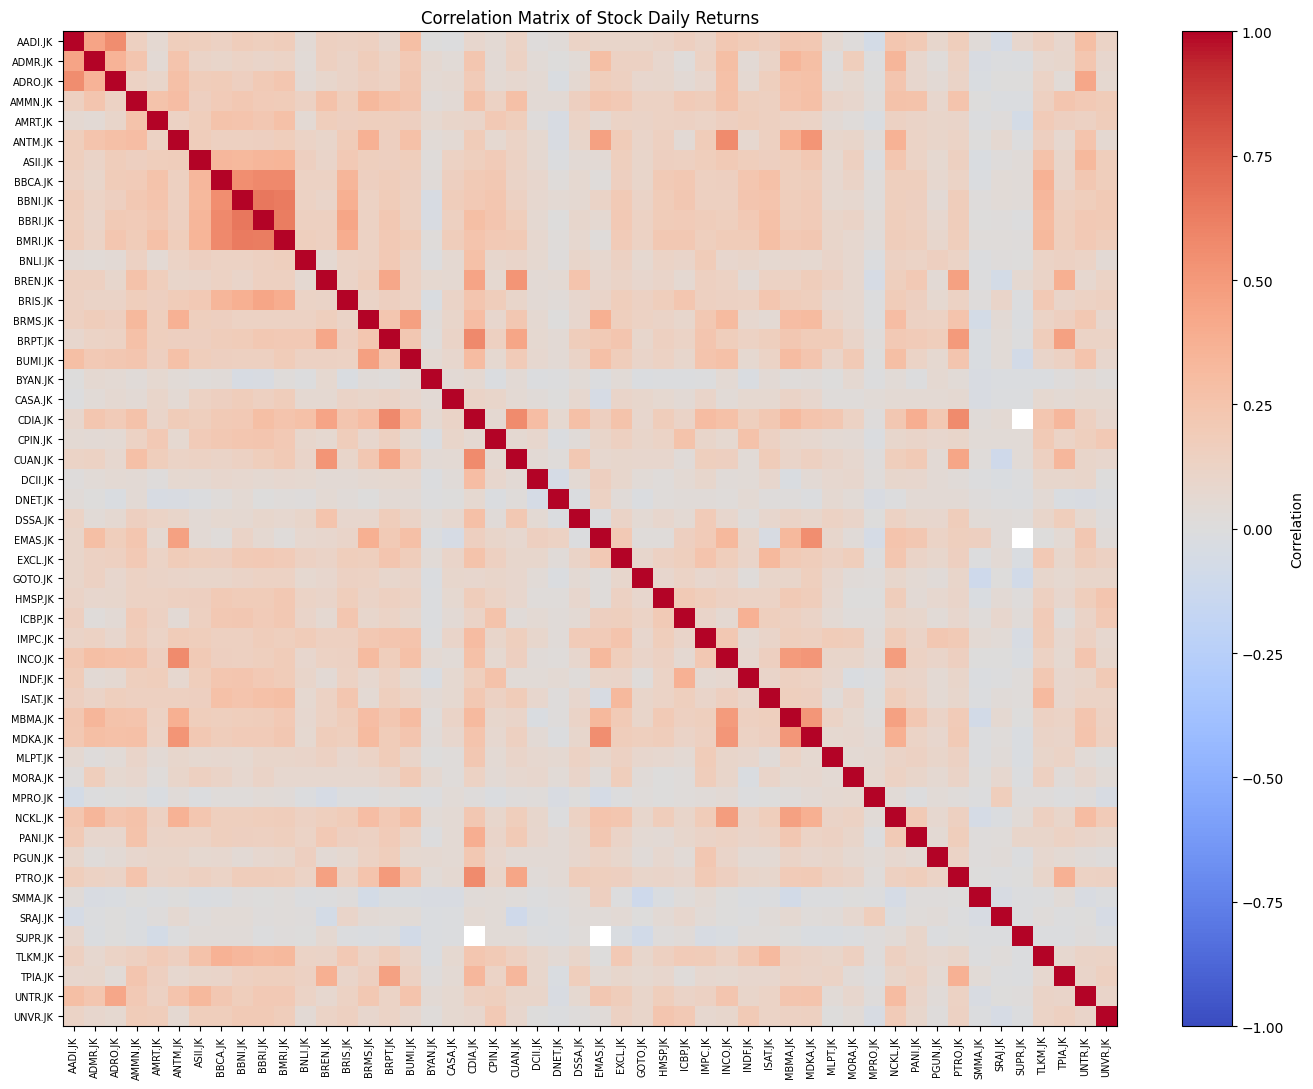

In [43]:
# Correlation matrix
correlation = daily_returns.corr(min_periods=60)

plt.figure(figsize=(14, 11))
plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90,
    fontsize=7
)
plt.yticks(
    range(len(correlation.index)),
    correlation.index,
    fontsize=7
)

plt.title("Correlation Matrix of Stock Daily Returns")
plt.tight_layout()
plt.show()

In [44]:
# Cari pasangan saham yang berkorelasi tinggi/rendah
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

pairs = upper_triangle.stack().sort_values()

print("10 pasangan dengan korelasi terendah:")
print(pairs.head(10).round(3))

print("\n10 pasangan dengan korelasi tertinggi:")
print(pairs.tail(10).sort_values(ascending=False).round(3))

correlation.to_csv("correlation_matrix.csv")

10 pasangan dengan korelasi terendah:
ticker   ticker 
GOTO.JK  SMMA.JK   -0.102
CUAN.JK  SRAJ.JK   -0.096
GOTO.JK  SUPR.JK   -0.082
BUMI.JK  SUPR.JK   -0.075
MBMA.JK  SMMA.JK   -0.072
BRMS.JK  SMMA.JK   -0.069
AADI.JK  MPRO.JK   -0.068
BREN.JK  SRAJ.JK   -0.068
AMRT.JK  SUPR.JK   -0.063
DCII.JK  DNET.JK   -0.060
dtype: float64

10 pasangan dengan korelasi tertinggi:
ticker   ticker 
BBNI.JK  BBRI.JK    0.653
         BMRI.JK    0.640
BBRI.JK  BMRI.JK    0.625
BRPT.JK  CDIA.JK    0.574
BBCA.JK  BBRI.JK    0.573
         BMRI.JK    0.573
CDIA.JK  PTRO.JK    0.566
ANTM.JK  INCO.JK    0.565
CDIA.JK  CUAN.JK    0.565
AADI.JK  ADRO.JK    0.555
dtype: float64


- BBNI.JK dan BBRI.JK memiliki korelasi tertinggi dalam daftar, yaitu 0,653. BBNI.JK dan BMRI.JK juga menunjukkan korelasi positif sebesar 0,640.

Pasangan saham perbankan tersebut cenderung bergerak searah dalam data historis. Memegang beberapa saham dengan korelasi tinggi tidak selalu memberikan diversifikasi sebesar memegang saham dengan pola return yang berbeda.

- Pasangan dengan korelasi terendah memiliki korelasi negatif yang relatif lemah. Artinya, hubungan pergerakan return yang berlawanan tidak terlalu kuat pada sampel ini.

Korelasi rendah dapat membantu diversifikasi, tetapi bukan satu-satunya dasar pemilihan saham. Estimasi korelasi juga dapat terpengaruh oleh saham dengan harga stagnan, volume rendah, atau jumlah observasi yang terbatas.

### Trading Volume Analysis
Trading volume menunjukkan jumlah saham yang diperdagangkan pada suatu periode. Rata-rata volume harian digunakan sebagai indikator awal aktivitas perdagangan, sedangkan median volume membantu melihat nilai tipikal yang tidak terlalu dipengaruhi lonjakan volume.

Catatan: volume diukur dalam jumlah lembar saham, bukan nilai transaksi dalam rupiah. Karena itu, volume besar tidak otomatis berarti nilai transaksi terbesar.

10 saham berdasarkan rata-rata volume harian:
         average_daily_volume  median_daily_volume   total_volume  \
ticker                                                              
GOTO.JK          3.349783e+09         2.412801e+09  3500522856200   
BUMI.JK          2.139241e+09         9.694872e+08  2378835506600   
BRMS.JK          5.100020e+08         3.504448e+08   567122200600   
CUAN.JK          2.157605e+08         1.171545e+08   176923607200   
BBRI.JK          2.032233e+08         1.731800e+08   225984283100   
CDIA.JK          1.695932e+08         1.067622e+08    46638125000   
MBMA.JK          1.580946e+08         8.964915e+07   125527136800   
BRPT.JK          1.330562e+08         8.845045e+07   147958467570   
BMRI.JK          1.305077e+08         1.074692e+08   145124532600   
TLKM.JK          1.142034e+08         9.540070e+07   126994178100   

         trading_days  
ticker                 
GOTO.JK          1045  
BUMI.JK          1112  
BRMS.JK          1112  
CUAN.

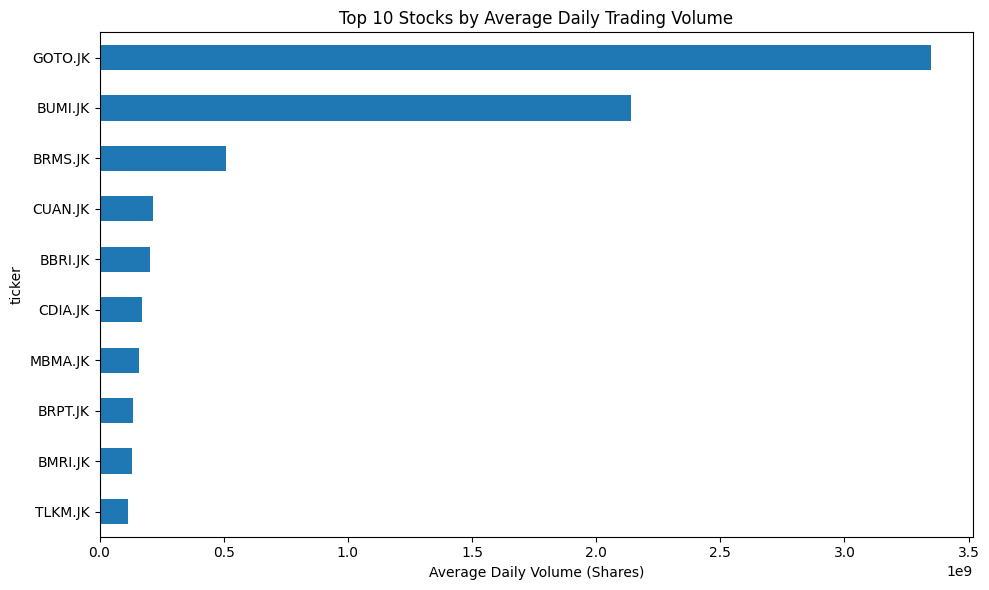

In [45]:
# Volume perdagangan per saham
volume_summary = prices.groupby("ticker").agg(
    average_daily_volume=("volume", "mean"),
    median_daily_volume=("volume", "median"),
    total_volume=("volume", "sum"),
    trading_days=("volume", "count")
).sort_values("average_daily_volume", ascending=False)

print("10 saham berdasarkan rata-rata volume harian:")
print(volume_summary.head(10).round(2))

volume_summary.head(10)["average_daily_volume"].sort_values().plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Top 10 Stocks by Average Daily Trading Volume")
plt.xlabel("Average Daily Volume (Shares)")
plt.tight_layout()
plt.show()

volume_summary.to_csv("volume_summary.csv")

Grafik menunjukkan bahwa GOTO.JK dan BUMI.JK memiliki rata-rata volume perdagangan harian yang jauh lebih besar daripada saham lain dalam daftar. BRMS.JK berada di urutan berikutnya, sedangkan saham-saham lainnya memiliki rata-rata volume yang relatif lebih kecil.

Sehingga, GOTO.JK dan BUMI.JK memiliki aktivitas perdagangan yang tinggi berdasarkan jumlah lembar saham. Namun, penilaian likuiditas sebaiknya juga mempertimbangkan nilai transaksi, bid–ask spread, kedalaman pasar, dan konsistensi volume.

Untuk tahap prescriptive analytics, volume historis dapat menjadi salah satu bahan evaluasi kelayakan perdagangan. Namun, rata-rata volume saja belum cukup untuk menentukan batas investasi yang realistis.

In [46]:
# RINGKASAN TEMUAN DESCRIPTIVE ANALYTICS

# 1. Return tertinggi dan terendah
print("=== RETURN TERTINGGI ===")
print(
    summary.nlargest(5, "annualized_return")[
        ["annualized_return", "annualized_volatility",
         "CAGR", "max_drawdown"]
    ].round(4)
)

print("\n=== TOTAL RETURN TERENDAH ===")
print(
    summary.nsmallest(5, "total_return")[
        ["total_return", "annualized_volatility",
         "CAGR", "max_drawdown"]
    ].round(4)
)

# 2. Volatilitas tertinggi
print("\n=== VOLATILITAS TERTINGGI ===")
print(
    summary.nlargest(5, "annualized_volatility")[
        ["annualized_return", "annualized_volatility",
         "max_drawdown"]
    ].round(4)
)

# 3. Drawdown terdalam
print("\n=== MAX DRAWDOWN TERDALAM ===")
print(
    summary.nsmallest(5, "max_drawdown")[
        ["total_return", "annualized_volatility",
         "max_drawdown"]
    ].round(4)
)

# 4. Pasangan saham dengan korelasi tertinggi/terendah
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

correlation_pairs = upper_triangle.stack().sort_values()

print("\n=== 10 PASANGAN KORELASI TERTINGGI ===")
print(correlation_pairs.tail(10).sort_values(ascending=False).round(3))

print("\n=== 10 PASANGAN KORELASI TERENDAH ===")
print(correlation_pairs.head(10).round(3))

# 5. Saham dengan aktivitas perdagangan terendah
print("\n=== AKTIVITAS PERDAGANGAN TERENDAH ===")
print(
    volume_summary.sort_values("average_daily_volume").head(10).round(2)
)

=== RETURN TERTINGGI ===
         annualized_return  annualized_volatility    CAGR  max_drawdown
ticker                                                                 
CUAN.JK             1.4796                 0.9478  1.6490       -0.8245
EMAS.JK             1.3924                 0.7569  1.8505       -0.4278
CDIA.JK             1.3852                 1.0316  1.3188       -0.7567
PANI.JK             1.1087                 0.7653  1.1862       -0.6988
PGUN.JK             1.0710                 0.8528  0.9927       -0.8059

=== TOTAL RETURN TERENDAH ===
         total_return  annualized_volatility    CAGR  max_drawdown
ticker                                                            
GOTO.JK       -0.8691                 0.6036 -0.3708       -0.8762
UNVR.JK       -0.4680                 0.4149 -0.1267       -0.7930
CPIN.JK       -0.4396                 0.3387 -0.1169       -0.4924
MBMA.JK       -0.3785                 0.6504 -0.1316       -0.7398
MDKA.JK       -0.2686                 

Hasil ini menunjukkan bahwa return tinggi dapat disertai risiko yang sangat besar. Contohnya, CUAN.JK memiliki annualized return yang tinggi, tetapi maximum drawdown-nya mencapai -82,45%. MLPT.JK bahkan memiliki maximum drawdown sebesar -94,44% pada hasil yang diberikan.

GOTO.JK menunjukkan total return negatif yang besar dan maximum drawdown -87,62%. Di sisi lain, EMAS.JK memiliki annualized return tinggi dengan maximum drawdown lebih rendah dibandingkan beberapa saham lain pada tabel tersebut. Namun, EMAS.JK memiliki periode observasi yang lebih pendek sehingga perbandingan langsung harus dilakukan dengan hati-hati.

**Kesimpulan analisis ini:** pemilihan saham untuk portofolio tidak sebaiknya hanya berdasarkan return historis. Risiko, drawdown, likuiditas, korelasi, dan periode observasi perlu dinilai secara bersamaan.

### Quality Control
Quality control dilakukan untuk mengidentifikasi potensi masalah kualitas data, seperti volume perdagangan nol dan harga yang tidak berubah, sebelum data digunakan dalam analisis dan optimasi portofolio.

In [47]:
# QUALITY CONTROL REPORT
quality_prices = prices.sort_values(
    ["ticker", "date"]
).copy()

quality_prices["previous_price"] = (
    quality_prices.groupby("ticker")["adjusted_close"].shift(1)
)

quality_prices["price_unchanged"] = (
    quality_prices["adjusted_close"].eq(
        quality_prices["previous_price"]
    )
)

quality_report = (
    quality_prices.groupby("ticker")
    .agg(
        total_observations=("adjusted_close", "count"),
        zero_volume_days=("volume", lambda x: x.eq(0).sum()),
        unchanged_price_days=("price_unchanged", "sum"),
        unique_prices=("adjusted_close", "nunique")
    )
)

quality_report["zero_volume_pct"] = (
    quality_report["zero_volume_days"]
    / quality_report["total_observations"] * 100
)

quality_report["unchanged_price_pct"] = (
    quality_report["unchanged_price_days"]
    / (quality_report["total_observations"] - 1).clip(lower=1)
    * 100
)

# Penanda untuk pemeriksaan lebih lanjut, bukan keputusan menghapus
quality_report["review_flag"] = (
    (quality_report["zero_volume_pct"] >= 10)
    | (quality_report["unchanged_price_pct"] >= 30)
)

quality_report = quality_report.sort_values(
    ["review_flag", "zero_volume_pct"],
    ascending=[False, False]
)

print(quality_report.round(2).to_string())

quality_report.to_csv("data_quality_report.csv")

         total_observations  zero_volume_days  unchanged_price_days  unique_prices  zero_volume_pct  unchanged_price_pct  review_flag
ticker                                                                                                                               
SUPR.JK                1112               970                  1022             85            87.23                91.99         True
SMMA.JK                1112               309                   737            187            27.79                66.34         True
DSSA.JK                1112               301                   432            565            27.07                38.88         True
MPRO.JK                1112               189                   414            343            17.00                37.26         True
DCII.JK                1112               145                   387            519            13.04                34.83         True
PGUN.JK                1112               137                 

Hasil pemeriksaan menunjukkan bahwa SUPR.JK memiliki indikasi masalah paling signifikan, dengan 87,23% hari bervolume nol dan 91,99% harga tidak berubah. Saham seperti SMMA.JK, DSSA.JK, dan MPRO.JK juga memerlukan pemeriksaan lebih lanjut.

Saham yang ditandai oleh review_flag perlu diperiksa sebelum digunakan dalam optimasi portofolio. Namun, penanda ini bukan berarti data pasti salah atau saham harus dihapus, karena kondisi tersebut dapat mencerminkan aktivitas perdagangan yang rendah atau keterbatasan data historis.

# Predictive Analytics  
Bagian Predictive Analytics menguji apakah return harian saham Indonesia dapat diperkirakan menggunakan informasi return masa lalu. Unit prediksi yang digunakan adalah return pada observasi berikutnya, bukan harga saham secara langsung.

Alur analisis:
1. Menetapkan periode pelatihan (training), validasi (validation), dan pengujian akhir (final test).
2. Membentuk fitur dari return historis dan target return berikutnya.
3. Membandingkan dua model pembanding sederhana (baseline) dengan dua model machine learning.
4. Memilih model berdasarkan kinerja pada data validasi tahun 2025.
5. Menguji model terpilih pada periode Januari–Agustus 2026 yang tidak digunakan untuk memilih model.
6. Mengekspor hasil dan menjalankan pemeriksaan konsistensi.

Notes: return saham harian umumnya berisik dan sulit diprediksi. Karena itu, hasil yang menunjukkan model machine learning tidak mengungguli baseline tetap merupakan temuan yang valid. Tujuannya bukan memaksakan hasil prediksi yang bagus, melainkan mengukur apakah model benar-benar memberi nilai tambah.

**Define Data Range**

Kode berikut menetapkan periode berdasarkan tanggal target, tanggal ketika return yang diprediksi benar-benar terjadi. Pemisahan waktu dibuat kronologis agar model tidak dilatih menggunakan informasi dari masa depan.

**Periode**
* Training Awal - 1 Jan 2022-31 Des 2024: Melatih model awal
* Validation - 1 Jan-31 Des 2025: Membandingkan dan memilih model
* Final Training - 1 Jan 2022-31 Des 2025: Melatih ulang model terpilih sebelum pengujian akhir
* Final Test - 1 Jan-31 Agustus 2026: Mengukur performa pada periode yang tidak dipakai memilih model

MIN_HISTORY, MIN_TRAIN_ROWS, dan MIN_VALIDATION_ROWS merupakan batas minimum jumlah observasi. Batas ini membantu menghindari evaluasi pada saham dengan riwayat terlalu pendek. feature_cols menetapkan lima fitur yang akan digunakan model.

Disini, urutan waktu penting dikarenakan pembagian acak (random split) berisiko mencampurkan masa depan ke data pelatihan. Untuk deret waktu finansial, pelatihan pada periode lebih lama lalu pengujian pada periode lebih baru lebih sesuai dengan skenario penggunaan nyata.

In [48]:
# Training diambil dari target dates hingga 2024
# validation menggunakan next-day returns selama 2025 
# Untuk hasil akhir forecast mengambil next-day returns selama 2026 

MIN_HISTORY = 300
MIN_TRAIN_ROWS = 200
MIN_VALIDATION_ROWS = 20

train_start = pd.Timestamp("2022-01-01")
train_end = pd.Timestamp("2024-12-31")

validation_start = pd.Timestamp("2025-01-01")
validation_end = pd.Timestamp("2025-12-31")

final_train_start = pd.Timestamp("2022-01-01")
final_train_end = pd.Timestamp("2025-12-31")

final_test_start = pd.Timestamp("2026-01-01")
final_test_end = pd.Timestamp("2026-08-31")

feature_cols = ["lag_1", "lag_2", "lag_5", "mean_5", "vol_5"]

**Cara membaca konfigurasi periode**
* Training awal sampai 2024: model belajar dari data historis yang tersedia sebelum tahun validasi.
* Validasi sepanjang 2025: prediksi dibandingkan dengan return aktual pada 2025. Hasil periode ini digunakan untuk memilih satu jenis model.
* Final training sampai 2025: setelah jenis model dipilih, model machine learning dilatih ulang dengan data sampai akhir 2025. Untuk baseline, prediksi tetap dihitung sesuai definisi baseline.
* Final test Januari-Agustus 2026: hasilnya merupakan evaluasi akhir pada periode yang lebih baru.

Periode final test tidak seharusnya digunakan untuk mengganti pilihan model atau mengubah parameter berdasarkan hasil yang terlihat. Jika model dipilih ulang setelah melihat hasil 2026, maka 2026 tidak lagi menjadi pengujian independen.

**Create Features and Targets**  
Setiap saham diproses sebagai deret waktu tersendiri. Fitur dihitung hanya dari return yang tersedia pada tanggal fitur, sedangkan target adalah return pada observasi berikutnya.

Definisi fitur:
* lag_1: Return pada tanggal fitur saat ini, yaitu return terakhir yang telah teramati
* lag_2	Return satu observasi sebelum lag_1
* lag_5: Return empat baris sebelum tanggal fitur; dihitung sebagai observasi kelima jika return saat ini dihitung sebagai lag pertama terhadap target berikutnya
* mean_5: Rata-rata return pada lima observasi terakhir, termasuk tanggal fitur saat ini
* vol_5: Simpangan baku return pada lima observasi terakhir; digunakan sebagai ukuran volatilitas jangka pendek
* target: Return pada observasi berikutnya
* target_date: Tanggal ketika target return terjadi

target_date diperlukan agar baris dipisahkan ke training, validation, dan final test berdasarkan tanggal return aktual yang diprediksi—bukan sekadar tanggal fitur. MIN_HISTORY = 300 menyaring saham yang memiliki kurang dari 300 return valid. dropna membuang baris yang belum memiliki semua fitur dan target. Laporan kelayakan menunjukkan jumlah observasi yang tersedia per saham dan apakah saham memenuhi syarat untuk evaluasi.

Penting: lag_5 = s.shift(4) memang menggunakan empat langkah mundur dari baris fitur saat ini. Ini konsisten jika return pada baris saat ini dianggap sebagai fitur lag pertama terhadap target pada baris berikutnya. Jika ingin menggunakan konvensi alternatif (e.g., lag_5), maka definisi fitur dan penamaannya harus diubah secara konsisten.

## membuat fitur2 dan target kolom

In [ ]:
stock_data = {}
eligibility_records = []

for ticker in daily_returns.columns:
    # Urutkan data berdasarkan urutan waktu dengan tetap mempertahankan observasi yang hilang.
    s = daily_returns[ticker].sort_index().astype(float)

    # memastikan tanggalnya berurutan dan tidak ada yang ter-duplikasi
    if not s.index.is_unique:
        print(f"Warning: {ticker} has duplicate dates.")
        s = s.loc[~s.index.duplicated(keep="last")]

    valid_count = int(s.notna().sum())

    if valid_count < MIN_HISTORY:
        eligibility_records.append({
            "ticker": ticker,
            "valid_returns": valid_count,
            "train_rows": 0,
            "validation_rows": 0,
            "final_test_rows": 0,
            "status": "Skipped: insufficient history"
        })
        print(
            f"Skipping {ticker}: only {valid_count} "
            "valid return observations."
        )
        continue

    data = pd.DataFrame(index=s.index)

    # Fitur yang tersedia pada tanggal observasi saat ini
    data["lag_1"] = s
    data["lag_2"] = s.shift(1)
    data["lag_5"] = s.shift(4)

    data["mean_5"] = s.rolling(
        window=5,
        min_periods=5
    ).mean()

    data["vol_5"] = s.rolling(
        window=5,
        min_periods=5
    ).std()

    # Target: kembali ke tanggap observasi selanjutnya
    data["target"] = s.shift(-1)

    # Tanggal aktual yang terkait dengan nilai target.
    data["target_date"] = pd.Series(
        s.index,
        index=s.index
    ).shift(-1)

    # Hapus baris yang fitur atau targetnya tidak lengkap
    data = data.dropna(
        subset=feature_cols + ["target", "target_date"]
    ).copy()

    data["target_date"] = pd.to_datetime(data["target_date"])

    # Pisah dataset berdasarkan tanggal target
    train = data[
        data["target_date"].between(train_start, train_end)
    ]

    valid = data[
        data["target_date"].between(
            validation_start, validation_end
        )
    ]

    final_test = data[
        data["target_date"].between(
            final_test_start, final_test_end
        )
    ]

    # Menentukan kelayakan awal data untuk periode validasi
    if len(train) < MIN_TRAIN_ROWS:
        status = "Skipped: insufficient training rows"
    elif len(valid) < MIN_VALIDATION_ROWS:
        status = "Skipped: insufficient validation rows"
    else:
        status = "Eligible"

    stock_data[ticker] = data

    eligibility_records.append({
        "ticker": ticker,
        "valid_returns": valid_count,
        "usable_rows": len(data),
        "train_rows": len(train),
        "validation_rows": len(valid),
        "final_train_rows": int(
            (data["target_date"] <= final_train_end).sum()
        ),
        "final_test_rows": len(final_test),
        "status": status
    })

# Laporan kelayakan data dan cakupan data
eligibility_report = pd.DataFrame(eligibility_records)

print("Stocks prepared:", len(stock_data))
display(eligibility_report)

Skipping CDIA.JK: only 274 valid return observations.
Skipping EMAS.JK: only 222 valid return observations.
Stocks prepared: 48


,ticker,valid_returns,usable_rows,train_rows,validation_rows,final_train_rows,final_test_rows,status
0,AADI.JK,405,400.0,10,236,246.0,154,Skipped: insufficient training rows
1,ADMR.JK,1111,1106.0,716,236,952.0,154,Eligible
2,ADRO.JK,1111,1106.0,716,236,952.0,154,Eligible
3,AMMN.JK,747,742.0,352,236,588.0,154,Eligible
4,AMRT.JK,1111,1106.0,716,236,952.0,154,Eligible
5,ANTM.JK,1111,1106.0,716,236,952.0,154,Eligible
6,ASII.JK,1111,1106.0,716,236,952.0,154,Eligible
7,BBCA.JK,1111,1106.0,716,236,952.0,154,Eligible
8,BBNI.JK,1111,1106.0,716,236,952.0,154,Eligible
9,BBRI.JK,1111,1106.0,716,236,952.0,154,Eligible


Loop ini mengerjakan satu ticker pada satu waktu, bukan menyambungkan return berbagai saham menjadi satu deret waktu. Ini penting karena return saham A tidak boleh menjadi lag untuk saham B.
* sort_index() memastikan observasi berurutan berdasarkan tanggal.
* Tanggal duplikat dibuang dengan mempertahankan baris terakhir.
* valid_count menghitung return yang tidak kosong.
* Fitur dan target dibuat untuk setiap saham.
* Baris tanpa fitur/target lengkap dihapus.
* Jumlah baris pada training, validation, dan final test dihitung untuk laporan kelayakan.

Saham berstatus Eligible pada laporan ini memenuhi batas minimum training dan validation yang ditetapkan. Status tersebut berarti saham layak untuk tahap perbandingan model, bukan berarti data saham tersebut pasti sempurna atau modelnya akan akurat.

**Train and Compare (4 Models)**  
Keempat pendekatan dievaluasi pada observasi target tahun 2025:
* Zero Return Baseline: selalu memprediksi return 0. Ini baseline sederhana yang mewakili asumsi tidak ada perubahan return.
* Historical Mean Baseline: selalu memprediksi rata-rata return saham tersebut pada data training.
* Linear Regression: mempelajari hubungan linear antara lima fitur historis dan return berikutnya.
* Random Forest: menggabungkan banyak pohon keputusan untuk mempelajari hubungan yang berpotensi nonlinier. Parameter seperti max_depth=5 dan min_samples_leaf=10 membatasi kompleksitas model.

Baseline diperlukan agar kita dapat menilai apakah model yang lebih kompleks benar-benar memberi peningkatan. Model machine learning tidak otomatis lebih baik hanya karena lebih canggih.

In [ ]:
validation_prediction_frames = []
training_records = []

for ticker, data in stock_data.items():
    train = data[
        data["target_date"].between(train_start, train_end)
    ]

    valid = data[
        data["target_date"].between(
            validation_start, validation_end
        )
    ]

    # Lewati stocks yang punya data tidak lengkap
    if (
        len(train) < MIN_TRAIN_ROWS
        or len(valid) < MIN_VALIDATION_ROWS
    ):
        print(
            f"Skipping {ticker}: "
            f"train={len(train)}, validation={len(valid)}"
        )
        continue

    X_train = train[feature_cols]
    y_train = train["target"]

    X_valid = valid[feature_cols]
    y_valid = valid["target"]

    # Model 1: Zero Return Baseline
    zero_pred = np.zeros(len(valid))

    # Model 2: Historical Mean Baseline
    mean_pred = np.full(len(valid), y_train.mean())

    # Model 3: Linear Regression
    linear_model = LinearRegression()

    start_time = time.perf_counter()
    linear_model.fit(X_train, y_train)
    linear_pred = linear_model.predict(X_valid)
    linear_time = time.perf_counter() - start_time

    # Model 4: Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=150,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()
    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_valid)
    rf_time = time.perf_counter() - start_time

    model_outputs = [
        ("Zero Return Baseline", zero_pred),
        ("Historical Mean Baseline", mean_pred),
        ("Linear Regression", linear_pred),
        ("Random Forest", rf_pred)
    ]

    for model_name, predicted in model_outputs:

        validation_prediction_frames.append(
            pd.DataFrame({
                "ticker": ticker,
                "date": valid["target_date"].to_numpy(),
                "actual_return": y_valid.to_numpy(),
                "predicted_return": predicted,
                "model": model_name
            })
        )

    training_records.extend([
        {
            "ticker": ticker,
            "model": "Linear Regression",
            "train_rows": len(train),
            "validation_rows": len(valid),
            "fit_predict_seconds": linear_time
        },
        {
            "ticker": ticker,
            "model": "Random Forest",
            "train_rows": len(train),
            "validation_rows": len(valid),
            "fit_predict_seconds": rf_time
        }
    ])

Skipping AADI.JK: train=10, validation=236


Untuk setiap ticker yang memenuhi jumlah minimum observasi:
* Data training dipilih berdasarkan target_date pada 2022-2024.
* Data validation dipilih berdasarkan target_date pada 2025.
* Keempat pendekatan menghasilkan prediksi untuk baris validation yang sama.
* Prediksi, return aktual, tanggal target, ticker, dan nama model disimpan agar bisa dibandingkan secara adil.
* Waktu fit/predict Linear Regression dan Random Forest dicatat sebagai informasi komputasi.
Dua baseline tidak memerlukan proses fitting seperti model machine learning. Karena itu, catatan waktu komputasi hanya disimpan untuk Linear Regression dan Random Forest.

Dengan pemisahan ini, model tidak melihat nilai target 2025 saat dilatih. Fitur validation tetap boleh memakai return historis sebelum tanggal targetnya, karena informasi historis tersebut secara realistis sudah tersedia ketika prediksi dibuat.

**Combine Predictions**  
Tahap ini menggabungkan hasil prediksi dari setiap ticker dan model menjadi satu DataFrame bernama validation_predictions. Jika tidak ada prediksi yang berhasil dibuat, kode menghentikan proses dengan pesan kesalahan agar analisis tidak berlanjut dengan tabel kosong.

Data validation_predictions berisi:
* ticker: kode saham
* date: tanggal target/return aktual
* actual_return: return aktual yang terjadi
* predicted_return: return yang diprediksi model
* model: nama pendekatan prediksi

Variabel predictions kemudian mengambil hanya prediksi Linear Regression untuk analisis per ticker dan ekspor predictions_2025.csv. Variabel training_report menyimpan jumlah baris dan waktu proses model machine learning.

In [ ]:
if not validation_prediction_frames:
    raise ValueError(
        "No validation predictions were generated. "
        "Check data availability and split requirements."
    )

validation_predictions = pd.concat(
    validation_prediction_frames,
    ignore_index=True
)

# Simpan prediksi Linear Regression untuk analisis lanjutan
predictions = validation_predictions[
    validation_predictions["model"] == "Linear Regression"
].copy()

training_report = pd.DataFrame(training_records)

print("Validation prediction rows:", len(validation_predictions))
print("Eligible tickers:", predictions["ticker"].nunique())

display(training_report.head())
display(validation_predictions.head())

Validation prediction rows: 44368
Eligible tickers: 47


,ticker,model,train_rows,validation_rows,fit_predict_seconds
0,ADMR.JK,Linear Regression,716,236,0.019517
1,ADMR.JK,Random Forest,716,236,0.350230
2,ADRO.JK,Linear Regression,716,236,0.002915
3,ADRO.JK,Random Forest,716,236,0.342660
4,AMMN.JK,Linear Regression,352,236,0.002934


,ticker,date,actual_return,predicted_return,model
0,ADMR.JK,2025-01-02,-0.029167,0.0,Zero Return Baseline
1,ADMR.JK,2025-01-03,-0.030043,0.0,Zero Return Baseline
2,ADMR.JK,2025-01-06,-0.022124,0.0,Zero Return Baseline
3,ADMR.JK,2025-01-07,-0.022624,0.0,Zero Return Baseline
4,ADMR.JK,2025-01-08,-0.027778,0.0,Zero Return Baseline


Jumlah baris total bergantung pada ticker yang memenuhi syarat, ketersediaan data, dan jumlah hari observasi yang lolos setelah fitur/target dibentuk. Karena itu, angka jumlah ticker dan baris harus dibaca dari output terbaru setelah notebook dijalankan ulang, bukan dianggap sebagai angka yang selalu tetap.

Setiap model seharusnya dinilai pada kumpulan target aktual yang sama. Dengan demikian, perbedaan metrik lebih mencerminkan perbedaan prediksi model daripada perbedaan periode pengujian.

Perlu dibedakan:
* validation_predictions: berisi prediksi dari keempat model;
* predictions: hanya berisi prediksi Linear Regression.

**Evaluation**  
Fungsi metrik menghitung beberapa ukuran yang saling melengkapi:
* MAE (Mean Absolute Error): rata-rata nilai absolut selisih prediksi dan return aktual. Semakin kecil, semakin baik.
* RMSE (Root Mean Squared Error): akar dari rata-rata kuadrat error. Kesalahan besar mendapat penalti lebih tinggi; semakin kecil, semakin baik.
* Directional Accuracy: proporsi observasi ketika tanda return aktual dan tanda prediksi sama.
* Actual Movement Rate: proporsi return aktual yang tidak sama dengan nol.
* Prediction Coverage: proporsi prediksi yang tidak sama dengan nol.
* Nonzero Directional Accuracy: akurasi arah hanya pada baris ketika return aktual dan prediksi sama-sama tidak nol.
* Number of Predictions: jumlah observasi valid yang digunakan untuk menghitung metrik.

Metrik ini tidak mengukur hal yang sama. MAE/RMSE mengukur kedekatan nilai prediksi, sedangkan metrik arah mengukur kesesuaian tanda. Model dapat memiliki error numerik lebih rendah tanpa mampu memprediksi arah pasar secara andal.

In [ ]:
def regression_metrics(group):
    actual = group["actual_return"].to_numpy(dtype=float)
    predicted = group["predicted_return"].to_numpy(dtype=float)

    # Hapus observasi invalid
    valid = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return pd.Series({
            "MAE": np.nan,
            "RMSE": np.nan,
            "Directional Accuracy": np.nan,
            "Actual Movement Rate": np.nan,
            "Prediction Coverage": np.nan,
            "Nonzero Directional Accuracy": np.nan,
            "Number of Predictions": 0
        })

    # Standard regression metrics
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Kesesuaian arah secara keseluruhan.
    # Prediksi nol dianggap sesuai jika return aktual juga nol.
    directional_accuracy = np.mean(
        np.sign(actual) == np.sign(predicted)
    )

    actual_moves = actual != 0
    predicted_moves = predicted != 0

    actual_movement_rate = actual_moves.mean()
    prediction_coverage = predicted_moves.mean()

    # Evaluasi arah ketika kedua nilainya selain 0 
    eligible = actual_moves & predicted_moves

    if eligible.any():
        nonzero_directional_accuracy = np.mean(
            np.sign(actual[eligible])
            == np.sign(predicted[eligible])
        )
    else:
        nonzero_directional_accuracy = np.nan

    return pd.Series({
        "MAE": mae,
        "RMSE": rmse,
        "Directional Accuracy": directional_accuracy,
        "Actual Movement Rate": actual_movement_rate,
        "Prediction Coverage": prediction_coverage,
        "Nonzero Directional Accuracy": nonzero_directional_accuracy,
        "Number of Predictions": len(actual)
    })

model_comparison = (
    validation_predictions
    .groupby("model")[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .sort_values("MAE")
)

print("Model Comparison, 2025 Validation Period")
display(model_comparison.round(6))

linear_metrics = (
    predictions
    .groupby("ticker")[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .sort_values("MAE")
)

print("Linear Regression Performance by Stock")
display(linear_metrics.round(6))

ticker_model_comparison = (
    validation_predictions
    .groupby(["ticker", "model"])[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .reset_index()
)

print("Model Performance by Stock")
display(
    ticker_model_comparison.sort_values(
        ["ticker", "MAE"]
    ).round(6)
)

# Tabel komparasi MAE
ticker_mae_table = ticker_model_comparison.pivot(
    index="ticker",
    columns="model",
    values="MAE"
)

print("MAE Comparison by Stock")
display(ticker_mae_table.round(6))

# Rata-rata metrik setiap saham dengan bobot yang sama
equal_weight_metrics = (
    ticker_model_comparison
    .groupby("model")[
        ["MAE", "RMSE", "Directional Accuracy"]
    ]
    .mean()
    .sort_values("MAE")
)

print("Equal-Weighted Average Across Stocks 2025")
display(equal_weight_metrics.round(6))

# Pilih model yang punya bobot MAE terendah
best_model_name = equal_weight_metrics["MAE"].idxmin()

print("Selected final model:", best_model_name)
print("Selection criterion: Lowest equal-weighted MAE")

Model Comparison, 2025 Validation Period


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
model,,,,,,,
Zero Return Baseline,0.022704,0.038404,0.143527,0.856473,0.0,NaN,11092.0
Historical Mean Baseline,0.022977,0.038370,0.427786,0.856473,1.0,0.499474,11092.0
Random Forest,0.023425,0.038731,0.432023,0.856473,1.0,0.504421,11092.0
Linear Regression,0.023435,0.038892,0.430941,0.856473,1.0,0.503158,11092.0


Linear Regression Performance by Stock


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
ticker,,,,,,,
SUPR.JK,0.000078,0.000087,0.000000,0.004237,1.0,0.000000,236.0
BYAN.JK,0.008133,0.019134,0.334746,0.813559,1.0,0.411458,236.0
DNET.JK,0.012404,0.017955,0.351695,0.868644,1.0,0.404878,236.0
ASII.JK,0.013446,0.018668,0.525424,0.902542,1.0,0.582160,236.0
BBCA.JK,0.013501,0.018384,0.504237,0.919492,1.0,0.548387,236.0
SMMA.JK,0.013530,0.030322,0.313559,0.546610,1.0,0.573643,236.0
ICBP.JK,0.014004,0.018618,0.504237,0.940678,1.0,0.536036,236.0
UNTR.JK,0.014220,0.021167,0.576271,0.957627,1.0,0.601770,236.0
INDF.JK,0.014354,0.018789,0.470339,0.894068,1.0,0.526066,236.0


Model Performance by Stock


...

MAE Comparison by Stock


model,Historical Mean Baseline,Linear Regression,Random Forest,Zero Return Baseline
ticker,,,,
ADMR.JK,0.025125,0.026373,0.025702,0.024784
ADRO.JK,0.018257,0.018402,0.018669,0.017953
AMMN.JK,0.028471,0.028696,0.028305,0.028107
AMRT.JK,0.021210,0.021645,0.022055,0.020994
ANTM.JK,0.024778,0.025272,0.025601,0.024773
ASII.JK,0.013620,0.013446,0.013491,0.013608
BBCA.JK,0.013480,0.013501,0.013784,0.013391
BBNI.JK,0.017166,0.017370,0.017188,0.017048
BBRI.JK,0.016565,0.017019,0.017143,0.016535


Equal-Weighted Average Across Stocks 2025


,MAE,RMSE,Directional Accuracy
model,,,
Zero Return Baseline,0.022704,0.035179,0.143527
Historical Mean Baseline,0.022977,0.035198,0.427786
Random Forest,0.023425,0.035566,0.432023
Linear Regression,0.023435,0.035600,0.430941


Selected final model: Zero Return Baseline
Selection criterion: Lowest equal-weighted MAE


Hasil menunjukkan bahwa **Zero Return Baseline memiliki MAE terendah sebesar 2.27%**, diikuti Historical Mean Baseline sebesar 2.29%. Sementara itu, Historical Mean Baseline memiliki RMSE agregat terendah sebesar 3.83%, sedikit lebih rendah dibandingkan Zero Return Baseline sebesar 3.84%. Perbedaan ini menunjukkan bahwa model terbaik berdasarkan MAE tidak selalu menjadi model terbaik berdasarkan RMSE.

Random Forest memperoleh Directional Accuracy tertinggi sebesar 43,20%, diikuti Linear Regression sebesar 43,09% dan Historical Mean Baseline sebesar 42,78%. Namun, ketika hanya observasi dengan prediksi dan return aktual nonnol yang diperhitungkan, Nonzero Directional Accuracy Random Forest adalah 50,44%, Linear Regression 50,32%, dan Historical Mean Baseline 49,95%. Nilai tersebut menunjukkan bahwa kemampuan prediksi arah model-model ini masih terbatas.

Zero Return Baseline memiliki Directional Accuracy sebesar 14,35% dan Prediction Coverage sebesar 0%. Karena model selalu memprediksi return nol, Directional Accuracy tersebut sama dengan proporsi return aktual yang nol, bukan ukuran kemampuan memprediksi arah kenaikan atau penurunan saham.

Kinerja model juga bervariasi antar-saham. Sebagai contoh, Linear Regression menghasilkan MAE sebesar 0,000078 pada SUPR.JK, jauh lebih rendah daripada sebagian besar saham lainnya. Hasil ini kemungkinan dipengaruhi oleh tingginya proporsi return nol pada saham tersebut, sehingga perlu ditafsirkan bersama karakteristik datanya.

Secara keseluruhan, Linear Regression dan Random Forest tidak menunjukkan peningkatan yang konsisten dibandingkan baseline sederhana dalam hal MAE dan RMSE. Berdasarkan kriteria pemilihan, Zero Return Baseline dipilih sebagai model terbaik. Namun, karena model tersebut tidak menghasilkan prediksi return nonnol, pemilihannya menunjukkan keunggulan dalam meminimalkan error menurut kriteria yang digunakan, bukan kemampuan memprediksi arah pasar.

**SUPR.JK's zero returns check**  
Setelah membandingkan model, bagian ini memeriksa SUPR.JK karena banyak return nol dapat memengaruhi MAE, RMSE, dan terutama metrik arah. Pemeriksaan ini tidak mengubah data atau menghapus saham secara otomatis; tujuannya adalah memahami konteks hasil evaluasi.


In [53]:
# Periksa return harian saham SUPR.JK
supr_returns = daily_returns["SUPR.JK"].dropna()

print("Observations:", len(supr_returns))
print("Zero returns (%):", (supr_returns == 0).mean() * 100)
print("Unique returns:", supr_returns.nunique())
print("Standard deviation:", supr_returns.std())

# Periksa harga penutupan yang telah disesuaikan (adjusted closing price) pada data asli
supr_prices = price_table["SUPR.JK"].dropna().sort_index()

print(
    "\nUnchanged consecutive prices (%):",
    supr_prices.pct_change().dropna().eq(0).mean() * 100
)

display(supr_prices.head(10))

Observations: 1111
Zero returns (%): 91.98919891989199
Unique returns: 87
Standard deviation: 0.024335607363297523

Unchanged consecutive prices (%): 91.98919891989199


date
2022-01-03    15600.0
2022-01-04    15600.0
2022-01-05    15600.0
2022-01-06    15600.0
2022-01-07    15600.0
2022-01-10    15600.0
2022-01-11    15800.0
2022-01-12    16025.0
2022-01-13    16000.0
2022-01-14    16000.0
Name: SUPR.JK, dtype: float64

Hasil pemeriksaan menunjukkan bahwa:
* SUPR.JK memiliki 1.111 observasi return valid. Sebanyak 91,99% return bernilai nol, terdapat 87 nilai return unik, dan standar deviasi return sebesar 2.43%. Persentase harga penutupan yang tidak berubah antarobservasi juga sebesar 91,99%.
* Harga penutupan tercatat sebesar Rp15.600 dari 3 hingga 10 Januari 2022, kemudian meningkat menjadi Rp15.800 pada 11 Januari 2022.
* Tingginya proporsi return nol dapat memengaruhi evaluasi model. Ketika harga sering tidak berubah, model yang memprediksi return nol dapat menghasilkan error yang sangat rendah tanpa harus mampu memprediksi kapan perubahan harga akan terjadi. Hal ini relevan karena Linear Regression mencatat MAE sebesar 0,000078 dan RMSE sebesar 0,000087 pada SUPR.JK selama validation 2025.

Rendahnya error pada SUPR.JK tidak boleh langsung diartikan sebagai bukti bahwa model memiliki kemampuan prediksi yang sangat baik. Hasil tersebut perlu dipertimbangkan bersama tingginya frekuensi harga yang tidak berubah dan rendahnya Actual Movement Rate pada periode validasi, yaitu sekitar 0,42%. Oleh karena itu, SUPR.JK perlu diperlakukan sebagai kasus khusus ketika menafsirkan hasil evaluasi.

**Generate 2026 Predictions**  
Setelah jenis model dipilih berdasarkan validation 2025, kode membuat prediksi untuk target 1 Januari-31 Agustus 2026. Untuk model machine learning, pelatihan diulang menggunakan seluruh data target sampai 31 Desember 2025. Untuk baseline, prediksi dihitung sesuai definisinya.

In [ ]:
final_prediction_frames = []
final_training_records = []

# Gunakan hanya saham yang dievaluasi selama periode validasi tahun 2025
eligible_tickers = set(
    validation_predictions["ticker"].unique()
)

for ticker in sorted(eligible_tickers):
    data = stock_data[ticker]

    # Data pelatihan akhir: tanggal target dari tahun 2022 hingga 2025
    final_train = data[
        data["target_date"].between(
            final_train_start,
            final_train_end
        )
    ].copy()

    # Data pengujian akhir: tanggal target dari Januari hingga Agustus 2026
    final_test = data[
        data["target_date"].between(
            final_test_start,
            final_test_end
        )
    ].copy()

    # Lewati saham dengan data pelatihan atau pengujian yang tidak mencukupi
    if (
        len(final_train) < MIN_TRAIN_ROWS
        or len(final_test) == 0
    ):
        print(
            f"Skipping {ticker}: "
            f"train={len(final_train)}, "
            f"test={len(final_test)}"
        )
        continue

    # Siapkan fitur and target
    X_train_final = final_train[feature_cols]
    y_train_final = final_train["target"]

    X_test_final = final_test[feature_cols]

    # Buat prediksi menggunakan model yang dipilih berdasarkan hasil validasi tahun 2025
    if best_model_name == "Zero Return Baseline":
        final_pred = np.zeros(len(final_test))

    elif best_model_name == "Historical Mean Baseline":
        final_pred = np.full(
            len(final_test),
            y_train_final.mean()
        )

    elif best_model_name == "Linear Regression":
        final_model = LinearRegression()

        final_model.fit(
            X_train_final,
            y_train_final
        )

        final_pred = final_model.predict(
            X_test_final
        )

    elif best_model_name == "Random Forest":
        final_model = RandomForestRegressor(
            n_estimators=150,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )

        final_model.fit(
            X_train_final,
            y_train_final
        )

        final_pred = final_model.predict(
            X_test_final
        )

    else:
        raise ValueError(
            f"Unknown selected model: {best_model_name}"
        )

    # Simpan prediksi dan return aktual untuk evaluasi akhir
    final_prediction_frames.append(
        pd.DataFrame({
            "ticker": ticker,
            "feature_date": final_test.index,
            "date": final_test["target_date"].to_numpy(),
            "actual_return": final_test["target"].to_numpy(),
            "predicted_return": final_pred,
            "model": best_model_name
        })
    )

    # Catat cakupan data pelatihan dan pengujian
    final_training_records.append({
        "ticker": ticker,
        "selected_model": best_model_name,
        "training_rows": len(final_train),
        "testing_rows": len(final_test),
        "training_start": final_train["target_date"].min(),
        "training_end": final_train["target_date"].max(),
        "testing_start": final_test["target_date"].min(),
        "testing_end": final_test["target_date"].max()
    })


# Gabungkan prediksi pada data pengujian akhir
if final_prediction_frames:

    predictions_2026 = pd.concat(
        final_prediction_frames,
        ignore_index=True
    )

    predictions_2026 = predictions_2026.sort_values(
        ["ticker", "date"]
    ).reset_index(drop=True)

else:

    predictions_2026 = pd.DataFrame(
        columns=[
            "ticker",
            "feature_date",
            "date",
            "actual_return",
            "predicted_return",
            "model"
        ]
    )


# Buat laporan pelatihan akhir
final_training_report = pd.DataFrame(
    final_training_records
)

# Summary
print("=" * 55)
print("FINAL TESTING - JANUARY TO AUGUST 2026")
print("=" * 55)

print("Selected model:", best_model_name)
print("Tickers evaluated:", predictions_2026["ticker"].nunique())
print("Total prediction rows:", len(predictions_2026))

if not predictions_2026.empty:
    print(
        "Testing date range:",
        predictions_2026["date"].min(),
        "to",
        predictions_2026["date"].max()
    )

    display(predictions_2026.head(10))
    display(final_training_report)

else:
    print(
        "No predictions were generated."
    )

FINAL TESTING - JANUARY TO AUGUST 2026
Selected model: Zero Return Baseline
Tickers evaluated: 47
Total prediction rows: 7238
Testing date range: 2026-01-02 00:00:00 to 2026-08-31 00:00:00


,ticker,feature_date,date,actual_return,predicted_return,model
0,ADMR.JK,2025-12-30,2026-01-02,0.054487,0.0,Zero Return Baseline
1,ADMR.JK,2026-01-02,2026-01-05,0.000000,0.0,Zero Return Baseline
2,ADMR.JK,2026-01-05,2026-01-06,0.097264,0.0,Zero Return Baseline
3,ADMR.JK,2026-01-06,2026-01-07,0.027701,0.0,Zero Return Baseline
4,ADMR.JK,2026-01-07,2026-01-08,-0.078167,0.0,Zero Return Baseline
5,ADMR.JK,2026-01-08,2026-01-09,0.023392,0.0,Zero Return Baseline
6,ADMR.JK,2026-01-09,2026-01-12,0.108571,0.0,Zero Return Baseline
7,ADMR.JK,2026-01-12,2026-01-13,0.036082,0.0,Zero Return Baseline
8,ADMR.JK,2026-01-13,2026-01-14,-0.017413,0.0,Zero Return Baseline
9,ADMR.JK,2026-01-14,2026-01-15,0.002532,0.0,Zero Return Baseline


,ticker,selected_model,training_rows,testing_rows,training_start,training_end,testing_start,testing_end
0,ADMR.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
1,ADRO.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
2,AMMN.JK,Zero Return Baseline,588,154,2023-07-17,2025-12-30,2026-01-02,2026-08-31
3,AMRT.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
4,ANTM.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
5,ASII.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
6,BBCA.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
7,BBNI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
8,BBRI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
9,BMRI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31


Hanya ticker yang muncul dalam validation_predictions yang masuk ke daftar awal final test. Ticker tetap dilewati jika jumlah data training final kurang dari batas minimum atau tidak memiliki baris test. Kolom feature_date adalah tanggal fitur tersedia, sedangkan date adalah tanggal return target yang diprediksi. Keduanya berbeda satu observasi. actual_return disimpan agar prediksi dapat dievaluasi setelah return aktual diketahui. Data 2026 tidak digunakan untuk memilih model. Periode ini berfungsi sebagai final test setelah pilihan model dibuat menggunakan data 2025.

## Final Test Evaluation 2026

In [55]:
if predictions_2026.empty:
    print("No final testing predictions available.")

else:
    assert predictions_2026["model"].eq(
        best_model_name
    ).all() if "model" in predictions_2026.columns else True

    test_metrics = regression_metrics(predictions_2026)

    print("Final Testing Results 2026")
    print("Selected model:", best_model_name)

    display(
        test_metrics.to_frame(
            name="2026 Test Result"
        ).round(6)
    )

    # Performance by ticker
    test_metrics_by_ticker = (
        predictions_2026
        .groupby("ticker")[
            ["actual_return", "predicted_return"]
        ]
        .apply(regression_metrics)
        .sort_values("MAE")
    )

    print("2026 Performance by Stock")
    display(test_metrics_by_ticker.round(6))

Final Testing Results 2026
Selected model: Zero Return Baseline


,2026 Test Result
MAE,0.027042
RMSE,0.043092
Directional Accuracy,0.134706
Actual Movement Rate,0.865294
Prediction Coverage,0.000000
Nonzero Directional Accuracy,NaN
Number of Predictions,7238.000000


2026 Performance by Stock


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
ticker,,,,,,,
SUPR.JK,0.000000,0.000000,1.000000,0.000000,0.0,NaN,154.0
GOTO.JK,0.009974,0.019499,0.642857,0.357143,0.0,NaN,154.0
DNET.JK,0.010417,0.018935,0.272727,0.727273,0.0,NaN,154.0
INDF.JK,0.012838,0.017389,0.110390,0.889610,0.0,NaN,154.0
DCII.JK,0.013502,0.025144,0.292208,0.707792,0.0,NaN,154.0
SMMA.JK,0.014575,0.027206,0.311688,0.688312,0.0,NaN,154.0
ICBP.JK,0.014818,0.020274,0.097403,0.902597,0.0,NaN,154.0
BBRI.JK,0.015918,0.020857,0.051948,0.948052,0.0,NaN,154.0
SRAJ.JK,0.015974,0.035213,0.571429,0.428571,0.0,NaN,154.0


Berdasarkan hasil validasi 2025, Zero Return Baseline dipilih sebagai model terbaik menggunakan kriteria MAE rata-rata antar-saham dengan bobot yang sama dengan MAE sebesar 0,027042 dan RMSE sebesar 0,043092. Directional Accuracy tercatat sebesar 13,47%, sedangkan Actual Movement Rate mencapai 86,53%. Prediction Coverage adalah 0% karena model memprediksi return nol untuk seluruh observasi. Hasil ini menunjukkan bahwa model tidak menghasilkan prediksi return nonnol untuk menangkap pergerakan aktual pasar.

MAE final test sebesar 0,027042 lebih tinggi daripada MAE validation 2025 sebesar 0,022704. Hal ini menunjukkan bahwa error prediksi nol lebih besar pada periode final test. Karena model tetap memprediksi nol untuk setiap observasi, perbedaan tersebut mencerminkan perbedaan return aktual antara kedua periode.

Pada hasil per saham, SUPR.JK memiliki MAE dan RMSE sebesar 0 serta Directional Accuracy sebesar 100%. Namun, Actual Movement Rate SUPR.JK pada periode final test juga sebesar 0%, yang berarti seluruh return aktual yang dievaluasi bernilai nol. Karena itu, skor tersebut terjadi akibat tidak adanya perubahan return pada periode pengujian, bukan karena model berhasil meramalkan pergerakan saham. Secara keseluruhan, final test menunjukkan bahwa Zero Return Baseline dapat menjadi pembanding sederhana untuk meminimalkan error, tetapi memiliki keterbatasan mendasar sebagai model prediksi arah.

## Export to CSV

In [56]:
# Export the predictive analytics outputs
validation_predictions.to_csv("model_comparison_predictions_2025.csv", index=False)
predictions.to_csv("predictions_2025.csv", index=False)

if not predictions_2026.empty:
    predictions_2026.to_csv("predictions_2026.csv", index=False)

print("Predictive analytics exports completed.")
print("Created:")
print("- model_comparison_predictions_2025.csv")
print("- predictions_2025.csv")

if not predictions_2026.empty:
    print("- predictions_2026.csv")

Predictive analytics exports completed.
Created:
- model_comparison_predictions_2025.csv
- predictions_2025.csv
- predictions_2026.csv


Isi file ekspor
* model_comparison_predictions_2025.csv: prediksi validation 2025 dari keempat pendekatan, termasuk dua baseline.
* predictions_2025.csv: subset prediksi Linear Regression untuk validation 2025, karena variabel predictions sebelumnya memang difilter ke model tersebut.
* predictions_2026.csv: prediksi final test 2026 dari model yang terpilih pada validation 2025 (best_model_name). File ini tidak selalu berisi Linear Regression; jika baseline nol yang terpilih, kolom prediksinya berisi nol.

## Sanity Check

**Sanity Check**  
Pemeriksaan terakhir memastikan bahwa:
* prediksi validation tidak kosong;
* return aktual dan prediksi tidak mengandung nilai kosong;
* tanggal target validation berada pada 2025;
* semua model memiliki jumlah return aktual yang sama;
* prediksi final test memiliki nilai aktual/prediksi lengkap;
* tanggal target final test berada dalam rentang Januari-Agustus 2026;
* tidak ada pasangan ticker-tanggal target yang duplikat pada final test.

In [57]:
# 2025 validation checks
assert not validation_predictions.empty
assert validation_predictions["actual_return"].notna().all()
assert validation_predictions["predicted_return"].notna().all()

assert validation_predictions["date"].between(
    validation_start, validation_end
).all()

# Every model should use the same number of observations
print("Prediction counts by model:")
display(
    validation_predictions.groupby("model").agg(
        prediction_rows=("actual_return", "size"),
        unique_tickers=("ticker", "nunique"),
        unique_dates=("date", "nunique")
    )
)

# Verify that all models use identical actual returns
actual_counts = (
    validation_predictions.groupby("model")["actual_return"]
    .count()
)

assert actual_counts.nunique() == 1, (
    "Models have different counts of valid actual returns."
)

# 2026 checks
if not predictions_2026.empty:

    assert predictions_2026["actual_return"].notna().all()
    assert predictions_2026["predicted_return"].notna().all()

    assert predictions_2026["date"].between(
        final_test_start, final_test_end
    ).all()

    assert not predictions_2026.duplicated(
        ["ticker", "date"]
    ).any()

    print("\n2026 forecast checks passed.")
    print(
        "2026 date range:",
        predictions_2026["date"].min(),
        "to",
        predictions_2026["date"].max()
    )

print("\nAll sanity checks passed.")

Prediction counts by model:


,prediction_rows,unique_tickers,unique_dates
model,,,
Historical Mean Baseline,11092,47,236
Linear Regression,11092,47,236
Random Forest,11092,47,236
Zero Return Baseline,11092,47,236



2026 forecast checks passed.
2026 date range: 2026-01-02 00:00:00 to 2026-08-31 00:00:00

All sanity checks passed.


Karena seluruh assert berhasil, berarti kondisi-kondisi tersebut terpenuhi. Pemeriksaan ini hanya membantu menemukan kesalahan struktur atau cakupan data, bukan membuktikan bahwa model akurat, tidak bias, atau bebas dari semua bentuk kebocoran informasi.

## Kesimpulan Predictive Analytics

Predictive Analytics ini dilakukan untuk mengevaluasi kemampuan model dalam memprediksi return saham harian berdasarkan return historis menggunakan empat pendekatan, yaitu Zero Return Baseline, Historical Mean Baseline, Linear Regression, dan Random Forest.

Pada validation 2025, Zero Return Baseline menghasilkan MAE terendah sebesar 0,022704 dan terpilih sebagai model terbaik berdasarkan kriteria MAE rata-rata dengan bobot yang sama untuk setiap saham. Pemeriksaan per saham menunjukkan bahwa kinerja model berbeda antar-ticker. SUPR.JK menjadi kasus khusus karena 91,99% return historisnya bernilai nol. Kondisi ini menjelaskan mengapa Linear Regression menghasilkan error yang sangat rendah pada saham tersebut.

Pada final test 2026, Zero Return Baseline menghasilkan MAE sebesar 0,027042 dan RMSE sebesar 0,043092 berdasarkan 7.238 observasi dari 47 saham. Directional Accuracy sebesar 13,47% dan Prediction Coverage sebesar 0% menunjukkan bahwa model selalu memprediksi return nol dan tidak menghasilkan sinyal arah. Dengan demikian, model terpilih lebih tepat dipandang sebagai baseline untuk perbandingan error daripada sebagai model yang mampu memprediksi pergerakan pasar.

Berdasarkan hasil tersebut, model machine learning yang diuji belum menunjukkan peningkatan prediksi return harian yang konsisten dibandingkan baseline sederhana. Temuan ini tidak berarti bahwa seluruh metode prediksi saham pasti tidak efektif, tetapi menunjukkan bahwa fitur historis yang digunakan dan model yang diuji dalam penelitian ini belum menghasilkan kemampuan prediksi yang cukup kuat.

# Prescriptive Analytics

### Step-step analisa
1. membuang kualitas saham yang buruk
2. melakukan skor faktor 8 sektor dan faktor makro (dipakai pada komparator Black-Litterman)
3. Fungsi model: kovarians campuran, optimizer, simulator dengan biaya
4. Ringkasan skill model prediktif (validasi 2025)
5. Walk-forward semua strategi
6. Fase B: portofolio utama, alokasi Rp10 juta, frontier, komparator BL+view
7. Eksperimen berlabel: sinyal prediktif mingguan (keyakinan kecil, rebalancing terbatas), tidak masuk portofolio utama
8. Melakukan Sanity check, rekomendasi, ekspor

In [58]:
# Konfigurasi
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import spearmanr
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

KAGGLE_DIR = "/kaggle/input/datasets/cheryleugene/stok-saham"
DATA_DIR   = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else "."     

# ---- Parameter portofolio ----
TRADING_DAYS = 252
RF           = 0.0575   # BI Rate (Okt 2026) sebagai proksi risk-free
W_MAX        = 0.10     # maks bobot per saham
SECTOR_CAP   = 0.35     # maks bobot per sektor
MIN_COVERAGE = 0.95     

# ---- Parameter model risiko dan return ----
EWMA_HL = 63           
W_EWMA  = 0.50          
DELTA   = 2.5          
TAU     = 0.05         
SHRINK  = 0.5           

# ---- Parameter view (hanya untuk komparator Black-Litterman) ----
SHOCKS = {"USDIDR": +0.02, "Gold": +0.03, "Oil": +0.04}   # skenario 3 bulan ke depan 
SCENARIO_ANNUALIZER = 4.0
T_MIN      = 2.0
MAX_VIEW   = 0.10
CONF_DATA  = 0.30
CONF_SCORE = 0.40

# ---- Walk-forward ----
WF_FIRST   = pd.Timestamp("2023-12-01")   # rebalance pertama setelah data >= ~2 tahun
TUNE_END   = pd.Timestamp("2025-06-30")   # periode 1 (seleksi) vs periode 2 (konfirmasi)
COST_BUY   = 0.0015                       # biaya beli (asumsi)
COST_SELL  = 0.0025                       # biaya jual (asumsi)
TREND_MA   = 100                          # filter tren: indeks EW di bawah MA 100 hari -> eksposur 50%
TREND_EXPO = 0.5

# ---- Eksperimen sinyal mingguan (berlabel) ----
SIG_H      = 5        # horizon sinyal (hari bursa)
TILT_KAPPA = 0.15     # kekuatan tilt: bobot dasar x (1 + 0,15 x z), z dipotong +-2 -> maks +-30%
TILT_BAND  = 0.03     # rebalance mingguan hanya bila turnover target >= 3%
Z_CLIP     = 2.0

FINAL_END  = min(pd.Timestamp("2026-08-31"), daily_returns.index.max())
print("Konfigurasi dimuat. Data harga terakhir:", daily_returns.index.max().date())

Konfigurasi dimuat. Data harga terakhir: 2026-08-31


## 1. Membuang kualitas data buruk dan saham HSC

**HSC (High Shareholding Concentration)**: emiten dengan kepemilikan sangat terkonsentrasi. BEI mengecualikannya dari perhitungan IHSG mulai 2 Nov 2026, dan MSCI sedang mengkonsultasikan penurunan status Indonesia. Risikonya: likuiditas tipis, arus keluar asing, dan volatilitas historis yang tampak rendah karena jarang diperdagangkan.

Daftar di bawah adalah 80 emiten per Okt 2026 (sumber: BEI via Bisnis.com, 20 Okt 2026). BEI menambah daftar menjadi 82 emiten setelahnya, jadi **update daftar ini secara berkala**.

In [59]:
# Filter universe
HSC_TICKERS = {
    "SSMS","SMMT","BMAS","TBIG","CITA","PSAB","BALI","MAYA","CLAY","ADES",
    "TMAS","BBMD","INPP","SAME","DMND","EPMT","MTEL","SHIP","DUTI","BSWD",
    "INDO","BIKE","MSJA","NICK","SAFE","BDKR","MDIA","BAJA","BKDP","ALKA",
    "AGAR","BNII","MCOL","LIFE","POLU","ELPI","KING","ALII","FITT","YUPI",
    "KONI","MKPI","CMNT","SMAR","CMNP","PRAY","MPRO","BELI","MEGA","GEMS",
    "MLPT","STTP","BTPN","BBSI","SILO","FAPA","RISE","SOHO","BBHI","PGUN",
    "BINA","BNLI","SRAJ","MORA","DNET","BYAN","DCII","HATM","DGWG","SATU",
    "MGRO","TCPI","WBSA","SOTS","ROCK","RLCO","IFSH","DSSA","BREN","AGII",
}

stock_master = pd.read_csv(f"{DATA_DIR}/stock_master.csv")
stock_master["ticker"] = stock_master["ticker"].astype(str).where(
    stock_master["ticker"].astype(str).str.endswith(".JK"),
    stock_master["ticker"].astype(str) + ".JK")
MCAP = stock_master.set_index("ticker")["market_cap_m_idr"]
NAMES = stock_master.set_index("ticker")["company_name"]

all_tickers  = list(daily_returns.columns)
quality_flag = set(quality_report.index[quality_report["review_flag"]])
hsc_flag     = {t for t in all_tickers if t.replace(".JK", "") in HSC_TICKERS}
EXCLUDED     = quality_flag | hsc_flag

excl = pd.DataFrame({
    "quality_flag": [t in quality_flag for t in sorted(EXCLUDED)],
    "HSC":          [t in hsc_flag     for t in sorted(EXCLUDED)],
}, index=sorted(EXCLUDED))
print(f"Dibuang: {len(EXCLUDED)} saham  (quality-flag {len(quality_flag)}, HSC {len(hsc_flag)}, irisan {len(quality_flag & hsc_flag)})")
display(excl)


def estimation_window(end):
    """Return harian utk estimasi: tanpa fillna, saham dgn coverage >= MIN_COVERAGE, tanggal lengkap."""
    cand = [t for t in all_tickers if t not in EXCLUDED]
    est = daily_returns.loc[:end, cand]
    uni = est.columns[est.notna().mean() >= MIN_COVERAGE].tolist()
    est = est[uni].dropna()
    est = est.clip(est.quantile(0.01), est.quantile(0.99), axis=1)   # winsorize 1%-99%
    assert len(est) >= 500, "Data estimasi terlalu pendek"
    return est

_e = estimation_window(FINAL_END)
print(f"Universe akhir (s.d. {FINAL_END.date()}): {_e.shape[1]} saham, {len(_e)} hari estimasi")

Dibuang: 14 saham  (quality-flag 8, HSC 11, irisan 5)


,quality_flag,HSC
BNLI.JK,False,True
BREN.JK,False,True
BYAN.JK,False,True
CASA.JK,True,False
DCII.JK,True,True
DNET.JK,False,True
DSSA.JK,True,True
MLPT.JK,False,True
MORA.JK,False,True
MPRO.JK,True,True


Universe akhir (s.d. 2026-08-31): 28 saham, 1111 hari estimasi


## 2. Skor faktor (8 faktor, kondisi per Okt 2026)

| # | Faktor | Bobot | Kondisi terkini | Saham utama |
|---|---|---|---|---|
| F1 | Batu bara | 15% | Newcastle ~US$150/ton; kuota RKAB dipangkas; permintaan China/India kuat; risiko pajak/bea keluar 2027 | ADRO, ADMR, PTRO, BUMI, UNTR |
| F2 | Logam dan emas | 10% | Emas ~US$4.150/oz; nikel LME ~US$16.600/ton; kuota nikel ketat | ANTM, INCO, MDKA, BRMS |
| F3 | Rupiah | 15% | USD/IDR ~17.985; eksportir untung, importir rugi | Tambang (+), konsumer/petrokimia (-) |
| F4 | BI Rate 5,75% | 15% | Ditahan; NIM bank terbantu, emiten ber-leverage tertekan | Bank (+), TPIA/BRPT/properti (-) |
| F5 | BUMN dan Danantara | 20% | Danantara membeli saham BUMN saat tekanan MSCI | BBRI, BMRI, BBNI, TLKM, ANTM (+) |
| F6 | Konsumen | 15% | Keyakinan konsumen melemah; inflasi 3,28% | UNVR, HMSP, ICBP, INDF, CPIN (-) |
| F7 | Telco/digital | 5% | Konsolidasi XL-Smartfren memperkuat pricing power | ISAT, EXCL (+) |
| F8 | Risiko MSCI | 5% | Konsultasi downgrade s.d. 30 Apr 2027, keputusan final 30 Jun 2027 | Semua (-, kecil) |

Skala skor: **-2** (sangat negatif) sampai **+2** (sangat positif), 0 = netral. Skor ini adalah **asumsi analis** dan harus di-review tiap kuartal.

Membuat peta sektor dan skor saham

In [60]:
# Sektor dan skor faktor
SECTOR_MAP = {
    # Bank
    "BBCA.JK":"Bank","BBRI.JK":"Bank","BMRI.JK":"Bank","BBNI.JK":"Bank","BRIS.JK":"Bank","BNLI.JK":"Bank",
    # Batu bara dan energi
    "ADRO.JK":"Batu Bara","AADI.JK":"Batu Bara","BYAN.JK":"Batu Bara","BUMI.JK":"Batu Bara",
    "PTRO.JK":"Batu Bara","ADMR.JK":"Batu Bara","DSSA.JK":"Batu Bara","CUAN.JK":"Batu Bara",
    # Logam dan emas
    "ANTM.JK":"Logam & Emas","INCO.JK":"Logam & Emas","MDKA.JK":"Logam & Emas","MBMA.JK":"Logam & Emas",
    "NCKL.JK":"Logam & Emas","AMMN.JK":"Logam & Emas","BRMS.JK":"Logam & Emas","EMAS.JK":"Logam & Emas",
    # Petrokimia dan energi baru
    "TPIA.JK":"Petrokimia","BRPT.JK":"Petrokimia","BREN.JK":"Petrokimia","CDIA.JK":"Petrokimia",
    # Telco dan digital
    "TLKM.JK":"Telco & Digital","ISAT.JK":"Telco & Digital","EXCL.JK":"Telco & Digital","MORA.JK":"Telco & Digital",
    "SUPR.JK":"Telco & Digital","GOTO.JK":"Telco & Digital","DCII.JK":"Telco & Digital","MLPT.JK":"Telco & Digital",
    # Konsumer
    "UNVR.JK":"Konsumer","ICBP.JK":"Konsumer","INDF.JK":"Konsumer","HMSP.JK":"Konsumer",
    "CPIN.JK":"Konsumer","AMRT.JK":"Konsumer","DNET.JK":"Konsumer",
    # Otomotif dan industri
    "ASII.JK":"Otomotif & Industri","UNTR.JK":"Otomotif & Industri","IMPC.JK":"Otomotif & Industri","PGUN.JK":"Otomotif & Industri",
    # Properti dan keuangan lain
    "PANI.JK":"Properti & Lain","MPRO.JK":"Properti & Lain","SMMA.JK":"Properti & Lain",
    "CASA.JK":"Properti & Lain","SRAJ.JK":"Properti & Lain",
}   # klasifikasi sektor adalah perkiraan; cek ulang bila dipakai untuk keputusan nyata

FACTOR_NAMES   = ["Coal", "Metal_Emas", "Rupiah", "BI_Rate", "BUMN", "Consumer", "Digital", "MSCI_Risk"]
FACTOR_WEIGHTS = np.array([0.15, 0.10, 0.15, 0.15, 0.20, 0.15, 0.05, 0.05])
assert abs(FACTOR_WEIGHTS.sum() - 1) < 1e-9

#                  Coal  Metal Rupiah BI    BUMN  Cons  Digit MSCI
RAW_SCORES = {
    "BBCA.JK": [ 0.0,  0.0,  0.0, +1.5,  0.0,  0.0,  0.0, -0.3],
    "BBRI.JK": [ 0.0,  0.0,  0.0, +0.8, +1.5,  0.0,  0.0, -0.1],
    "BMRI.JK": [ 0.0,  0.0,  0.0, +1.0, +1.5,  0.0,  0.0, -0.1],
    "BBNI.JK": [ 0.0,  0.0,  0.0, +0.8, +1.0,  0.0,  0.0, -0.1],
    "BRIS.JK": [ 0.0,  0.0,  0.0, +0.5, +0.8,  0.0,  0.0, -0.2],
    "ADRO.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "ADMR.JK": [+1.5, +0.5, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "PTRO.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "BUMI.JK": [+1.0,  0.0, +0.8, -0.5,  0.0,  0.0,  0.0, -0.5],
    "AADI.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "ANTM.JK": [ 0.0, +1.5, +0.8,  0.0, +0.8,  0.0,  0.0, -0.2],
    "INCO.JK": [ 0.0, +1.0, +0.8,  0.0, +0.5,  0.0,  0.0, -0.2],
    "MDKA.JK": [ 0.0, +1.0, +0.8,  0.0,  0.0,  0.0,  0.0, -0.3],
    "BRMS.JK": [ 0.0, +1.5, +0.8,  0.0,  0.0,  0.0,  0.0, -0.3],
    "AMMN.JK": [ 0.0, +1.2, +0.8, -0.3,  0.0,  0.0,  0.0, -0.4],
    "TLKM.JK": [ 0.0,  0.0, -0.5,  0.0, +1.0,  0.0, +0.5, -0.1],
    "ISAT.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0,  0.0, +1.0, -0.3],
    "EXCL.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0,  0.0, +0.8, -0.3],
    "UNVR.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0, -2.0,  0.0, -0.3],
    "ICBP.JK": [ 0.0,  0.0, -1.0,  0.0,  0.0, -0.5,  0.0, -0.3],
    "INDF.JK": [ 0.0,  0.0, -1.0,  0.0,  0.0, -0.5,  0.0, -0.3],
    "CPIN.JK": [ 0.0,  0.0, -0.8,  0.0,  0.0, -1.0,  0.0, -0.3],
    "AMRT.JK": [ 0.0,  0.0, -0.3,  0.0,  0.0, -0.3,  0.0, -0.3],
    "HMSP.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0, -1.5,  0.0, -0.3],
    "UNTR.JK": [+0.5,  0.0,  0.0, +0.2,  0.0,  0.0,  0.0, -0.3],
    "ASII.JK": [+0.2,  0.0, -0.3,  0.0,  0.0, -0.3,  0.0, -0.3],
    "TPIA.JK": [ 0.0,  0.0, -1.0, -1.5,  0.0,  0.0,  0.0, -0.5],
    "BRPT.JK": [ 0.0,  0.0, -1.0, -1.5,  0.0,  0.0,  0.0, -0.5],
    "PANI.JK": [ 0.0,  0.0,  0.0, -0.8,  0.0, -0.2,  0.0, -0.3],
    "IMPC.JK": [ 0.0,  0.0, -0.3, -0.5,  0.0, -0.2,  0.0, -0.3],
}

## 1b. Statistik deskriptif universe
Return tahunan (rata-rata harian × 252), volatilitas tahunan (simpangan baku harian × √252), dan korelasi antar-saham pada universe akhir.

,nilai
n saham,28
return tahunan min,-0.074039
(saham),CPIN.JK
return tahunan max,1.108668
(saham),PANI.JK
saham return negatif,2
vol tahunan min,0.23757
(saham),INDF.JK
vol tahunan max,0.765276
(saham),PANI.JK


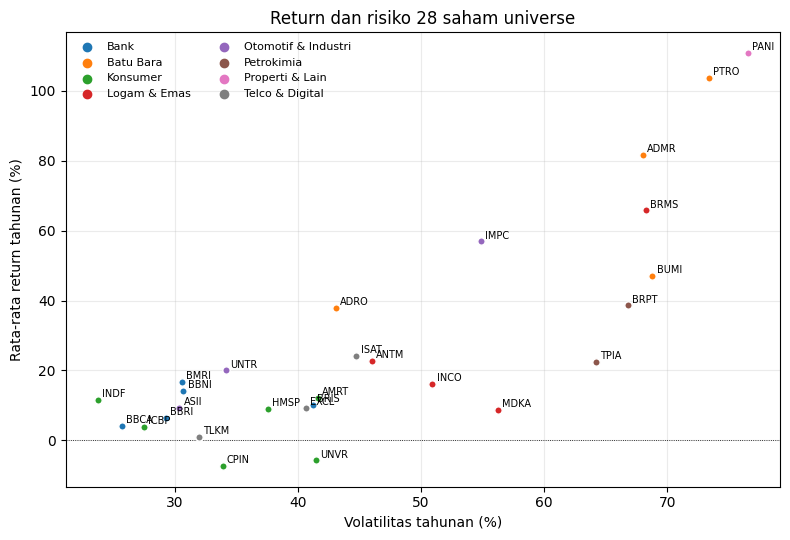

In [61]:
# Statistik deskriptif universe
UNI = estimation_window(FINAL_END).columns.tolist()
_r = daily_returns[UNI]
desc_ret = _r.mean() * TRADING_DAYS
desc_vol = _r.std() * np.sqrt(TRADING_DAYS)
_C = estimation_window(FINAL_END).corr()
_iu = np.triu_indices(len(UNI), 1)
_same, _diff = [], []
for _a in range(len(UNI)):
    for _b in range(_a + 1, len(UNI)):
        (_same if SECTOR_MAP.get(UNI[_a]) == SECTOR_MAP.get(UNI[_b]) else _diff).append(_C.values[_a, _b])
_cv = _C.values[_iu]
_tri = np.triu(np.ones_like(_C.values), 1) > 0
_kmax = np.unravel_index(np.argmax(np.where(_tri, _C.values, -9)), _C.shape)
_kmin = np.unravel_index(np.argmin(np.where(_tri, _C.values, 9)), _C.shape)
desc_stats = {
    "n saham": len(UNI),
    "return tahunan min": desc_ret.min(), "(saham)": desc_ret.idxmin(),
    "return tahunan max": desc_ret.max(), " (saham)": desc_ret.idxmax(),
    "saham return negatif": int((desc_ret < 0).sum()),
    "vol tahunan min": desc_vol.min(), "(saham) ": desc_vol.idxmin(),
    "vol tahunan max": desc_vol.max(), "(saham)  ": desc_vol.idxmax(),
    "korelasi rata-rata": _cv.mean(), "korelasi sesektor": np.mean(_same), "korelasi lintas sektor": np.mean(_diff),
    "korelasi tertinggi": f"{UNI[_kmax[0]]} - {UNI[_kmax[1]]} ({_C.values[_kmax]:.2f})",
    "korelasi terendah": f"{UNI[_kmin[0]]} - {UNI[_kmin[1]]} ({_C.values[_kmin]:.2f})",
}
display(pd.Series(desc_stats).to_frame("nilai"))

_sec = sorted({SECTOR_MAP.get(t, "Lain-lain") for t in UNI}); _pal = dict(zip(_sec, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(8, 5.5))
for t in UNI:
    ax.scatter(desc_vol[t] * 100, desc_ret[t] * 100, s=28, color=_pal[SECTOR_MAP.get(t, "Lain-lain")], edgecolor="white", zorder=3)
    ax.annotate(t.replace(".JK", ""), (desc_vol[t] * 100, desc_ret[t] * 100), fontsize=7, xytext=(3, 2), textcoords="offset points")
for s_ in _sec: ax.scatter([], [], color=_pal[s_], label=s_)
ax.axhline(0, color="k", lw=0.6, ls=":"); ax.legend(ncol=2, frameon=False, fontsize=8)
ax.set_xlabel("Volatilitas tahunan (%)"); ax.set_ylabel("Rata-rata return tahunan (%)"); ax.grid(alpha=.25)
ax.set_title("Return dan risiko 28 saham universe"); plt.tight_layout(); plt.savefig("fig_risk_return.png", dpi=150); plt.show()

Return tahunan dihitung dari rata-rata return harian yang dikalikan 252 hari bursa dalam setahun dan menunjukkan potensi keuntungan tahunan suatu saham. Volatilitas tahunan dihitung dari standar deviasi return harian yang dikalikan akar 252, sehingga menggambarkan tingkat risiko atau fluktuasi harga saham. Sementara itu, korelasi mengukur hubungan pergerakan return antar-saham dan digunakan untuk menilai manfaat diversifikasi dalam portofolio. Berdasarkan grafik, saham dengan return tinggi umumnya memiliki volatilitas yang lebih tinggi, menunjukkan adanya trade-off antara potensi keuntungan dan risiko investasi.

## 3. Faktor makro (tanpa fallback acak)

Faktor: **IHSG** (hanya variabel kontrol pasar), **USD/IDR**, **emas**, **minyak**. Emas dan minyak (pasar AS) di-lag 1 hari agar sinkron dengan jam bursa Indonesia.

In [62]:
# Loader faktor makro
MACRO_MAP = {"^JKSE": "IHSG", "IDR=X": "USDIDR", "GC=F": "Gold", "CL=F": "Oil"}
MACRO_COLS = ["IHSG", "USDIDR", "Gold", "Oil"]

def load_macro(start, end, cache="macro_factors.csv"):
    from_cache = os.path.exists(cache)
    if from_cache:
        px = pd.read_csv(cache, index_col=0, parse_dates=True)
        src = f"cache lokal ({cache})"
    else:
        try:
            import yfinance as yf
            raw = yf.download(list(MACRO_MAP), start=start, end=end + pd.Timedelta(days=1),
                              auto_adjust=False, progress=False)
            fields = raw.columns.get_level_values(0)
            px = raw["Adj Close"] if "Adj Close" in fields else raw["Close"]
            px = px.rename(columns=MACRO_MAP)
            px.index = pd.to_datetime(px.index).tz_localize(None)
            src = "yfinance"
        except Exception as e:
            print(f"[PERINGATAN] Unduh faktor makro gagal: {type(e).__name__}: {e}")
            return None, None
    # validasi: tidak boleh diam-diam salah
    if not set(MACRO_COLS).issubset(px.columns):
        print("[PERINGATAN] Kolom faktor tidak lengkap:", list(px.columns)); return None, None
    px = px[MACRO_COLS].sort_index()
    if px.dropna(how="all").shape[0] < 500 or (px.nunique() < 50).any():
        print("[PERINGATAN] Data faktor kosong/terlalu pendek/konstan; tidak dipakai.")
        if from_cache:
            print(f"   Cache {cache} tampak rusak: hapus file itu lalu jalankan ulang.")
        return None, None
    if not from_cache:
        px.to_csv(cache)          # simpan cache HANYA setelah lolos validasi
    ret = px.pct_change(fill_method=None)
    ret[["Gold", "Oil"]] = ret[["Gold", "Oil"]].shift(1)   # sinkronisasi jam bursa
    return ret.dropna(how="all"), src

macro_ret, macro_src = load_macro(daily_returns.index.min(), FINAL_END)
MACRO_OK = macro_ret is not None
if MACRO_OK:
    print(f"Faktor makro OK (sumber: {macro_src}) | {macro_ret.index.min().date()} s.d. {macro_ret.index.max().date()}")
    print(macro_ret.describe().loc[["count", "mean", "std"]].round(5))
else:
    print("\n" + "!" * 78)
    print("FAKTOR MAKRO TIDAK TERSEDIA -> view data-driven DIMATIKAN.")
    print("Portofolio tetap dihitung dgn prior ekuilibrium + skor sektor manual.")
    print("Solusi: jalankan di lingkungan dgn internet, atau letakkan macro_factors.csv (harga harian:")
    print("kolom date, IHSG, USDIDR, Gold, Oil) di folder notebook.")
    print("!" * 78)

# Skor komposit (F3 Rupiah dimatikan jika regresi makro aktif, agar tidak hitung ganda)
fw = FACTOR_WEIGHTS.copy()
if MACRO_OK:
    fw[FACTOR_NAMES.index("Rupiah")] = 0.0
    fw = fw / fw.sum()
score_df = pd.DataFrame.from_dict(RAW_SCORES, orient="index", columns=FACTOR_NAMES)
score_df["composite"] = score_df[FACTOR_NAMES].values @ fw
score_df["score_norm"] = (score_df["composite"] / 2.0).clip(-1, 1)

Faktor makro OK (sumber: yfinance) | 2022-01-04 s.d. 2026-08-31
Ticker        IHSG      USDIDR        Gold         Oil
count   1054.00000  1209.00000  1130.00000  1128.00000
mean       0.00004     0.00020     0.00083     0.00063
std        0.01048     0.00594     0.01216     0.02617


Berdasarkan data faktor makro periode 4 Januari 2022 hingga 31 Agustus 2026, rata-rata return harian seluruh faktor makro relatif kecil dan mendekati nol, yang menunjukkan bahwa pergerakan harian cenderung stabil. Emas (Gold) memiliki rata-rata return harian tertinggi (0,083%), diikuti Minyak (Oil) (0,063%), USD/IDR (0,020%), dan IHSG (0,004%).

Dari sisi risiko (standar deviasi), Minyak (Oil) merupakan faktor paling volatil dengan nilai 2,617%, menunjukkan fluktuasi harga yang paling besar. Selanjutnya adalah Emas (1,216%), IHSG (1,048%), dan USD/IDR (0,594%) yang menjadi faktor paling stabil. Dengan demikian, selama periode pengamatan, harga minyak memiliki risiko tertinggi, sedangkan nilai tukar USD/IDR memiliki risiko terendah.

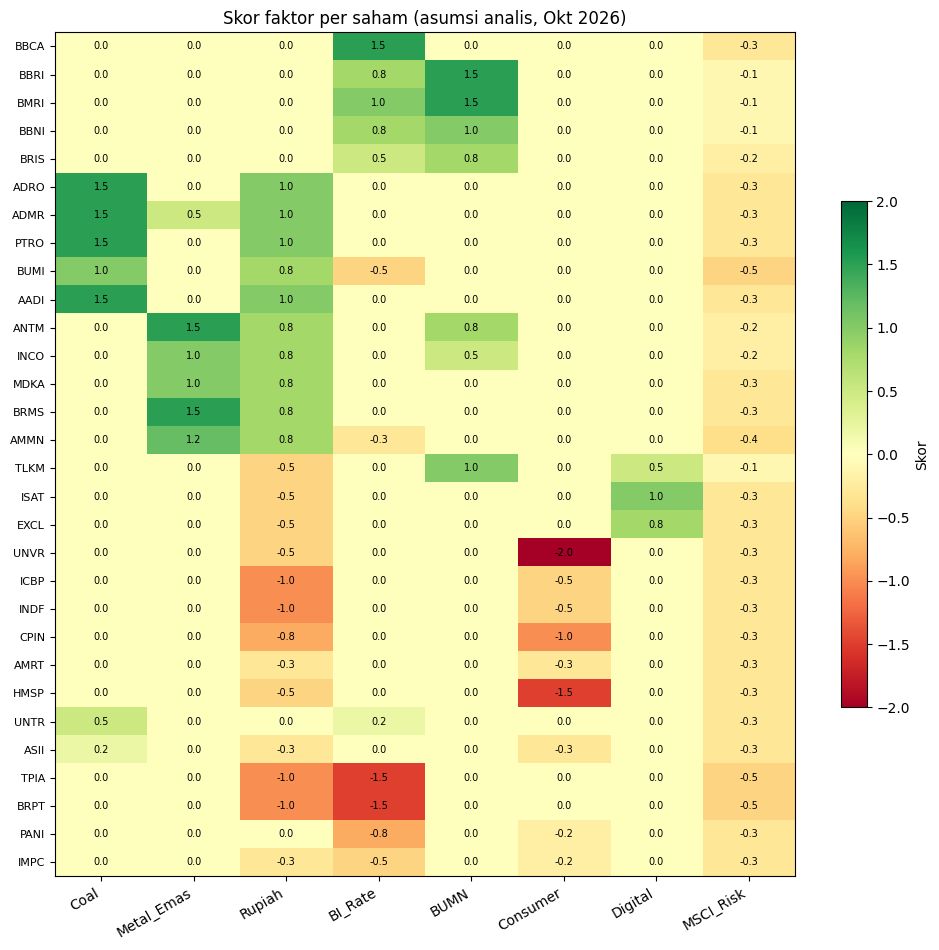

In [63]:
# Heatmap skor faktor
fig, ax = plt.subplots(figsize=(10, max(6, 0.32 * len(score_df))))
hm = score_df[FACTOR_NAMES].astype(float)
im = ax.imshow(hm.values, cmap="RdYlGn", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FACTOR_NAMES))); ax.set_xticklabels(FACTOR_NAMES, rotation=30, ha="right")
ax.set_yticks(range(len(hm))); ax.set_yticklabels([t.replace(".JK", "") for t in hm.index], fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.6, label="Skor")
ax.set_title("Skor faktor per saham (asumsi analis, Okt 2026)")
plt.tight_layout(); plt.savefig("factor_heatmap.png", dpi=130); plt.show()

Heatmap menunjukkan bahwa setiap sektor memiliki faktor pendorong yang berbeda. Saham batu bara seperti ADRO, ADMR, PTRO, dan AADI paling diuntungkan oleh kenaikan harga batu bara. Saham tambang logam seperti ANTM, INCO, BRMS, dan AMMN sensitif terhadap harga logam dan emas. Sektor perbankan (BBCA, BBRI, BMRI, BBNI, BRIS) memperoleh skor positif dari faktor BI Rate dan BUMN, sedangkan sektor telekomunikasi (TLKM, ISAT, EXCL) mendapat dukungan dari faktor Digital. Sebaliknya, saham konsumsi seperti UNVR, ICBP, INDF, CPIN, dan HMSP cenderung memiliki skor negatif, yang menunjukkan kondisi makro saat ini kurang mendukung sektor tersebut. Secara umum, faktor batu bara, logam/emas, dan suku bunga menjadi pendorong utama kinerja saham pada periode analisis.

## 4. Model dan optimizer

* **Kovarians** = 50% Ledoit-Wolf + 50% EWMA (half-life 63 hari). Campuran dua matriks positif-semidefinit tetap positif-definit.
* **Prior** `π = rf + δ·Σ·w_mkt` dari bobot market cap (komparator Black-Litterman).
* **Risk Parity (ERC)**: bobot yang membuat kontribusi risiko tiap saham sama, dengan batas 10% per saham dan 35% per sektor.
* **Optimizer**: SLSQP dari lima titik awal (deterministik). **Simulator**: buy-and-hold harian dengan biaya beli/jual dan opsi kas.

In [64]:
# Fungsi model
def cov_blend(est):
    """50% Ledoit-Wolf + 50% EWMA, tahunan."""
    X = est.values
    S_lw = LedoitWolf().fit(X).covariance_ * TRADING_DAYS
    lam = 0.5 ** (1 / EWMA_HL)
    w = lam ** np.arange(len(X) - 1, -1, -1); w /= w.sum()
    xc = X - (w[:, None] * X).sum(0)
    S_ew = (xc * w[:, None]).T @ xc * TRADING_DAYS
    S = (1 - W_EWMA) * S_lw + W_EWMA * S_ew
    return pd.DataFrame((S + S.T) / 2, index=est.columns, columns=est.columns)

def cov_lw(est):
    return pd.DataFrame(LedoitWolf().fit(est.values).covariance_ * TRADING_DAYS,
                        index=est.columns, columns=est.columns)

def mu_hist_shrunk(est):
    raw = est.mean() * TRADING_DAYS
    return (1 - SHRINK) * raw + SHRINK * raw.mean()

def equilibrium_prior(S):
    cap = MCAP.reindex(S.index)
    cap = cap.fillna(cap.median())
    w_m = cap / cap.sum()
    pi = RF + DELTA * (S.values @ w_m.values)
    return pd.Series(pi, index=S.index), w_m

def factor_betas(est, macro_ret):
    """OLS: return saham ~ IHSG + USDIDR + Gold + Oil. Mengembalikan beta dan t-stat."""
    Xm = macro_ret[MACRO_COLS].reindex(est.index).dropna()
    assert len(Xm) >= 300, "Irisan tanggal saham-faktor terlalu sedikit"
    X = np.column_stack([np.ones(len(Xm)), Xm.values])
    XtX_inv = np.linalg.inv(X.T @ X)
    B, T = {}, {}
    for t in est.columns:
        y = est.loc[Xm.index, t].values
        b = XtX_inv @ X.T @ y
        e = y - X @ b
        se = np.sqrt(np.diag(XtX_inv) * (e @ e) / (len(y) - X.shape[1]))
        B[t], T[t] = b[1:], b[1:] / se[1:]
    return (pd.DataFrame(B, index=MACRO_COLS).T, pd.DataFrame(T, index=MACRO_COLS).T)

def data_view_delta(betas, tvals, scale=1.0):
    d = pd.Series(0.0, index=betas.index)
    for f, s in SHOCKS.items():
        b = betas[f].where(tvals[f].abs() >= T_MIN, 0.0)
        d += b * s * SCENARIO_ANNUALIZER
    return d * scale

def score_view_delta(tickers, scale=1.0):
    return score_df["score_norm"].reindex(tickers).fillna(0.0) * MAX_VIEW * scale

def black_litterman(pi, S, views):
    """views: daftar (Series delta, keyakinan). Tiap saham dgn |delta|>0 jadi satu view absolut Q = pi + delta."""
    n = len(pi); tauS = TAU * S.values
    rows, Q, om = [], [], []
    for delta, conf in views:
        if conf is None or conf <= 0:
            continue
        for i, t in enumerate(pi.index):
            d = float(delta.get(t, 0.0))
            if abs(d) < 1e-6:
                continue
            p = np.zeros(n); p[i] = 1.0
            rows.append(p); Q.append(pi.iloc[i] + d); om.append(tauS[i, i] * (1 / conf - 1))
    if not rows:
        return pi.copy(), 0
    P, Qv, Om = np.array(rows), np.array(Q), np.diag(om)
    A = P @ tauS @ P.T + Om
    mu = pi.values + tauS @ P.T @ np.linalg.solve(A, Qv - P @ pi.values)
    return pd.Series(mu, index=pi.index), len(rows)

cov_blend(est)
 Menggabungkan kovarians Ledoit-Wolf dan EWMA dengan bobot 50:50 untuk menghasilkan estimasi risiko yang lebih stabil. Digunakan untuk menghitung volatilitas portofolio dan hubungan risiko antar saham.

cov_lw(est)
 Menghitung matriks kovarians menggunakan metode Ledoit-Wolf sebagai pembanding atau analisis tambahan.

mu_hist_shrunk(est)
 Menghitung return historis tahunan lalu menyesuaikannya ke rata-rata seluruh saham untuk mengurangi noise dan ekstremitas data historis.

equilibrium_prior(S)
 Menghitung return ekuilibrium berdasarkan kapitalisasi pasar, menghasilkan estimasi return pasar (prior return) dan bobot pasar.

factor_betas(est, macro_ret)
 Mengukur sensitivitas saham terhadap faktor makro (IHSG, USD/IDR, emas, minyak) menggunakan regresi. Menghasilkan nilai beta dan statistik t.

data_view_delta(...)
 Mengubah perubahan faktor makro menjadi penyesuaian return saham berdasarkan beta yang signifikan secara statistik.

score_view_delta(...)
 Mengubah skor faktor menjadi penyesuaian return saham dengan batas kekuatan view yang telah ditentukan.

black_litterman(...)
 Menggabungkan return ekuilibrium (prior) dengan berbagai view atau opini tambahan untuk menghasilkan estimasi return akhir yang lebih robust.

Output akhir: estimasi risiko (kovarians), estimasi return saham, dan return akhir yang telah disesuaikan menggunakan model Black-Litterman.

In [65]:
# Optimizer, simulator, dan metrik
def sector_groups(tickers):
    gg = {}
    for i, t in enumerate(tickers):
        gg.setdefault(SECTOR_MAP.get(t, "Lain-lain"), []).append(i)
    return gg

def _constraints(tickers):
    n = len(tickers); groups = sector_groups(tickers)
    if n * W_MAX < 1 or sum(min(SECTOR_CAP, len(ix) * W_MAX) for ix in groups.values()) < 1:
        raise ValueError("Constraint tidak feasible: longgarkan W_MAX/SECTOR_CAP atau tambah saham")
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}]
    for ix in groups.values():
        ind = np.zeros(n); ind[ix] = 1.0
        cons.append({"type": "ineq", "fun": lambda w, ind=ind: SECTOR_CAP - ind @ w, "jac": lambda w, ind=ind: -ind})
    return n, cons

def _solve(f, g, tickers, extra=(), starts=None):
    n, cons = _constraints(tickers); cons = cons + list(extra)
    rng = np.random.default_rng(0)                      # deterministik: hasil sama di setiap run
    if starts is None:
        starts = [np.full(n, 1 / n)] + [rng.dirichlet(np.ones(n)) for _ in range(4)]
    best = None
    for w0 in starts:
        r = minimize(f, w0, jac=g, method="SLSQP", bounds=[(0, W_MAX)] * n, constraints=cons,
                     options={"maxiter": 2000, "ftol": 1e-12})
        if r.success and (best is None or r.fun < best.fun):
            best = r
    if best is None:
        raise RuntimeError("Optimasi gagal pada semua titik awal")
    w = np.clip(best.x, 0, W_MAX); w[w < 1e-6] = 0; w /= w.sum()
    return pd.Series(w, index=tickers)

def optimize(kind, mu, S, vol_cap=None, ret_floor=None):
    """kind: minvar | maxsharpe | maxret. Long-only, sum=1, 0<=w<=W_MAX, cap sektor."""
    tickers = list(S.index); Sv = S.values; m = np.asarray(mu.reindex(tickers).values, dtype=float)
    extra = []
    if vol_cap is not None:
        extra.append({"type": "ineq", "fun": lambda w: vol_cap**2 - w @ Sv @ w, "jac": lambda w: -2 * Sv @ w})
    if ret_floor is not None:
        extra.append({"type": "ineq", "fun": lambda w: w @ m - ret_floor, "jac": lambda w: m})
    if kind == "minvar":
        f = lambda w: w @ Sv @ w;  g = lambda w: 2 * Sv @ w
    elif kind == "maxret":
        f = lambda w: -(w @ m);    g = lambda w: -m
    elif kind == "maxsharpe":
        def f(w): return -(w @ m - RF) / np.sqrt(w @ Sv @ w)
        def g(w):
            s = np.sqrt(w @ Sv @ w); return -(m / s - (w @ m - RF) * (Sv @ w) / s**3)
    else:
        raise ValueError(kind)
    return _solve(f, g, tickers, extra)

def risk_parity(S):
    """Equal Risk Contribution dengan batas bobot dan sektor."""
    Sv = S.values; k = len(S)
    def f(w):
        s2 = w @ Sv @ w; rc = w * (Sv @ w) / s2
        return ((rc - 1 / k) ** 2).sum()
    return _solve(f, None, list(S.index), starts=[np.full(k, 1 / k)])

def project(w0, tickers):
    """Proyeksi bobot ke himpunan feasible (jarak terdekat)."""
    w0 = np.asarray(w0, float); w0 = w0 / w0.sum()
    return _solve(lambda w: ((w - w0) ** 2).sum(), lambda w: 2 * (w - w0), tickers, starts=[w0])

def pstats(w, mu, S):
    r = float(w.values @ mu.reindex(w.index).values); v = float(np.sqrt(w.values @ S.values @ w.values))
    return r, v, (r - RF) / v

def structure(w):
    return pd.Series({"N(>0.5%)": int((w > 0.005).sum()), "Eff.N": 1 / (w**2).sum(),
                      "#di cap": int((w >= W_MAX - 1e-4).sum()), "Bobot max": w.max()})

def path_metrics(r):
    n = len(r); tot = (1 + r).prod() - 1; vol = r.std() * np.sqrt(TRADING_DAYS); V = (1 + r).cumprod()
    return pd.Series({"Total": tot, "CAGR": (1 + tot) ** (TRADING_DAYS / n) - 1, "Vol": vol,
                      "Sharpe": (r.mean() * TRADING_DAYS - RF) / vol, "MaxDD": (V / V.cummax() - 1).min()})

CASH = "CASH"
_R_UNI  = daily_returns[UNI]                                   # return universe (NaN = tidak diperdagangkan)
_RET_ALL = _R_UNI.fillna(0.0).assign(**{CASH: RF / TRADING_DAYS})
_PX     = price_table[UNI].ffill()

def simulate_dyn(dates, target_fn, force=None, band=None):
    force = set(dates) if force is None else set(force)
    cols = UNI + [CASH]; hold = pd.Series(0.0, index=cols); V = 1.0; out = []; turns = []
    for j, t in enumerate(dates):
        t_next = dates[j + 1] if j + 1 < len(dates) else _RET_ALL.index[-1]
        seg = _RET_ALL.loc[(_RET_ALL.index > t) & (_RET_ALL.index <= t_next), cols]
        if len(seg) == 0:
            break
        w_old = hold / V; w_new = target_fn(t).reindex(cols).fillna(0.0)
        turn = 0.5 * (w_new - w_old)[UNI].abs().sum()
        V_pre = V
        if (t in force) or j == 0 or (band is not None and turn >= band):
            d = (w_new - w_old)[UNI]; cost = COST_BUY * d.clip(lower=0).sum() + COST_SELL * (-d).clip(lower=0).sum()
            hold = w_new * V * (1 - cost); turns.append(turn)
        g_ = (1 + seg).cumprod(); Vs = g_.mul(hold, axis=1).sum(axis=1)
        prev = Vs.shift(1); prev.iloc[0] = V_pre
        out.append(Vs / prev - 1); hold = g_.iloc[-1] * hold; V = Vs.iloc[-1]
    r = pd.concat(out); r.attrs["turnover"] = float(np.mean(turns[1:])) if len(turns) > 1 else np.nan
    r.attrs["n_reb"] = len(turns); return r

def month_resample(r):
    try:    return (1 + r).resample("ME").prod() - 1
    except ValueError: return (1 + r).resample("M").prod() - 1

print("Optimizer, simulator, dan metrik dimuat.")

Optimizer, simulator, dan metrik dimuat.


Ringkasan Mesin Optimasi Portofolio
- Pengelompokan saham → sector_groups() mengelompokkan saham berdasarkan sektor.
- Penetapan batasan investasi → _constraints() mengatur batas bobot saham dan sektor.
- Proses optimasi → _solve() menjalankan optimizer untuk mencari kombinasi bobot terbaik.
- Metode optimasi → optimize() menyediakan:
- Min Variance: meminimalkan risiko portofolio.
- Max Sharpe: memaksimalkan rasio return terhadap risiko.
- Max Return: memaksimalkan return yang diharapkan.
- Risk Parity → risk_parity() membagi kontribusi risiko antar saham agar lebih seimbang.
- Validasi bobot → project() memastikan alokasi memenuhi seluruh batasan.
- Evaluasi portofolio → pstats() menghitung return, volatilitas, dan Sharpe Ratio.
- Analisis diversifikasi → structure() mengukur jumlah posisi dan tingkat diversifikasi.
- Analisis historis → path_metrics() menghitung performa berdasarkan simulasi historis.
- Simulasi portofolio → simulate_dyn() mensimulasikan perubahan nilai portofolio beserta biaya transaksi.
- Agregasi data → month_resample() mengubah return harian menjadi return bulanan.

**Constraint Utama**
Total bobot portofolio = 100%.
Bobot tiap saham = 0%–10%.
Bobot tiap sektor ≤ 35%.
Tidak ada posisi short selling dan konsentrasi berlebihan pada saham maupun sektor.

**Output**
Bobot portofolio optimal.
Estimasi return, risiko, dan Sharpe Ratio.
Hasil simulasi dan evaluasi performa portofolio.

## 5. Ringkasan skill model prediktif (validasi 2025, 28 saham yang berhasil melewati seleksi)
IC = korelasi peringkat harian antar-saham antara prediksi dan return aktual.

In [66]:
# Ringkasan prediktif statis
def daily_ic(g):
    ics = {}
    for d_, x in g.groupby("date"):
        if len(x) >= 10 and x["predicted_return"].nunique() >= 3:
            ics[d_] = x["predicted_return"].rank().corr(x["actual_return"].rank())
    return pd.Series(ics, dtype=float).dropna()

def _err_metrics(df):
    out = []
    for t, x in df.groupby("ticker"):
        a = x["actual_return"].to_numpy(float); p = x["predicted_return"].to_numpy(float)
        out.append((np.mean(np.abs(a - p)), np.sqrt(np.mean((a - p) ** 2)), np.mean(np.sign(a) == np.sign(p))))
    return np.mean(out, axis=0)

if "validation_predictions" in globals():
    _vp = validation_predictions[validation_predictions["ticker"].isin(UNI)]
    _rows = {}
    for m_, x in _vp.groupby("model"):
        mae_, rmse_, da_ = _err_metrics(x); ic_ = daily_ic(x)
        sd_ = ic_.std() if len(ic_) > 5 else np.nan
        _rows[m_] = {"MAE %": mae_ * 100, "RMSE %": rmse_ * 100,
                     "Arah %": np.nan if m_ == "Zero Return Baseline" else da_ * 100,
                     "IC": ic_.mean() if len(ic_) else np.nan,
                     "t-stat": ic_.mean() / (sd_ / np.sqrt(len(ic_))) if sd_ and sd_ > 0 else np.nan}
    pred_static = pd.DataFrame(_rows).T
    display(pred_static.round(3))
    _all = validation_predictions.assign(ae=(validation_predictions["actual_return"] - validation_predictions["predicted_return"]).abs())
    _mae_all = _all.groupby(["ticker", "model"])["ae"].mean().groupby("model").mean()
    print(f"Model dengan MAE terendah pada seluruh {validation_predictions['ticker'].nunique()} saham validasi: {_mae_all.idxmin()}")
else:
    pred_static = None
    print("validation_predictions tidak ditemukan; jalankan bagian Predictive lebih dulu.")

,MAE %,RMSE %,Arah %,IC,t-stat
Historical Mean Baseline,2.207,3.205,44.734,-0.019,-1.275
Linear Regression,2.238,3.241,46.383,0.001,0.105
Random Forest,2.248,3.242,45.551,0.002,0.152
Zero Return Baseline,2.190,3.206,NaN,NaN,NaN


Model dengan MAE terendah pada seluruh 47 saham validasi: Zero Return Baseline


Interpretasi Hasil Prediksi Model

MAE (%): Mengukur rata-rata kesalahan prediksi. Semakin kecil nilainya, semakin baik. Pada hasil ini, Zero Return Baseline (2,190%) dan Historical Mean (2,207%) sedikit lebih baik dibanding Linear Regression dan Random Forest.

RMSE (%): Mengukur kesalahan dengan penalti lebih besar untuk error yang ekstrem. Semakin kecil semakin baik. Seluruh model memiliki nilai yang mirip (≈3,2%), menunjukkan akurasi prediksi yang relatif setara.

Arah (%): Persentase keberhasilan model dalam menebak arah naik atau turun saham. Nilainya hanya 44%-46%, mendekati acak (50%), sehingga kemampuan prediksi arah masih lemah.

IC (Information Coefficient): Mengukur kemampuan model mengurutkan saham berdasarkan return yang akan datang.

IC positif = ranking prediksi searah dengan ranking aktual.
IC nol = hampir tidak ada hubungan.
IC negatif = ranking prediksi berlawanan dengan hasil aktual. Pada hasil ini, seluruh IC berada di sekitar 0 (-0,019 hingga 0,002), sehingga model belum mampu memberi peringkat saham secara konsisten.

t-stat: Menguji signifikansi statistik dari IC. Nilai yang mendekati 0 menunjukkan IC tidak signifikan. Seluruh model memiliki t-stat yang rendah (-1,275 hingga 0,152), sehingga tidak ada bukti kuat bahwa model memiliki kemampuan prediksi yang andal.

Kesimpulan
Tidak ada model yang menunjukkan keunggulan prediktif yang signifikan.
Historical Mean, Linear Regression, dan Random Forest memiliki performa yang hampir sama.
IC yang mendekati nol dan t-stat yang rendah menunjukkan model belum mampu mengurutkan saham dengan baik untuk keperluan strategi investasi.

## 6. Walk-forward: semua strategi, rebalancing bulanan, biaya transaksi dihitung

Pada tiap akhir bulan sejak Des 2023, bobot dihitung **hanya dari data sampai tanggal itu** (kovarians campuran, prior dari market cap yang disesuaikan harga hingga tanggal itu), lalu ditahan sampai akhir bulan berikutnya. Periode dibagi dua: **periode 1** (s.d. Jun 2025) untuk seleksi dan **periode 2** (Jul 2025-Agu 2026) untuk konfirmasi.

Strategi: Equal Weight, bobot market cap (benchmark), Min Variance, Min Variance + filter tren, Risk Parity (ERC), **Blend EW + ERC (utama)**, Blend EW + Min Variance, serta Max Sharpe dengan prior ekuilibrium dan dengan rata-rata historis.

In [67]:
# Walk-forward: target bobot
idx_ = daily_returns.index; _last = pd.Series(idx_, index=idx_).groupby(idx_.to_period("M")).last()
REB = [pd.Timestamp(d) for d in _last.values if pd.Timestamp(d) >= WF_FIRST]
EWIDX = (1 + _R_UNI.fillna(0).mean(axis=1)).cumprod()

STRATS = ["Equal Weight", "Bobot market cap", "Min Variance", "Min Variance + filter tren", "Risk Parity (ERC)",
          "Blend EW + ERC (utama)", "Blend EW + Min Variance", "Max Sharpe (prior BL)", "Max Sharpe (µ historis)"]
TG = {k: {} for k in STRATS}; _no_leak = []
t0 = time.time()
for t in REB:
    est = _R_UNI.loc[:t].dropna()
    if len(est) < 400:
        continue
    _no_leak.append(est.index.max() <= t)
    est = est.clip(est.quantile(0.01), est.quantile(0.99), axis=1)
    S = cov_blend(est)
    cap_t = MCAP.reindex(UNI) * (_PX.loc[t] / _PX.iloc[-1]); wm = cap_t / cap_t.sum()
    pi = pd.Series(RF + DELTA * (S.values @ wm.values), index=UNI)
    raw = est.mean() * TRADING_DAYS; mu_h = (1 - SHRINK) * raw + SHRINK * raw.mean()
    ew = pd.Series(1 / len(UNI), index=UNI); mv = optimize("minvar", mu_h, S); erc = risk_parity(S)
    on = EWIDX.loc[:t].iloc[-1] >= EWIDX.loc[:t].iloc[-TREND_MA:].mean(); expo = 1.0 if on else TREND_EXPO
    mvt = mv * expo; mvt[CASH] = 1 - expo
    TG["Equal Weight"][t] = ew; TG["Bobot market cap"][t] = wm; TG["Min Variance"][t] = mv
    TG["Min Variance + filter tren"][t] = mvt; TG["Risk Parity (ERC)"][t] = erc
    TG["Blend EW + ERC (utama)"][t] = 0.5 * ew + 0.5 * erc; TG["Blend EW + Min Variance"][t] = 0.5 * ew + 0.5 * mv
    TG["Max Sharpe (prior BL)"][t] = optimize("maxsharpe", pi, S); TG["Max Sharpe (µ historis)"][t] = optimize("maxsharpe", mu_h, S)
DATES = sorted(TG["Equal Weight"])
print(f"{len(DATES)} tanggal rebalancing ({DATES[0].date()} s.d. {DATES[-1].date()}) | {time.time()-t0:.0f} detik")

33 tanggal rebalancing (2023-12-29 s.d. 2026-08-31) | 9 detik


Walk-forward merupakan metode simulasi yang meniru proses investasi secara nyata dengan hanya menggunakan informasi yang tersedia pada saat keputusan dibuat. Dalam simulasi ini, bobot portofolio dihitung setiap akhir bulan, kemudian dipertahankan hingga periode berikutnya dengan memperhitungkan biaya transaksi saat terjadi perubahan alokasi. Evaluasi dilakukan dalam dua tahap, yaitu Periode 1 (hingga Juni 2025) untuk memilih strategi terbaik dan Periode 2 (Juli 2025–Agustus 2026) untuk menguji konsistensi kinerja strategi tersebut pada data yang berbeda. Beberapa strategi yang dibandingkan meliputi Equal Weight, Market Cap Weight, Min Variance, Risk Parity, kombinasi strategi, dan Max Sharpe. Pendekatan ini penting untuk memastikan bahwa strategi yang berkinerja baik pada satu periode historis tetap mampu memberikan hasil yang baik ketika diterapkan pada periode lain, sehingga mengurangi risiko overfitting.

Periode uji: 2024-01-02 s.d. 2026-08-31 (627 hari, 32 bulan)
Periode 1: 346 hari | Periode 2: 281 hari | biaya beli 0.15%, jual 0.25%


,Total,CAGR,Vol,Sharpe,MaxDD,Turnover/bln,Sharpe periode 1,Sharpe periode 2,Selisih bulanan vs EW (%),t-stat vs EW
Equal Weight,0.622,0.214,0.246,0.680,-0.365,0.045,0.596,0.770,NaN,NaN
Blend EW + ERC (utama),0.563,0.197,0.232,0.642,-0.352,0.047,0.467,0.818,-0.141,-1.264
Max Sharpe (µ historis),0.568,0.198,0.265,0.598,-0.435,0.102,0.593,0.617,-0.029,-0.049
Risk Parity (ERC),0.505,0.178,0.220,0.595,-0.339,0.052,0.320,0.864,-0.283,-1.270
Blend EW + Min Variance,0.493,0.175,0.215,0.589,-0.345,0.067,0.230,0.929,-0.315,-1.086
Min Variance + filter tren,0.413,0.149,0.161,0.586,-0.244,0.107,-0.240,1.331,-0.556,-0.762
Min Variance,0.361,0.132,0.198,0.434,-0.327,0.104,-0.259,1.052,-0.637,-1.096
Max Sharpe (prior BL),-0.001,-0.000,0.237,-0.125,-0.402,0.040,0.068,-0.319,-1.556,-4.130
Bobot market cap,-0.106,-0.044,0.249,-0.288,-0.415,0.000,0.049,-0.643,-1.903,-3.582


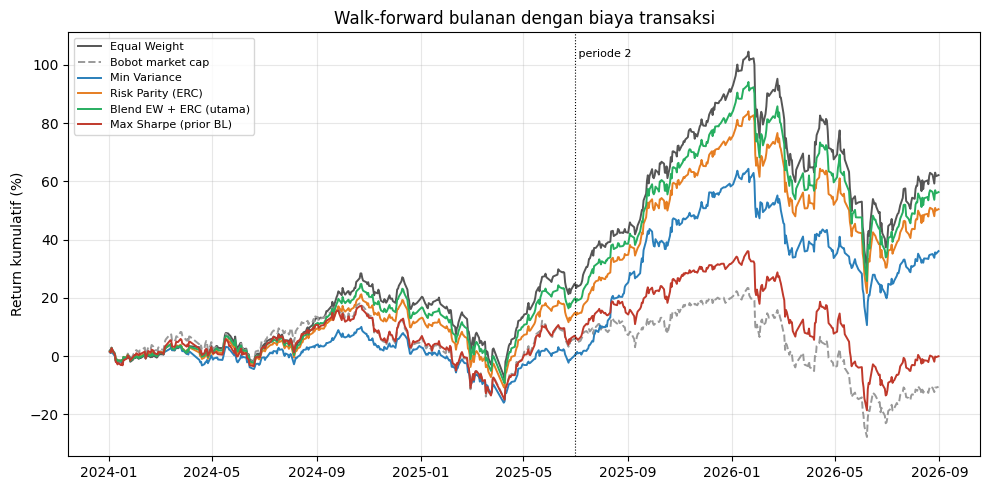

In [68]:
# Walk-forward: simulasi dan hasil
RETW = {}; TURN = {}; NREB = {}
for k in STRATS:
    r_ = simulate_dyn(DATES, lambda t, k=k: TG[k][t]); RETW[k] = r_; TURN[k] = r_.attrs["turnover"]; NREB[k] = r_.attrs["n_reb"]
RETW = pd.DataFrame(RETW)
_p1, _p2 = RETW.loc[:TUNE_END], RETW.loc[TUNE_END + pd.Timedelta(days=1):]
wf_full = pd.DataFrame({k: path_metrics(RETW[k]) for k in STRATS}).T
wf_p1   = pd.DataFrame({k: path_metrics(_p1[k]) for k in STRATS}).T
wf_p2   = pd.DataFrame({k: path_metrics(_p2[k]) for k in STRATS}).T
wf_tab  = wf_full.copy(); wf_tab["Turnover/bln"] = pd.Series(TURN)
wf_tab["Sharpe periode 1"] = wf_p1["Sharpe"]; wf_tab["Sharpe periode 2"] = wf_p2["Sharpe"]
_m = month_resample(RETW); _ex = _m.sub(_m["Equal Weight"], axis=0).drop(columns="Equal Weight")
wf_t = _ex.mean() / (_ex.std() / np.sqrt(len(_ex)))
wf_tab["Selisih bulanan vs EW (%)"] = _ex.mean() * 100; wf_tab["t-stat vs EW"] = wf_t

print(f"Periode uji: {RETW.index.min().date()} s.d. {RETW.index.max().date()} ({len(RETW)} hari, {len(_m)} bulan)")
print(f"Periode 1: {len(_p1)} hari | Periode 2: {len(_p2)} hari | biaya beli {COST_BUY:.2%}, jual {COST_SELL:.2%}")
display(wf_tab.sort_values("Sharpe", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
for k, c, ls in [("Equal Weight", "#555555", "-"), ("Bobot market cap", "#999999", "--"), ("Min Variance", "#2a7fba", "-"),
                 ("Risk Parity (ERC)", "#e67e22", "-"), ("Blend EW + ERC (utama)", "#27ae60", "-"), ("Max Sharpe (prior BL)", "#c0392b", "-")]:
    s_ = (1 + RETW[k]).cumprod() - 1; ax.plot(s_.index, s_.values * 100, color=c, ls=ls, lw=1.4, label=k)
ax.axvline(TUNE_END, color="k", ls=":", lw=0.8); ax.text(TUNE_END, ax.get_ylim()[1] * 0.95, " periode 2", fontsize=8, va="top")
ax.set_ylabel("Return kumulatif (%)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Walk-forward bulanan dengan biaya transaksi"); plt.tight_layout(); plt.savefig("fig_walk_forward.png", dpi=150); plt.show()

Berdasarkan hasil walk-forward dengan biaya transaksi, strategi Equal Weight memberikan kinerja terbaik dan paling konsisten, dengan return kumulatif akhir sekitar 60%. Strategi Blend EW + ERC dan Risk Parity juga menunjukkan performa yang kuat dengan return akhir sekitar 50-55%, sehingga menjadi alternatif yang cukup kompetitif.

Pada Periode 2 (setelah Juli 2025), strategi yang sebelumnya unggul tetap mampu mempertahankan kinerja relatif baik, meskipun seluruh strategi mengalami koreksi tajam pada awal dan pertengahan 2026. Hal ini menunjukkan bahwa performa yang baik tidak hanya terjadi pada periode seleksi, tetapi juga cukup terkonfirmasi pada periode pengujian.

Sebaliknya, strategi Bobot Market Cap menghasilkan kinerja yang kurang memuaskan dengan return akhir negatif sekitar -10%, sedangkan Max Sharpe hanya mendekati 0% setelah mengalami penurunan signifikan. Hasil ini mengindikasikan bahwa strategi yang berfokus pada diversifikasi seperti Equal Weight, Blend EW + ERC, dan Risk Parity lebih tangguh menghadapi perubahan kondisi pasar dibanding strategi yang terlalu bergantung pada estimasi return atau kapitalisasi pasar.

## 7. Fase B: portofolio utama (estimasi s.d. Agu 2026)

Portofolio utama = **50% Equal Weight + 50% Risk Parity**. Keduanya tidak membutuhkan estimasi return, sehingga tidak terkena kesalahan estimasi yang membuat optimasi berbasis return rapuh. Blend dengan Equal Weight mempertahankan diversifikasi sederhana, sedangkan Risk Parity menurunkan bobot saham yang sangat volatil.

*Return (prior)* di tabel adalah return ekuilibrium untuk gambaran saja; keputusan portofolio utama tidak bergantung padanya.

In [69]:
# Fase B: portofolio utama
est_b = estimation_window(FINAL_END); uni_b = est_b.columns.tolist(); assert uni_b == UNI
S_b = cov_blend(est_b); pi_b, wm_b = equilibrium_prior(S_b); n_b = len(uni_b)
w_ew = pd.Series(1 / n_b, index=uni_b); w_erc = risk_parity(S_b); w_mv = optimize("minvar", pi_b, S_b)
w_blend = 0.5 * w_ew + 0.5 * w_erc; w_blend_mv = 0.5 * w_ew + 0.5 * w_mv; w_ms = optimize("maxsharpe", pi_b, S_b)
port_b = {"Equal Weight": w_ew, "Risk Parity (ERC)": w_erc, "Blend EW + ERC (utama)": w_blend,
          "Blend EW + Min Variance": w_blend_mv, "Min Variance": w_mv, "Max Sharpe (prior BL)": w_ms}
ex_b = pd.DataFrame({k: pd.Series(dict(zip(["Return (prior)", "Vol", "Sharpe (prior)"], pstats(w, pi_b, S_b)))) for k, w in port_b.items()}).T
stru_b = pd.DataFrame({k: structure(w) for k, w in port_b.items()}).T
sect_b = pd.DataFrame({k: pd.Series({s: w.iloc[ix].sum() for s, ix in sector_groups(uni_b).items()}) for k, w in port_b.items()}).fillna(0)
_rc = lambda w: w * (S_b.values @ w.values) / (w.values @ S_b.values @ w.values)
rc_b = pd.DataFrame({k: _rc(w) for k, w in port_b.items()})
print(f"Universe Fase B: {n_b} saham, {len(est_b)} hari estimasi")
print("\n=== MODEL (ex-ante) ==="); display(ex_b.round(3))
print("\n=== STRUKTUR ==="); display(stru_b.round(3))
print("\n=== BOBOT PER SEKTOR (%) ==="); display((sect_b * 100).round(1))
print("\n=== KONTRIBUSI RISIKO: maks / min / rasio ===")
display(pd.DataFrame({"maks": rc_b.max(), "min": rc_b.min(), "rasio": rc_b.max() / rc_b.min()}).round(3))

Universe Fase B: 28 saham, 1111 hari estimasi

=== MODEL (ex-ante) ===


,Return (prior),Vol,Sharpe (prior)
Equal Weight,0.186,0.242,0.531
Risk Parity (ERC),0.170,0.209,0.539
Blend EW + ERC (utama),0.178,0.225,0.537
Blend EW + Min Variance,0.165,0.200,0.539
Min Variance,0.145,0.176,0.497
Max Sharpe (prior BL),0.180,0.219,0.562



=== STRUKTUR ===


,N(>0.5%),Eff.N,#di cap,Bobot max
Equal Weight,28.0,28.000,0.0,0.036
Risk Parity (ERC),28.0,25.108,0.0,0.064
Blend EW + ERC (utama),28.0,27.216,0.0,0.050
Blend EW + Min Variance,28.0,20.880,0.0,0.068
Min Variance,16.0,11.845,7.0,0.100
Max Sharpe (prior BL),28.0,18.107,2.0,0.100



=== BOBOT PER SEKTOR (%) ===


,Equal Weight,Risk Parity (ERC),Blend EW + ERC (utama),Blend EW + Min Variance,Min Variance,Max Sharpe (prior BL)
Batu Bara,14.3,10.8,12.5,12.1,10.0,6.9
Konsumer,21.4,29.6,25.5,28.2,35.0,15.5
Logam & Emas,14.3,9.7,12.0,8.0,1.8,7.8
Otomotif & Industri,10.7,11.5,11.1,15.4,20.0,11.7
Bank,17.9,19.8,18.9,18.9,20.0,35.0
Petrokimia,7.1,4.2,5.7,3.6,0.1,8.1
Telco & Digital,10.7,12.0,11.4,11.9,13.2,12.0
Properti & Lain,3.6,2.5,3.0,1.8,0.0,2.9



=== KONTRIBUSI RISIKO: maks / min / rasio ===


,maks,min,rasio
Equal Weight,0.070,0.015,4.627
Risk Parity (ERC),0.036,0.036,1.000
Blend EW + ERC (utama),0.054,0.024,2.205
Blend EW + Min Variance,0.062,0.017,3.728
Min Variance,0.108,0.000,inf
Max Sharpe (prior BL),0.097,0.011,8.849


Berdasarkan hasil analisis, portofolio utama dipilih sebagai kombinasi 50% Equal Weight dan 50% Risk Parity (ERC) karena mampu menyeimbangkan kesederhanaan alokasi dan pengelolaan risiko. Equal Weight memberikan distribusi bobot yang merata ke seluruh saham, sedangkan Risk Parity menyesuaikan alokasi berdasarkan volatilitas dan korelasi sehingga kontribusi risiko lebih seimbang. Kombinasi keduanya menghasilkan estimasi return 17,8%, volatilitas 22,5%, dan Sharpe Ratio 0,537, dengan tingkat diversifikasi yang sangat baik karena mencakup seluruh 28 saham dan memiliki effective number of stocks sebesar 27,2. Alokasi sektor juga relatif seimbang tanpa ada konsentrasi berlebihan pada sektor tertentu, sementara rasio kontribusi risiko (2,205) menunjukkan distribusi risiko yang lebih merata dibanding Equal Weight murni. Oleh karena itu, strategi ini dipilih sebagai portofolio utama karena menawarkan keseimbangan antara return, risiko, dan diversifikasi tanpa terlalu bergantung pada prediksi return masa depan.

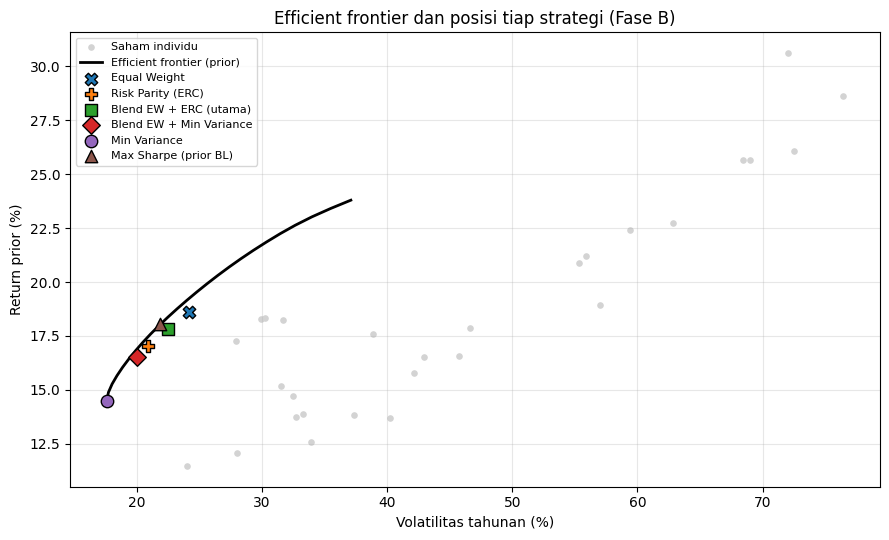

In [70]:
# Frontier (return = prior ekuilibrium)
def frontier(mu, S, npts=25):
    r_lo = pstats(optimize("minvar", mu, S), mu, S)[0]
    r_hi = pstats(optimize("maxret", mu, S), mu, S)[0] * 0.98
    pts = []
    for t_ in np.linspace(r_lo, max(r_hi, r_lo), npts):
        try:
            w = optimize("minvar", mu, S, ret_floor=t_); r, v, _ = pstats(w, mu, S); pts.append((v, r))
        except Exception:
            continue
    return np.array(pts)

fr = frontier(pi_b, S_b); iv = np.sqrt(np.diag(S_b.values))
plt.figure(figsize=(9, 5.5))
plt.scatter(iv * 100, pi_b.values * 100, s=14, c="lightgray", label="Saham individu")
if len(fr) > 1: plt.plot(fr[:, 0] * 100, fr[:, 1] * 100, "k-", lw=2, label="Efficient frontier (prior)")
for (k, w), mk in zip(port_b.items(), ["X", "P", "s", "D", "o", "^"]):
    r, v, _ = pstats(w, pi_b, S_b); plt.scatter(v * 100, r * 100, marker=mk, s=80, edgecolor="k", zorder=4, label=k)
plt.xlabel("Volatilitas tahunan (%)"); plt.ylabel("Return prior (%)"); plt.grid(alpha=.3); plt.legend(fontsize=8)
plt.title("Efficient frontier dan posisi tiap strategi (Fase B)"); plt.tight_layout(); plt.savefig("fig_frontier.png", dpi=150); plt.show()

Grafik efficient frontier menunjukkan bahwa seluruh strategi portofolio berada pada area yang lebih efisien dibanding sebagian besar saham individu, karena mampu memberikan return yang lebih tinggi untuk tingkat risiko yang sama atau lebih rendah. Min Variance memiliki volatilitas paling rendah sekitar 17,6% dengan return sekitar 14,5%, sehingga cocok bagi investor yang mengutamakan stabilitas. Sebaliknya, Equal Weight menghasilkan return tertinggi sekitar 18,6% dengan volatilitas yang juga lebih tinggi sekitar 24%. Risk Parity menawarkan profil yang lebih konservatif dengan return sekitar 17,0% dan volatilitas sekitar 21%, sementara Blend EW + ERC sebagai portofolio utama berada di tengah dengan return sekitar 17,8% dan volatilitas sekitar 22,5%. Posisi ini menunjukkan keseimbangan yang baik antara potensi keuntungan dan risiko, sekaligus tetap menjaga diversifikasi yang luas. Secara keseluruhan, pemilihan Blend EW + ERC didasarkan pada kemampuannya memberikan trade-off risiko dan return yang seimbang tanpa terlalu agresif seperti Equal Weight maupun terlalu defensif seperti Min Variance.

In [71]:
# Alokasi modal Rp10 juta (portofolio utama)
CAPITAL = 10_000_000
price_last = price_table[UNI].ffill().loc[:FINAL_END].iloc[-1]
alloc = pd.DataFrame({
    "Perusahaan": [NAMES.get(t, "-") for t in UNI], "Sektor": [SECTOR_MAP.get(t, "Lain-lain") for t in UNI],
    "Bobot %": (w_blend * 100).values, "Dana (Rp)": (w_blend * CAPITAL).values,
    "Harga": price_last.values, "Rp per lot": (price_last * 100).values}, index=[t.replace(".JK", "") for t in UNI])
alloc["Lot"] = np.floor(alloc["Dana (Rp)"] / alloc["Rp per lot"]).astype(int)
alloc["Rasio thd EW"] = alloc["Bobot %"] / (100 / n_b)
n_pos = int((alloc["Bobot %"] > 0.5).sum()); n_buy = int(((alloc["Bobot %"] > 0.5) & (alloc["Lot"] >= 1)).sum())
no_lot = alloc[(alloc["Bobot %"] > 0.5) & (alloc["Lot"] < 1)].index.tolist()
display(alloc.sort_values("Bobot %", ascending=False).round(2))
print(f"{n_buy} dari {n_pos} posisi dapat dibeli minimal 1 lot dengan modal Rp{CAPITAL:,.0f}. Belum terbeli: {no_lot}")

,Perusahaan,Sektor,Bobot %,Dana (Rp),Harga,Rp per lot,Lot,Rasio thd EW
INDF,Indofood Sukses Makmur Tbk.,Konsumer,4.96,496123.96,7500.00,750000.00,0,1.39
ICBP,Indofood CBP Sukses Makmur Tbk.,Konsumer,4.53,452794.72,7600.00,760000.00,0,1.27
CPIN,Charoen Pokphand Indonesia Tbk,Konsumer,4.36,435769.38,2980.00,298000.00,1,1.22
TLKM,Telkom Indonesia (Persero) Tbk.,Telco & Digital,4.25,425206.11,2600.00,260000.00,1,1.19
UNTR,United Tractors Tbk.,Otomotif & Industri,4.09,408646.94,23799.77,2379976.95,0,1.14
BBCA,Bank Central Asia Tbk.,Bank,4.07,406803.62,6475.00,647500.00,0,1.14
ASII,Astra International Tbk.,Otomotif & Industri,4.06,406356.98,4702.20,470220.36,0,1.14
HMSP,H.M. Sampoerna Tbk.,Konsumer,4.01,401307.09,740.00,74000.00,5,1.12
ADRO,Alamtri Resources Indonesia Tbk.,Batu Bara,4.00,399792.81,2840.00,284000.00,1,1.12
UNVR,Unilever Indonesia Tbk.,Konsumer,3.97,397457.03,1755.00,175500.00,2,1.11


18 dari 28 posisi dapat dibeli minimal 1 lot dengan modal Rp10,000,000. Belum terbeli: ['ASII', 'BBCA', 'BBNI', 'BMRI', 'ICBP', 'INCO', 'INDF', 'PANI', 'PTRO', 'UNTR']


In [72]:
# Komparator: Max Sharpe dengan view Black-Litterman (EKSPERIMEN, bukan portofolio utama)
if MACRO_OK:
    betas_b, tvals_b = factor_betas(est_b, macro_ret); d_data_b = data_view_delta(betas_b, tvals_b)
else:
    d_data_b = pd.Series(0.0, index=uni_b)
d_score_b = score_view_delta(uni_b)
mu_bl, n_views = black_litterman(pi_b, S_b, [(d_data_b, CONF_DATA), (d_score_b, CONF_SCORE)])
w_ms_bl = optimize("maxsharpe", mu_bl, S_b)
r_, v_, s_ = pstats(w_ms_bl, mu_bl, S_b)
print(f"PEMBANDING Max Sharpe (BL + view skor sektor{' + faktor makro' if MACRO_OK else ''}): µ={r_:.1%}, vol={v_:.1%}, Sharpe model={s_:.2f}, {n_views} view aktif")
print(f"Turnover bobot vs portofolio utama: {0.5 * (w_ms_bl - w_blend).abs().sum():.1%}")
print("Catatan: tidak diuji walk-forward (skor sektor memakai informasi Okt 2026) dan tidak dipakai sebagai rekomendasi utama.")

PEMBANDING Max Sharpe (BL + view skor sektor + faktor makro): µ=18.8%, vol=21.9%, Sharpe model=0.59, 41 view aktif
Turnover bobot vs portofolio utama: 32.3%
Catatan: tidak diuji walk-forward (skor sektor memakai informasi Okt 2026) dan tidak dipakai sebagai rekomendasi utama.


## 8. EKSPERIMEN BERLABEL: sinyal prediktif mingguan

**Status: eksperimen. Tidak masuk portofolio utama.**

Pertanyaan: jika model prediktif dilatih pada return harian **dan dilatih ulang tiap bulan** (walk-forward, sehingga skill yang diukur sama dengan model yang dipakai), apakah peringkat prediksinya berguna?

* Model: Linear Regression per saham (fitur notebook), Ridge gabungan dan Random Forest gabungan (fitur diperluas, target peringkat relatif).
* Horizon: 1 hari dan 5 hari. Keyakinan diukur dengan **IC** (korelasi peringkat) pada data di luar sampel.
* **Cara pakai yang konservatif**: sinyal hanya menggeser bobot portofolio utama (maks ±30%, `TILT_KAPPA = 0,15`), dengan rebalancing mingguan hanya bila turnover target ≥ 3% (`TILT_BAND`), ditambah rebalance bulanan seperti biasa.
* Catatan: Random Forest gabungan dipilih karena IC terbaik di antara tiga kandidat, sehingga hasilnya terlalu optimistis (bias seleksi).

In [73]:
# Eksperimen: panel fitur dan model walk-forward
NB_F = ["lag_1", "lag_2", "lag_5", "mean_5", "vol_5"]; EXT_F = NB_F + ["ret_20", "ret_60", "vol_20"]
def build_panel(R_):
    rows = []
    for t in R_.columns:
        r = R_[t]; lr = np.log1p(r)
        df = pd.DataFrame({"lag_1": r, "lag_2": r.shift(1), "lag_5": r.shift(4),
            "mean_5": r.rolling(5, min_periods=5).mean(), "vol_5": r.rolling(5, min_periods=5).std(),
            "ret_20": np.expm1(lr.rolling(20, min_periods=20).sum()), "ret_60": np.expm1(lr.rolling(60, min_periods=60).sum()),
            "vol_20": r.rolling(20, min_periods=20).std()})
        df["y1"] = r.shift(-1); df["y5"] = np.expm1(lr[::-1].rolling(5, min_periods=5).sum()[::-1].shift(-1))
        df["ticker"] = t; df["date"] = df.index; rows.append(df)
    P_ = pd.concat(rows, ignore_index=True).dropna(subset=EXT_F)       # fitur wajib lengkap; target boleh kosong (hari terakhir)
    for c in EXT_F:
        P_[c + "_z"] = P_.groupby("date")[c].transform(lambda x: (x - x.mean()) / (x.std(ddof=0) + 1e-12))
    for h in (1, 5):
        P_[f"yd{h}"] = P_[f"y{h}"] - P_.groupby("date")[f"y{h}"].transform("mean")
    return P_

P = build_panel(_R_UNI); _dates = _R_UNI.index; _di = {d: i for i, d in enumerate(_dates)}; P["di"] = P["date"].map(_di)
_months = pd.period_range("2024-01", FINAL_END.to_period("M"), freq="M")
MODELS = ["LR per saham", "Ridge gabungan", "RF gabungan"]

def run_models(h):
    y, yd, Z = f"y{h}", f"yd{h}", [c + "_z" for c in EXT_F]; preds = {k: [] for k in MODELS}
    for m in _months:
        te = P[P["date"].dt.to_period("M") == m]
        if te.empty: continue
        cut_i = _di[_dates[_dates.to_period("M") < m][-1]]
        tr = P[(P["di"] + h <= cut_i) & P[y].notna()]; out = []
        for t, tt in te.groupby("ticker"):
            trt = tr[tr["ticker"] == t]
            if len(trt) < 250: continue
            out.append(pd.Series(LinearRegression().fit(trt[NB_F], trt[y]).predict(tt[NB_F]), index=tt.index))
        preds["LR per saham"].append(pd.concat(out))
        preds["Ridge gabungan"].append(pd.Series(Ridge(alpha=10).fit(tr[Z], tr[yd]).predict(te[Z]), index=te.index))
        rf_ = RandomForestRegressor(n_estimators=100, max_depth=4, min_samples_leaf=300, random_state=42, n_jobs=-1).fit(tr[Z], tr[yd])
        preds["RF gabungan"].append(pd.Series(rf_.predict(te[Z]), index=te.index))
    return {k: pd.concat(v) for k, v in preds.items()}

def ic_stats(pr, h):
    y = f"y{h}"; d = P.loc[pr.index, ["date", "ticker", y]].assign(p=pr).dropna(subset=[y])
    ic = d.groupby("date").apply(lambda x: spearmanr(x["p"], x[y])[0] if (x["p"].nunique() > 3 and len(x) >= 10) else np.nan).dropna().iloc[::h]
    return pd.Series({"n tanggal": len(ic), "IC": ic.mean(), "t-stat": ic.mean() / (ic.std() / np.sqrt(len(ic))), "% IC>0": (ic > 0).mean() * 100,
                      "Arah %": (np.sign(d["p"]) == np.sign(d[y])).mean() * 100})

def topk_test(pr, h, k=10):
    """Long-only top-k vs Equal Weight, rebalance tiap h hari, biaya dihitung."""
    y = f"y{h}"; d = P.loc[pr.index, ["date", "ticker", y]].assign(p=pr).dropna(subset=[y]); ds = sorted(d["date"].unique())[::h]
    old = pd.Series(0.0, index=UNI); oe = pd.Series(0.0, index=UNI); res = []
    for t in ds:
        x = d[d["date"] == t].set_index("ticker")
        if len(x) < 20: continue
        w = pd.Series(0.0, index=UNI); w[x["p"].nlargest(k).index] = 1 / k
        e = pd.Series(1 / len(x), index=x.index).reindex(UNI).fillna(0); yv = x[y].reindex(UNI).fillna(0)
        def step(w, old):
            b_ = (w - old).clip(lower=0).sum(); s_ = (old - w).clip(lower=0).sum(); c = COST_BUY * b_ + COST_SELL * s_
            nd = w * (1 + yv); nd = nd / nd.sum() if nd.sum() > 0 else nd; return (w * yv).sum(), c, nd, 0.5 * (b_ + s_)
        gs, cs, old, ts = step(w, old); ge, ce, oe, _ = step(e, oe); res.append((t, gs, cs, ge, ce, ts))
    r = pd.DataFrame(res, columns=["date", "g_s", "c_s", "g_e", "c_e", "turn"]).set_index("date"); per = TRADING_DAYS / h
    exg = r["g_s"] - r["g_e"]; exn = (r["g_s"] - r["c_s"]) - (r["g_e"] - r["c_e"])
    return pd.Series({"Kotor %/thn": exg.mean() * per * 100, "Bersih %/thn": exn.mean() * per * 100,
                      "t-stat bersih": exn.mean() / (exn.std() / np.sqrt(len(exn))), "Turnover/rebal %": r["turn"].mean() * 100, "n": len(r)})

t0 = time.time(); PRED = {}; ic_tab = {}; top_tab = {}
for h in (1, SIG_H):
    PRED[h] = run_models(h)
    ic_tab[h] = pd.DataFrame({k: ic_stats(v, h) for k, v in PRED[h].items()}).T
    top_tab[h] = pd.DataFrame({k: topk_test(v, h) for k, v in PRED[h].items()}).T
    print(f"\n##### Horizon {h} hari | model dilatih ulang tiap bulan | {time.time() - t0:.0f} detik #####")
    print("IC dan akurasi arah (Arah % bermakna hanya untuk LR per saham):"); display(ic_tab[h].round(3))
    print(f"Top-10 long-only vs Equal Weight, rebalance tiap {h} hari, setelah biaya:"); display(top_tab[h].round(2))


##### Horizon 1 hari | model dilatih ulang tiap bulan | 95 detik #####
IC dan akurasi arah (Arah % bermakna hanya untuk LR per saham):


,n tanggal,IC,t-stat,% IC>0,Arah %
LR per saham,626.0,0.035,3.924,54.633,47.125
Ridge gabungan,626.0,-0.024,-2.219,46.166,45.904
RF gabungan,626.0,0.029,2.941,55.911,47.598


Top-10 long-only vs Equal Weight, rebalance tiap 1 hari, setelah biaya:


,Kotor %/thn,Bersih %/thn,t-stat bersih,Turnover/rebal %,n
LR per saham,27.65,-19.89,-2.39,48.21,626.0
Ridge gabungan,12.17,-17.03,-1.48,30.01,626.0
RF gabungan,26.72,-10.23,-0.93,37.70,626.0



##### Horizon 5 hari | model dilatih ulang tiap bulan | 181 detik #####
IC dan akurasi arah (Arah % bermakna hanya untuk LR per saham):


,n tanggal,IC,t-stat,% IC>0,Arah %
LR per saham,125.0,0.012,0.522,52.8,49.811
Ridge gabungan,125.0,0.004,0.164,51.2,50.735
RF gabungan,125.0,0.023,1.006,57.6,51.160


Top-10 long-only vs Equal Weight, rebalance tiap 5 hari, setelah biaya:


,Kotor %/thn,Bersih %/thn,t-stat bersih,Turnover/rebal %,n
LR per saham,16.34,8.21,0.76,42.91,125.0
Ridge gabungan,12.04,5.60,0.46,34.50,125.0
RF gabungan,18.87,12.42,1.17,34.57,125.0


Hasil backtest menunjukkan bahwa kemampuan prediksi model masih relatif lemah. Pada horizon 1 hari, model Linear Regression (LR per saham) dan Random Forest (RF gabungan) memiliki Information Coefficient (IC) positif dan signifikan secara statistik, yang berarti mampu mengurutkan saham sedikit lebih baik dari acak, meskipun akurasi arah masih berada di kisaran 45-48%. Namun, setelah memperhitungkan biaya transaksi dan turnover yang tinggi akibat rebalancing harian, seluruh strategi menghasilkan return bersih negatif, sehingga sinyal prediktif yang ada tidak cukup untuk menutupi biaya perdagangan. Pada horizon 5 hari, performa prediksi cenderung melemah dengan IC yang mendekati nol, tetapi biaya transaksi yang lebih rendah membuat seluruh model menghasilkan return bersih positif, terutama Random Forest dengan return bersih tahunan sekitar 12,4%. Secara keseluruhan, hasil ini menunjukkan bahwa frekuensi rebalancing yang terlalu tinggi menggerus keuntungan, sedangkan horizon yang lebih panjang lebih berpotensi menghasilkan kinerja investasi yang layak meskipun kekuatan prediksi model tetap terbatas.

In [74]:
# Eksperimen: tilt portofolio utama dengan sinyal mingguan
_sc = P.loc[PRED[SIG_H]["RF gabungan"].index, ["date", "ticker"]].assign(p=PRED[SIG_H]["RF gabungan"].values)
SC = _sc.pivot(index="date", columns="ticker", values="p")
_base_tg = TG["Blend EW + ERC (utama)"]; _base_dates = sorted(_base_tg)
def base_at(t): return _base_tg[[x for x in _base_dates if x <= t][-1]].reindex(UNI)

def tilt_target(t):
    b = base_at(t)
    if t not in SC.index or SC.loc[t].notna().sum() < 20:
        return b
    s = SC.loc[t].reindex(UNI); z = ((s - s.mean()) / s.std(ddof=0)).fillna(0).clip(-Z_CLIP, Z_CLIP)
    return project((b * (1 + TILT_KAPPA * z)).clip(lower=0).values, UNI)

_idx = list(_R_UNI.index); _i0 = _idx.index(DATES[0]); WK = [_idx[i] for i in range(_i0, len(_idx), SIG_H)]
DEC = sorted(set(WK) | set(DATES))
r_tilt = simulate_dyn(DEC, tilt_target, force=set(DATES), band=TILT_BAND)
r_base = RETW["Blend EW + ERC (utama)"]
_ex2 = (r_tilt - r_base.reindex(r_tilt.index)).dropna(); _wk = _ex2.groupby(np.arange(len(_ex2)) // SIG_H).sum()
_h1, _h2 = _ex2.loc[:TUNE_END], _ex2.loc[TUNE_END + pd.Timedelta(days=1):]
_yrs = len(r_tilt) / TRADING_DAYS
tilt_tab = pd.DataFrame({"Blend EW + ERC (utama)": path_metrics(r_base.reindex(r_tilt.index)), "Blend + tilt sinyal mingguan": path_metrics(r_tilt)}).T
tilt_tab["Rebalance/thn"] = [NREB["Blend EW + ERC (utama)"] / _yrs, r_tilt.attrs["n_reb"] / _yrs]
tilt_tab["Turnover/rebal"] = [TURN["Blend EW + ERC (utama)"], r_tilt.attrs["turnover"]]
display(tilt_tab.round(3))
tilt_stats = {"selisih bersih %/thn": _ex2.mean() * TRADING_DAYS * 100,
              "t-stat (mingguan)": _wk.mean() / (_wk.std() / np.sqrt(len(_wk))),
              "periode 1 %/thn": _h1.mean() * TRADING_DAYS * 100, "periode 2 %/thn": _h2.mean() * TRADING_DAYS * 100,
              "jumlah rebalance": r_tilt.attrs["n_reb"], "rebalance Blend": NREB["Blend EW + ERC (utama)"]}
print("Selisih tilt vs portofolio utama (setelah biaya):"); display(pd.Series(tilt_stats).round(2).to_frame("nilai"))
_lastd = SC.index.max(); _s = SC.loc[_lastd].reindex(UNI); _z = ((_s - _s.mean()) / _s.std(ddof=0)).clip(-Z_CLIP, Z_CLIP)
_cmp = pd.DataFrame({"z sinyal": _z, "bobot dasar %": base_at(DATES[-1]) * 100}); _cmp["bobot tilt %"] = tilt_target(_lastd) * 100
_cmp.index = [t.replace(".JK", "") for t in _cmp.index]
print(f"Sinyal terakhir ({_lastd.date()}): 5 saham dengan tilt naik dan turun terbesar (informasi saja, tidak dipakai di portofolio utama)")
_cmp["Δ %"] = _cmp["bobot tilt %"] - _cmp["bobot dasar %"]; display(pd.concat([_cmp.nlargest(5, "Δ %"), _cmp.nsmallest(5, "Δ %")]).round(2))

,Total,CAGR,Vol,Sharpe,MaxDD,Rebalance/thn,Turnover/rebal
Blend EW + ERC (utama),0.563,0.197,0.232,0.642,-0.352,12.861,0.047
Blend + tilt sinyal mingguan,0.583,0.203,0.240,0.651,-0.369,38.986,0.038


Selisih tilt vs portofolio utama (setelah biaya):


,nilai
selisih bersih %/thn,0.68
t-stat (mingguan),0.58
periode 1 %/thn,2.12
periode 2 %/thn,-1.08
jumlah rebalance,97.00
rebalance Blend,32.00


Sinyal terakhir (2026-08-31): 5 saham dengan tilt naik dan turun terbesar (informasi saja, tidak dipakai di portofolio utama)


,z sinyal,bobot dasar %,bobot tilt %,Δ %
BRMS,2.00,2.76,3.66,0.90
IMPC,1.53,2.94,3.69,0.75
CPIN,0.75,4.36,4.95,0.59
PANI,0.60,3.02,3.36,0.34
BRIS,0.38,3.58,3.87,0.28
ISAT,-0.97,3.62,3.15,-0.47
INDF,-0.68,4.96,4.54,-0.42
ICBP,-0.66,4.53,4.16,-0.37
BBCA,-0.66,4.07,3.74,-0.33
UNVR,-0.67,3.97,3.65,-0.33


Hasil backtest menunjukkan bahwa strategi Blend EW + ERC (portofolio utama) dan Blend + tilt sinyal mingguan memiliki kinerja yang sangat mirip. Strategi tilt menghasilkan return total sedikit lebih tinggi (58,3% vs 56,3%) dengan CAGR (20,3% vs 19,7%) dan Sharpe Ratio (0,651 vs 0,642) yang juga sedikit lebih baik. Namun, peningkatan kinerja bersih setelah biaya transaksi hanya sekitar 0,68% per tahun dengan t-stat 0,58, sehingga keunggulan tersebut tidak cukup kuat secara statistik. Selain itu, strategi tilt membutuhkan frekuensi rebalancing yang jauh lebih tinggi (39 kali per tahun vs 13 kali per tahun), sehingga lebih kompleks dalam implementasinya. Oleh karena itu, notebook tetap memilih Blend EW + ERC sebagai portofolio utama karena memberikan kinerja yang hampir setara dengan strategi tilt, tetapi lebih sederhana, lebih stabil, dan tidak terlalu bergantung pada sinyal prediksi jangka pendek yang manfaat tambahannya relatif kecil setelah memperhitungkan biaya transaksi.

## 9. Sanity check
Semua item harus **PASS**. `WARN` berarti perlu ditelaah sebelum hasil dipakai.

In [75]:
# Sanity check
checks = []
def chk(name, ok, detail="", warn=False):
    checks.append(("PASS" if ok else ("WARN" if warn else "FAIL"), name, detail))

chk("Tidak ada saham HSC/quality-flag di universe", not set(uni_b) & EXCLUDED)
chk("Tidak ada NaN pada data estimasi", not est_b.isna().any().any())
ev = np.linalg.eigvalsh(S_b.values)
chk("Kovarians Fase B positif-definit", ev.min() > 0, f"eig min={ev.min():.2e}, cond={ev.max()/ev.min():.1e}")
chk("Kondisi kovarians < 1e5", ev.max() / ev.min() < 1e5, f"cond={ev.max()/ev.min():.1e}", warn=True)
for k, w in {**port_b, "Max Sharpe (BL + view)": w_ms_bl}.items():
    sect_ok = all(w.iloc[ix].sum() <= SECTOR_CAP + 1e-6 for ix in sector_groups(list(w.index)).values())
    chk(f"Constraint {k}", abs(w.sum() - 1) < 1e-6 and (w >= -1e-8).all() and (w <= W_MAX + 1e-6).all() and sect_ok)
chk("Walk-forward hanya memakai data sampai tanggal keputusan", all(_no_leak), f"{len(_no_leak)} tanggal")
chk("Biaya transaksi diterapkan di simulasi", COST_BUY > 0 and COST_SELL > 0)
chk("Walk-forward: portofolio utama memakai 33 bulan penuh", len(DATES) >= 30, f"{len(DATES)} tanggal")
chk("Fase B: vol Blend <= vol Equal Weight (model)", ex_b.loc["Blend EW + ERC (utama)", "Vol"] <= ex_b.loc["Equal Weight", "Vol"] + 1e-9)
chk("Fase B: vol ERC <= vol Equal Weight (model)", ex_b.loc["Risk Parity (ERC)", "Vol"] <= ex_b.loc["Equal Weight", "Vol"] + 1e-9)
chk("Fase B: rasio kontribusi risiko ERC (maks/min) < 3", (rc_b["Risk Parity (ERC)"].max() / rc_b["Risk Parity (ERC)"].min()) < 3,
    f"{rc_b['Risk Parity (ERC)'].max() / rc_b['Risk Parity (ERC)'].min():.2f}", warn=True)
chk("Fase B: Effective N portofolio utama >= 15", stru_b.loc["Blend EW + ERC (utama)", "Eff.N"] >= 15, f"{stru_b.loc['Blend EW + ERC (utama)', 'Eff.N']:.1f}", warn=True)
_tw = [tilt_target(t) for t in DEC[-12:]]
chk("Eksperimen tilt: bobot memenuhi batas saham dan sektor", all(w.max() <= W_MAX + 1e-6 and abs(w.sum() - 1) < 1e-6 and
    all(w.iloc[ix].sum() <= SECTOR_CAP + 1e-6 for ix in sector_groups(list(w.index)).values()) for w in _tw))
chk("Faktor makro nyata tersedia (komparator BL)", MACRO_OK, "view data-driven dimatikan" if not MACRO_OK else macro_src, warn=True)
chk("Data harga cukup baru (< 30 hari dari FINAL_END)", (pd.Timestamp.today().normalize() - daily_returns.index.max()).days < 30,
    f"data terakhir {daily_returns.index.max().date()}", warn=True)
_zr = (est_b == 0).mean(); chk("Tidak ada saham dgn >30% return nol di universe", (_zr <= 0.30).all(), f"maks {_zr.max():.1%}", warn=True)
for s, name, detail in checks:
    print(f"[{s}] {name}" + (f"  ({detail})" if detail else ""))
print("\nRingkasan:", {s: sum(c[0] == s for c in checks) for s in ["PASS", "WARN", "FAIL"]})
assert not any(c[0] == "FAIL" for c in checks), "Ada check yang FAIL, lihat daftar di atas"

[PASS] Tidak ada saham HSC/quality-flag di universe
[PASS] Tidak ada NaN pada data estimasi
[PASS] Kovarians Fase B positif-definit  (eig min=2.74e-02, cond=7.7e+01)
[PASS] Kondisi kovarians < 1e5  (cond=7.7e+01)
[PASS] Constraint Equal Weight
[PASS] Constraint Risk Parity (ERC)
[PASS] Constraint Blend EW + ERC (utama)
[PASS] Constraint Blend EW + Min Variance
[PASS] Constraint Min Variance
[PASS] Constraint Max Sharpe (prior BL)
[PASS] Constraint Max Sharpe (BL + view)
[PASS] Walk-forward hanya memakai data sampai tanggal keputusan  (33 tanggal)
[PASS] Biaya transaksi diterapkan di simulasi
[PASS] Walk-forward: portofolio utama memakai 33 bulan penuh  (33 tanggal)
[PASS] Fase B: vol Blend <= vol Equal Weight (model)
[PASS] Fase B: vol ERC <= vol Equal Weight (model)
[PASS] Fase B: rasio kontribusi risiko ERC (maks/min) < 3  (1.00)
[PASS] Fase B: Effective N portofolio utama >= 15  (27.2)
[PASS] Eksperimen tilt: bobot memenuhi batas saham dan sektor
[PASS] Faktor makro nyata tersedia (

In [76]:
# Export
pd.DataFrame(port_b).rename(index=lambda t: t.replace(".JK", "")).round(5).to_csv("final_weights_v3.csv")
alloc.round(4).to_csv("alokasi_rp10juta_blend_ew_erc.csv"); wf_tab.round(4).to_csv("walk_forward_metrics.csv")
pd.concat({f"h={h}": ic_tab[h] for h in ic_tab}).round(4).to_csv("sinyal_prediktif_ic.csv"); tilt_tab.round(4).to_csv("eksperimen_tilt_mingguan.csv")
pd.DataFrame(checks, columns=["status", "check", "detail"]).to_csv("sanity_checks_v3.csv", index=False)
print("Tersimpan: final_weights_v3.csv, alokasi_rp10juta_blend_ew_erc.csv, walk_forward_metrics.csv, sinyal_prediktif_ic.csv, eksperimen_tilt_mingguan.csv, sanity_checks_v3.csv, + gambar PNG")

Tersimpan: final_weights_v3.csv, alokasi_rp10juta_blend_ew_erc.csv, walk_forward_metrics.csv, sinyal_prediktif_ic.csv, eksperimen_tilt_mingguan.csv, sanity_checks_v3.csv, + gambar PNG


## keterbatasan
1. Walk-forward memakai universe tetap 28 saham; filter kualitas data dan HSC memakai seluruh periode (sedikit bias). Market cap diperkirakan dari snapshot terkini yang disesuaikan harga.
2. 33 bulan dan 28 saham memberi kekuatan statistik rendah; tidak ada strategi yang signifikan lebih baik dari Equal Weight pada Sharpe ratio.
3. Skor faktor sektor dan faktor makro hanya dipakai pada komparator Black-Litterman, tidak bisa di-backtest.
4. Biaya transaksi merupakan asumsi; belum ada slippage, batas likuiditas, dan pajak. Data harga perlu diperbarui ke tanggal terbaru.